# FSBI and inflation: forecasting and trading

**Question.** Does Fiserv's monthly Small Business Index (FSBI) help predict US inflation (CPI, core CPI, PCE, core PCE), at the national, regional and sector level, and can those predictions drive trading strategies?

**Design in one paragraph.** Every input for reference month *t* is known by **FSBI day** (the 6th of *t+1*, or the next business day), before the CPI release (mid *t+1*) and the PCE release (end of *t+1*). Targets are the *first-published* month-on-month changes (ALFRED vintages). The Cleveland Fed nowcast, read on the same day, is the baseline to beat. Features: FSBI (national, sector, region, region×sector), FRED macro variables as first reported, and Kalshi-implied CPI. Models are scored walk-forward (each month predicted using only earlier months), compared with Diebold–Mariano tests, and the contribution of each feature block is measured by ablation.

```
 month t ends ── FSBI day (6th) ──── CPI release (~13th) ────── PCE release (~28th) ── month t+1 ends
                 all features known    first print of CPI/core     first print of PCE/core
                 trades enter          trades exit (events)
```

**Sections.** 1 data layer · 2 exploration · 3 national forecasts · 4 regional forecasts · 5 trading · 6 noise and Monte Carlo · 7 summary.

**Discipline.** About 55 usable pre-holdout months leave roughly 30 out-of-sample forecasts, so differences between models of a few hundredths of a point are within noise. Hyperparameters are fixed or tuned inside training windows; nothing after `HOLDOUT_START` is touched unless `RUN_HOLDOUT = True`; every comparison is on identical rows; p-values are paired with adjustments for the number of comparisons made.

In [ ]:
import hashlib, json, os, pickle, re, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf
from dotenv import load_dotenv
from fredapi import Fred
from pandas.tseries.holiday import USFederalHolidayCalendar
from pandas.tseries.offsets import CustomBusinessDay
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
load_dotenv()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")

# ---------------------------------------------------------------- configuration
START = "2015-01-01"                       # earliest FRED data requested
FSBI_DAY = 6                               # FSBI releases land on the 2nd-6th; all features are read by the 6th
HOLDOUT_START = pd.Timestamp("2025-03-01")
COVID = ("2020-03-01", "2021-06-01")       # excluded from model training and evaluation
MIN_TRAIN = 24                             # rows before the first out-of-sample forecast
RUN_HOLDOUT = False                        # True: evaluate months from HOLDOUT_START on. Do this once, after the design is locked.
FAST = False                               # True: fewer trees, seeds, permutations and bootstrap draws, for a quick end-to-end check
SEED = 7
TARGETS = ["cpi", "core_cpi", "pce", "core_pce"]
LABEL = {"cpi": "CPI", "core_cpi": "core CPI", "pce": "PCE", "core_pce": "core PCE"}
FRED_SA = {"cpi": "CPIAUCSL", "core_cpi": "CPILFESL", "pce": "PCEPI", "core_pce": "PCEPILFE"}
FRED_NSA = {"cpi": "CPIAUCNS", "core_cpi": "CPILFENS"}                    # PCE indexes only exist seasonally adjusted
CLEVELAND = {"CPI Inflation": "cpi", "Core CPI Inflation": "core_cpi", "PCE Inflation": "pce", "Core PCE Inflation": "core_pce"}
END = None                                  # set below once the data window is known

DATA_DIR = next((p for p in [Path("data"), Path("../data"), Path(".")] if (p / "Data_Nominal.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Data_Nominal.csv not found in data/, ../data or the working directory.")
CACHE = DATA_DIR / "cache"; PROC = DATA_DIR / "processed"
for p in (CACHE, PROC, CACHE / "kalshi", CACHE / "yf"):
    p.mkdir(parents=True, exist_ok=True)

class CachedFred:
    """fredapi client with a disk cache, a request throttle and retry on rate limits (FRED allows about 120 requests a minute).
    A genuinely missing series raises ValueError (and is remembered); a rate limit is waited out, never mistaken for a missing series."""
    def __init__(self, key, cache_dir, ttl_days=7, min_gap=0.6):
        self.api, self.dir, self.ttl, self.gap, self._last, self.calls = Fred(api_key=key), Path(cache_dir), ttl_days * 86400, min_gap, 0.0, 0
        self.dir.mkdir(parents=True, exist_ok=True)
    def _fetch(self, method, sid, kw):
        tag = hashlib.md5(json.dumps([method, sid, kw], sort_keys=True, default=str).encode()).hexdigest()[:10]
        path = self.dir / f"{sid}_{method}_{tag}.pkl"
        if path.exists() and not REFRESH_FRED and time.time() - path.stat().st_mtime < self.ttl:
            out = pickle.loads(path.read_bytes())
            if isinstance(out, Exception):
                raise out
            return out.copy()
        for attempt in range(6):
            time.sleep(max(0.0, self.gap - (time.time() - self._last))); self._last = time.time(); self.calls += 1
            try:
                out = getattr(self.api, method)(sid, **kw); path.write_bytes(pickle.dumps(out)); return out.copy()
            except ValueError as exc:
                if "too many requests" in str(exc).lower() or "rate limit" in str(exc).lower():
                    wait = min(15 * 2 ** attempt, 120); print(f"FRED rate limit on {sid}: waiting {wait}s (attempt {attempt + 1} of 6)"); time.sleep(wait); continue
                path.write_bytes(pickle.dumps(ValueError(str(exc)))); raise
        raise RuntimeError(f"FRED is still rate-limiting after 6 tries (series {sid}). Wait a minute and rerun the cell: everything fetched so far is cached.")
    def get_series(self, sid, **kw): return self._fetch("get_series", sid, kw)
    def get_series_all_releases(self, sid, **kw): return self._fetch("get_series_all_releases", sid, kw)
REFRESH_FRED = False                       # True: ignore the cache of FRED downloads (it expires after 7 days anyway)
fred = CachedFred(os.environ["FRED_API_KEY"], CACHE / "fred")

# ---------------------------------------------------------------- small helpers used throughout
rmse = lambda e: float(np.sqrt(np.mean(np.square(pd.Series(e).dropna()))))
def hac_p(d, lags=3):
    """p-value that mean(d) = 0 with HAC errors; d is a series of loss differences."""
    d = pd.Series(d).dropna()
    return np.nan if len(d) < 6 or d.std() == 0 else float(sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags}).pvalues.iloc[0])
def expanding_z(x, min_periods=12):
    """z-score against the mean and sd of the EARLIER observations only."""
    m, s = x.expanding(min_periods).mean().shift(1), x.expanding(min_periods).std().shift(1)
    return (x - m) / s.where(s > 0)
def in_covid(index):
    return pd.Series(index, index=index).between(*COVID).values
BDAY = CustomBusinessDay(calendar=USFederalHolidayCalendar())
def first_bday(month_start):
    return pd.date_range(month_start, month_start + pd.offsets.MonthEnd(0), freq=BDAY)[0]
print("data folder:", DATA_DIR.resolve(), "| FAST =", FAST, "| holdout starts", HOLDOUT_START.date())

data folder: C:\Users\liamf\OneDrive - Georgia Institute of Technology\QCF\Classes\Fall 2026\MGT 6785\QCF_Capstone_Fiserv\Data | FAST = False | holdout starts 2025-03-01


## 1. Data layer

### 1.1 FSBI: national, sector, state and state×sector

`Data_Nominal.csv` has one row per month, geography (US or state), sector and subsector. SA sales and transaction indexes are turned into monthly log growth (×100). **Ticket** growth (sales growth minus transaction growth) is the price-per-purchase signal; **transactions** growth is the volume signal. Breadth features are the share of sectors, and of states, with positive sales growth, and are blank unless the full universe is present.

In [ ]:
def load_nominal():
    df = pd.read_csv(DATA_DIR / "Data_Nominal.csv")
    df.columns = (df.columns.str.replace(r"\s+", " ", regex=True).str.strip().str.replace(" - ", "_", regex=False)
                  .str.replace(" ", "_", regex=False).str.lower())
    df = df.rename(columns={"sector_name": "sector", "sub-sector_name": "subsector"})
    df["date"] = pd.to_datetime(df["period"].astype(str), format="%Y%m%d")
    return df

nom = load_nominal()
SALES, TXN = "sales_index_sa", "transactional_index_sa"
def pivot(df, key, col):
    if df.duplicated(["date", key]).any():
        raise ValueError(f"Duplicate rows for {key} in Data_Nominal.csv")
    return df.pivot(index="date", columns=key, values=col).where(lambda p: p > 0)
def growth(sales, txn):
    gs, gt = np.log(sales).diff() * 100, np.log(txn).diff() * 100
    return {"sales": gs, "txn": gt, "ticket": gs - gt}

US_STATE_CODES = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY".split())
STATES = sorted(g for g in nom.geo.unique() if g in US_STATE_CODES)              # state codes only
OTHER_GEOS = sorted(g for g in nom.geo.unique() if g != "US" and g not in US_STATE_CODES)      # metro areas and anything else: not used in the state and regional aggregates
if OTHER_GEOS:
    print(f"{len(OTHER_GEOS)} geographies in Data_Nominal.csv are not states or the US and are ignored here (for example: {', '.join(OTHER_GEOS[:3])}).")
nat = nom[(nom.geo == "US") & (nom.sector == "ALL") & (nom.subsector == "ALL")].set_index("date").sort_index()
G_NAT = growth(nat[SALES], nat[TXN])                                                    # dict of Series
IDX = nat.index                                                                          # the monthly FSBI index every table is aligned to
sec_rows = nom[(nom.geo == "US") & (nom.sector != "ALL")].copy()
sec_rows["entity"] = np.where(sec_rows.subsector == "ALL", sec_rows.sector.astype(str), sec_rows.sector.astype(str) + " / " + sec_rows.subsector.astype(str))
G_ENT = growth(pivot(sec_rows, "entity", SALES), pivot(sec_rows, "entity", TXN))        # sectors and subsectors, national
SECTORS = sorted(sec_rows[sec_rows.subsector == "ALL"].sector.astype(str).unique())
st_all = nom[nom.geo.isin(STATES) & (nom.sector == "ALL") & (nom.subsector == "ALL")]
ST_LEVEL = {SALES: pivot(st_all, "geo", SALES).reindex(IDX), TXN: pivot(st_all, "geo", TXN).reindex(IDX)}
ss_rows = nom[nom.geo.isin(STATES) & (nom.sector != "ALL") & (nom.subsector == "ALL")]        # state x sector

sec_only = pivot(sec_rows[sec_rows.subsector == "ALL"], "entity", SALES)
sec_growth = np.log(sec_only).diff()
BREADTH = pd.DataFrame({
    "br_sector_sales": (sec_growth.gt(0)).mean(axis=1).where(sec_growth.notna().all(axis=1)),
    "br_sector_ticket": (G_ENT["ticket"][sec_only.columns].gt(0)).mean(axis=1).where(G_ENT["ticket"][sec_only.columns].notna().all(axis=1)),
    "br_state_sales": (np.log(ST_LEVEL[SALES]).diff().gt(0)).mean(axis=1).where(np.log(ST_LEVEL[SALES]).diff().notna().all(axis=1)),
}).reindex(IDX)
print(f"{len(nom):,} rows | {IDX.min():%Y-%m} to {IDX.max():%Y-%m} ({len(IDX)} months) | {len(STATES)} states | {len(SECTORS)} sectors | "
      f"{sec_rows.entity.nunique()} sector/subsector series | {ss_rows.groupby(['geo', 'sector']).ngroups} state x sector series")
display(pd.DataFrame({"national sales": G_NAT["sales"], "national txn": G_NAT["txn"], "national ticket": G_NAT["ticket"]}).describe().T.round(2))

10 geographies in Data_Nominal.csv are not states or the US and are ignored here (for example: Atlanta-Sandy Springs-Alpharetta GA, Boston-Cambridge-Newton MA-NH, Chicago-Naperville-Elgin IL-IN-WI).
173,646 rows | 2019-01 to 2026-09 (93 months) | 50 states | 13 sectors | 39 sector/subsector series | 637 state x sector series


,count,mean,std,min,25%,50%,75%,max
national sales,92.0,0.44,3.08,-18.36,-0.22,0.34,0.90,13.60
national txn,92.0,0.04,3.51,-24.22,-0.35,0.16,0.55,13.35
national ticket,92.0,0.40,1.02,-2.38,-0.13,0.22,0.70,5.86


### 1.2 Targets (first prints) and the Cleveland nowcast baseline

**Targets** are the month-on-month changes **as first published**, taken from ALFRED: for each month, both index levels in the vintage in which the month first appeared. This is what a forecaster faced on the day, before seasonal-factor and other revisions, and it is defined identically for all four series. (Cleveland's own "actual" is shown beside it as a check.)

**Baseline** is the Cleveland nowcast on FSBI day for the same month: the best publicly available forecast of each target at the moment our features are complete. Its release dates give the event calendar for the trading section.

In [ ]:
_VINT = {}
def vintages(series_id):
    if series_id not in _VINT:
        v = fred.get_series_all_releases(series_id, realtime_start="2017-01-01")
        v["value"] = pd.to_numeric(v["value"], errors="coerce")
        v["date"], v["realtime_start"] = pd.to_datetime(v["date"]), pd.to_datetime(v["realtime_start"])
        _VINT[series_id] = v
    return _VINT[series_id]

def first_release(series_id, periods=1, start="2018-01-01"):
    """% change over `periods` months for each month, from the vintage in which that month first appeared (ALFRED)."""
    v = vintages(series_id)
    first = v.groupby("date").realtime_start.min().loc[start:]
    out = {}
    for d, released in first.items():
        base = d - pd.DateOffset(months=periods)
        w = v[v.date.isin([d, base]) & (v.realtime_start <= released)]
        snap = w.sort_values("realtime_start").groupby("date").value.last().dropna()
        if d in snap.index and base in snap.index and snap[base] > 0:
            out[d] = (snap[d] / snap[base] - 1) * 100
    return pd.Series(out, dtype=float)

Y = pd.DataFrame({k: first_release(FRED_SA[k], 1) for k in TARGETS}).reindex(IDX)                  # first-print MoM %, unrounded
nsa = {k: fred.get_series(FRED_NSA[k], observation_start=START) for k in FRED_NSA}
Y_YOY = pd.DataFrame({**{k: (s.pct_change(12, fill_method=None) * 100).round(1) for k, s in nsa.items()},      # NSA never revised
                      **{k: first_release(FRED_SA[k], 12).round(1) for k in ("pce", "core_pce")}}).reindex(IDX)
Y_YOY.index = IDX

NOWCAST_URL = "https://www.clevelandfed.org/-/media/files/webcharts/inflationnowcasting/nowcast_month.json"
rows = []
for chart in requests.get(NOWCAST_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=60).json():
    month = pd.Period(chart["chart"]["subcaption"], "M")
    days = [c["label"] for c in chart["categories"][0]["category"] if not c.get("vline")]
    for series in chart["dataset"]:
        for label, point in zip(days, series["data"]):
            if point.get("value"):
                m, d = map(int, label.split("/"))
                rows.append((month.to_timestamp(), pd.Timestamp(month.year + (m < month.month), m, d), series["seriesname"], float(point["value"])))
raw_nc = pd.DataFrame(rows, columns=["date", "day", "series", "value"])
is_act = raw_nc.series.str.startswith("Actual ")
act = raw_nc[is_act].assign(series=lambda d: d.series.str.removeprefix("Actual ")).rename(columns={"day": "release", "value": "first_print"})
daily_nc = raw_nc[~is_act & raw_nc.series.isin(CLEVELAND)].merge(act, on=["date", "series"]).query("day < release").sort_values("day")
missing_series = [s for s in CLEVELAND if s not in set(daily_nc.series)]
if missing_series:
    print("Cleveland nowcast series not found in the JSON (those targets get no baseline):", missing_series)
on_day = daily_nc.day <= daily_nc.date + pd.DateOffset(months=1, days=FSBI_DAY - 1)
g = daily_nc.groupby(["date", "series"])
clev = pd.DataFrame({"nowcast": daily_nc[on_day].groupby(["date", "series"]).value.last(), "nowcast_final": g.value.last(),
                     "actual": g.first_print.first(), "release": g.release.first()}).unstack("series")
NC = clev["nowcast"].rename(columns=CLEVELAND).reindex(IDX)                  # baseline forecast of each target, on FSBI day
NC_FINAL = clev["nowcast_final"].rename(columns=CLEVELAND).reindex(IDX)      # last nowcast before the release, for reference
CLEV_ACTUAL = clev["actual"].rename(columns=CLEVELAND).reindex(IDX)
REL = clev["release"].rename(columns=CLEVELAND).reindex(IDX)                 # release dates by target
print("Cleveland: ", {LABEL[k]: int(NC[k].notna().sum()) for k in NC})
display(pd.DataFrame({LABEL[k]: {"months with a first print": int(Y[k].notna().sum()), "months with a nowcast": int(NC[k].notna().sum()),
                                  "corr(first print, Cleveland actual)": Y[k].corr(CLEV_ACTUAL[k]) if k in CLEV_ACTUAL else np.nan,
                                  "mean |first print - Cleveland actual|": (Y[k] - CLEV_ACTUAL[k]).abs().mean() if k in CLEV_ACTUAL else np.nan,
                                  "mean first print (%/month)": Y[k].mean()} for k in TARGETS}).T.round(3))

Cleveland:  {'CPI': 92, 'core CPI': 92, 'core PCE': 93, 'PCE': 93}


,months with a first print,months with a nowcast,"corr(first print, Cleveland actual)",mean |first print - Cleveland actual|,mean first print (%/month)
CPI,91.0,92.0,1.0,0.0,0.312
core CPI,91.0,92.0,1.0,0.0,0.290
PCE,93.0,93.0,1.0,0.0,0.256
core PCE,93.0,93.0,1.0,0.0,0.243


### 1.3 FRED macro variables, as first reported

The macro block is the set used in earlier drafts: price components, retail sales, consumption, income, labour, rates, sentiment, volatility, the dollar, oil. Each series enters as the **latest change published by FSBI day**, using the vintage available then (ALFRED), so a later revision never leaks backwards. Market series (rates, oil, VIX, dollar, breakevens) are monthly averages and enter as changes. Retail gasoline is seasonally adjusted with the seasonal pattern of the CPI gasoline index estimated before the sample. The result is cached; delete `macro_asknown.csv` or set `REFRESH_MACRO` after the data are updated.

In [ ]:
REFRESH_MACRO = False
MACRO_CACHE = CACHE / "macro_asknown.csv"
TRADE_DAY = IDX + pd.DateOffset(months=1, days=FSBI_DAY - 1)

ASKNOWN = {                       # ALFRED id: (name, pct change or difference)
    "CPIAUCSL": ("cpi", "pct"), "CPILFESL": ("core_cpi", "pct"), "PCEPI": ("pce_price", "pct"), "PCEPILFE": ("core_pce", "pct"),
    "CUSR0000SAH1": ("shelter", "pct"), "CUSR0000SETA02": ("used_cars", "pct"), "CUSR0000SEFV": ("food_away", "pct"), "CUSR0000SAF11": ("food_home", "pct"),
    "CPIAPPSL": ("apparel", "pct"), "CUSR0000SETB01": ("cpi_gasoline", "pct"),
    "RSAFS": ("retail_sales", "pct"), "RSFSXMV": ("retail_ex_auto", "pct"), "PCE": ("pce_spending", "pct"), "PCEDG": ("pce_durables", "pct"),
    "PCEND": ("pce_nondurables", "pct"), "PCES": ("pce_services", "pct"), "DSPIC96": ("real_income", "pct"), "PSAVERT": ("savings_rate", "diff"),
    "PAYEMS": ("payrolls", "pct"), "UNRATE": ("unemployment", "diff"), "INDPRO": ("industrial_prod", "pct"), "HOUST": ("housing_starts", "pct"),
    "UMCSENT": ("sentiment", "diff"), "MICH": ("inflation_expect", "diff"),
}
MARKET = {"WTISPLC": ("oil", "pct"), "FEDFUNDS": ("fed_funds", "diff"), "DGS2": ("treasury_2y", "diff"), "DGS10": ("treasury_10y", "diff"), "DGS5": ("dgs5", "diff"),
          "DGS3MO": ("dgs3mo", "diff"), "T10YIE": ("breakeven_10y", "diff"), "VIXCLS": ("vix", "diff"), "DTWEXBGS": ("dollar", "pct")}

def as_known(series_id, kind):
    """Latest change published by each FSBI day, from the vintage available that day."""
    v = vintages(series_id)
    out = []
    for day in TRADE_DAY:
        snap = v[v.realtime_start <= day].sort_values("realtime_start").groupby("date").value.last().dropna()
        out.append(np.nan if len(snap) < 2 else ((snap.iloc[-1] / snap.iloc[-2] - 1) * 100 if kind == "pct" else snap.iloc[-1] - snap.iloc[-2]))
    return pd.Series(out, index=IDX)

def build_macro():
    macro = pd.DataFrame({f"m_{name}": as_known(sid, kind) for sid, (name, kind) in ASKNOWN.items()})
    for sid, (name, kind) in MARKET.items():
        s = fred.get_series(sid, observation_start=START); s.index = pd.to_datetime(s.index)
        s = s.resample("MS").mean()
        macro[f"m_{name}"] = (s.pct_change(fill_method=None) * 100 if kind == "pct" else s.diff()).reindex(IDX)
    gas = fred.get_series("GASREGW", observation_start="2017-01-01"); gas.index = pd.to_datetime(gas.index); gas = gas.resample("MS").mean()
    nsa_g = np.log(fred.get_series("CUUR0000SETB01", observation_start="2009-12-01")).diff()
    sa_g = np.log(fred.get_series("CUSR0000SETB01", observation_start="2009-12-01")).diff()
    seas = ((nsa_g - sa_g) * 100).loc["2010":"2018"]; seas = seas.groupby(seas.index.month).mean()
    macro["m_gas_retail"] = (gas.pct_change() * 100).reindex(IDX) - IDX.month.map(seas).values
    return macro

macro = None
if MACRO_CACHE.exists() and not REFRESH_MACRO:
    cached = pd.read_csv(MACRO_CACHE, index_col=0, parse_dates=True)
    macro = cached if cached.index.equals(IDX) else None
if macro is None:
    macro = build_macro(); macro.rename_axis("date").to_csv(MACRO_CACHE)
MACRO = macro
print(f"{MACRO.shape[1]} macro features, {MACRO.index.min():%Y-%m} to {MACRO.index.max():%Y-%m}; months with any missing value: {int(MACRO.isna().any(axis=1).sum())}")

34 macro features, 2019-01 to 2026-09; months with any missing value: 0


### 1.4 Index levels for the year-on-year bridge

A YoY forecast is a MoM forecast plus arithmetic: last month's index × (1 + MoM forecast) × the expected seasonal gap, over the index 12 months earlier. CPI and core CPI use the **not-seasonally-adjusted** index (what BLS and Kalshi quote YoY from); the expected seasonal gap is the same calendar month's NSA-minus-SA growth over the prior three years. PCE has only a seasonally adjusted index, so no seasonal step is needed, and its levels are taken from the vintage published by FSBI day (PCE is revised). The bridge is validated by pushing the *realised* MoM through it and comparing with the published YoY: that error is a floor no YoY forecast can beat.

In [ ]:
def bridge_inputs(k):
    """Index level last month, a year ago, and the expected NSA-SA gap (pp), all known on FSBI day."""
    if k in FRED_NSA:
        n_, s_ = nsa[k].copy(), fred.get_series(FRED_SA[k], observation_start=START)
        n_.index, s_.index = pd.to_datetime(n_.index), pd.to_datetime(s_.index)
        gap = (np.log(n_).diff() - np.log(s_).diff()) * 100
        gap_hat = pd.concat([gap.shift(12 * j) for j in (1, 2, 3)], axis=1).mean(axis=1)
        return pd.DataFrame({"prev": n_.shift(1), "ago12": n_.shift(12), "gap": gap_hat}).reindex(IDX)
    v = vintages(FRED_SA[k]); rows = []
    for t, day in zip(IDX, TRADE_DAY):
        snap = v[v.realtime_start <= day].sort_values("realtime_start").groupby("date").value.last().dropna()
        rows.append((snap.get(t - pd.DateOffset(months=1), np.nan), snap.get(t - pd.DateOffset(years=1), np.nan), 0.0))
    return pd.DataFrame(rows, index=IDX, columns=["prev", "ago12", "gap"])
BRIDGE = {k: bridge_inputs(k) for k in TARGETS}

def bridge_yoy(mom, k):
    """SA MoM % forecast (Series indexed by reference month) -> YoY %."""
    b = BRIDGE[k].reindex(mom.index)
    return ((b.prev * (1 + mom / 100) * np.exp(b.gap / 100)) / b.ago12 - 1) * 100

floor = pd.DataFrame({LABEL[k]: {"months": int((bridge_yoy(Y[k], k) - Y_YOY[k]).notna().sum()), "RMSE (pp)": rmse(bridge_yoy(Y[k], k) - Y_YOY[k]),
                                 "mean error (pp)": (bridge_yoy(Y[k], k) - Y_YOY[k]).mean()} for k in TARGETS}).T
print("YoY bridge floor: error from pushing the realised MoM through the bridge (published YoY is rounded to 0.1):")
display(floor.round(3))

YoY bridge floor: error from pushing the realised MoM through the bridge (published YoY is rounded to 0.1):


,months,RMSE (pp),mean error (pp)
CPI,91.0,0.069,-0.004
core CPI,91.0,0.061,-0.002
PCE,84.0,0.075,-0.008
core PCE,84.0,0.076,-0.008


### 1.5 Kalshi-implied CPI

Each month has an event (`KXCPI-26SEP` = September CPI, released in October) holding a ladder of binary contracts, "CPI > K", priced P(CPI > K). Two implied values per snapshot day, both on the 0.1 grid BLS publishes on:

- **50% crossing**: the highest strike still priced above 50% and the next one up, interpolated to where the price crosses 0.5, plus half a grid step (a printed 0.3 means the unrounded value was within 0.05 of it). Needs only the two strikes around the market's median.
- **Probability-weighted mean**: contracts are nested, so P(x₁ < CPI ≤ x₂) = P(CPI > x₁) − P(CPI > x₂) (not a product), and outcomes are weighted by those bins. Valid only for a complete ladder (≥ 0.9 at the bottom, ≤ 0.1 at the top, no holes wider than three strikes); otherwise missing, never a truncated number.

Prices are the last quote of each business day (New York close) from hourly candles, looking back up to 30 days so strikes that did not trade that day are still priced; bid/ask midpoint if the spread is ≤ 10¢, else the last trade. Quotes are stored **for every business day from the first business day of the release month to the day before the release**, so any section can read the ladder on any day without another API call (responses are cached). The model feature is read on `KALSHI_FEATURE_DAY`; trades enter on FSBI day.

In [ ]:
KALSHI_BASE = "https://api.elections.kalshi.com/trade-api/v2"
KALSHI_SERIES = {"cpi": ["KXCPI", "CPI"], "core_cpi": ["KXCPICORE", "CPICORE"]}      # current ticker first, legacy prefix second
KALSHI_START = pd.Timestamp("2021-07-01")
KALSHI_FEATURE_DAY = "first_bday"        # "first_bday" (first business day of the release month) or "fsbi" (FSBI day)
REFRESH_KALSHI = False
MAX_SPREAD, LOOKBACK_DAYS, MIN_STRIKES, GRID = 0.10, 30, 5, 0.1
ROUNDING_ADJ = GRID / 2
KCACHE = CACHE / "kalshi"
if REFRESH_KALSHI:
    import shutil; shutil.rmtree(KCACHE, ignore_errors=True); KCACHE.mkdir(parents=True, exist_ok=True)

def cached(key, fetch, keep=lambda out: True):
    f = KCACHE / f"{key}.json"
    if f.exists():
        return json.loads(f.read_text())
    out = fetch()
    if keep(out):
        f.write_text(json.dumps(out))
    return out

def kalshi_get(path, params=None, retries=6):
    """GET with backoff on rate limits and server errors. Raises instead of returning silently-empty data."""
    for attempt in range(retries):
        resp = requests.get(f"{KALSHI_BASE}{path}", params=params, timeout=30)
        if resp.status_code in (429, 500, 502, 503, 504):
            time.sleep(min(2 ** attempt, 30)); continue
        if resp.status_code == 404:
            return None
        resp.raise_for_status(); time.sleep(0.12)
        return resp.json()
    raise RuntimeError(f"Kalshi {path} failed after {retries} tries (last status {resp.status_code})")

def event_markets(event_ticker, ref_month):
    """Every market of one event from the live API and the historical partition, each tagged with its tier."""
    found = {}
    old = ref_month < pd.Timestamp.now().tz_localize(None) - pd.Timedelta(days=150)
    settled = lambda p: p is not None and all(m.get("result") in ("yes", "no") for m in p.get("markets", [])) and (old or bool(p.get("markets")))
    for tier, path in (("live", "/markets"), ("historical", "/historical/markets")):
        cursor = None
        while True:
            params = {"event_ticker": event_ticker, "limit": 1000, **({"cursor": cursor} if cursor else {})}
            payload = cached(f"markets_{tier}_{event_ticker}_{cursor or 'first'}", lambda: kalshi_get(path, params), keep=settled)
            rows = (payload or {}).get("markets", [])
            for m in rows:
                if m.get("event_ticker") == event_ticker:
                    found.setdefault(m["ticker"], {**m, "tier": tier})
            cursor = (payload or {}).get("cursor")
            if not cursor or not rows:
                break
    return list(found.values())

def candles(m, start, end):
    series = m["event_ticker"].rsplit("-", 1)[0]
    path = (f"/historical/markets/{m['ticker']}/candlesticks" if m["tier"] == "historical" else f"/series/{series}/markets/{m['ticker']}/candlesticks")
    params = {"start_ts": int(start.timestamp()), "end_ts": int(end.timestamp()), "period_interval": 60}
    payload = cached(f"candles_{m['tier']}_{m['ticker']}_{params['start_ts']}_{params['end_ts']}", lambda: kalshi_get(path, params), keep=lambda p: p is not None)
    return (payload or {}).get("candlesticks", [])

def _to_dollars(v):
    """Integers are cents (45 = 45c, 1 = 1c); floats and strings <= 1 are already dollars."""
    if v is None or v == "" or isinstance(v, bool):
        return np.nan
    if isinstance(v, int):
        return v / 100
    x = float(v)
    return x if x <= 1.0 else x / 100
def _dollars(block, field):
    if not block:
        return np.nan
    for key in (f"{field}_dollars", field):
        x = _to_dollars(block.get(key))
        if np.isfinite(x):
            return x
    return np.nan

def quote_at(cs, ts):
    """Probability, bid and ask from the latest candle ending at or before ts (unix seconds) that has a usable price."""
    for c in sorted(cs, key=lambda c: c["end_period_ts"], reverse=True):
        if c["end_period_ts"] > ts:
            continue
        bid, ask = _dollars(c.get("yes_bid"), "close"), _dollars(c.get("yes_ask"), "close")
        last = _dollars(c.get("price"), "close")
        if not np.isfinite(last):
            last = _dollars(c.get("price"), "previous")
        tight = bool(np.isfinite(bid) and np.isfinite(ask) and ask > 0 and 0 <= ask - bid <= MAX_SPREAD)
        prob = (bid + ask) / 2 if tight else last
        if np.isfinite(prob):
            return {"prob": prob, "bid": bid if tight else np.nan, "ask": ask if tight else np.nan}
    return {"prob": np.nan, "bid": np.nan, "ask": np.nan}

def ny_close(day):
    """Close of a calendar day in New York, as a UTC timestamp."""
    return (pd.Timestamp(day).normalize() + pd.Timedelta(days=1)).tz_localize("America/New_York").tz_convert("UTC")

def ladder_stats(g, col="p"):
    """Implied CPI MoM from one day's ladder of 'CPI > K' contracts (prices = P(CPI > K))."""
    out = {"p50": np.nan, "mean": np.nan, "n_priced": 0}
    d = g[(g.strike_type == "greater") & g["floor"].notna() & g[col].notna()]
    d = d.assign(floor=d["floor"].astype(float)).groupby("floor", as_index=False)[col].mean().sort_values("floor")
    out["n_priced"] = len(d)
    if len(d) < 3:
        return out
    k, s = d["floor"].values, d[col].values
    s = 0.5 * (np.minimum.accumulate(s) + np.maximum.accumulate(s[::-1])[::-1])        # P(CPI > K) must fall with K
    near = 3 * GRID + 1e-9
    above = np.flatnonzero(s > 0.5)
    if len(above):
        i = above[-1]
        if i + 1 < len(k) and k[i + 1] - k[i] <= near:
            out["p50"] = k[i] + (s[i] - 0.5) / (s[i] - s[i + 1]) * (k[i + 1] - k[i]) + ROUNDING_ADJ
    if s[0] >= 0.9 and s[-1] <= 0.1 and np.all(np.diff(k) <= near):
        grid = np.arange(k[0], k[-1] + GRID / 2, GRID); sg = np.interp(grid, k, s)
        values = k[0] + GRID * np.arange(len(grid) + 1); mass = np.r_[1 - sg[0], sg[:-1] - sg[1:], sg[-1]]
        out["mean"] = float((values * mass).sum())
    return out

def month_paths(kind, ref):
    """Daily closing quotes of every strike, from the first business day of the release month to the day before the release."""
    rel = REL[kind].get(ref)
    if pd.isna(rel):
        return []
    first_day = first_bday(ref + pd.DateOffset(months=1))
    days = pd.date_range(first_day, rel.normalize() - pd.Timedelta(days=1), freq=BDAY)
    if len(days) == 0 or ny_close(days[0]) > pd.Timestamp.now(tz="UTC"):
        return []
    suffix = f"{ref:%y}{ref:%b}".upper(); markets = []
    for series in KALSHI_SERIES[kind]:
        markets = event_markets(f"{series}-{suffix}", ref)
        if markets:
            break
    rows = []
    for m in markets:
        opened, closed = pd.Timestamp(m["open_time"]), pd.Timestamp(m["close_time"])
        if opened >= ny_close(days[-1]):
            continue
        cs = candles(m, max(opened, ny_close(days[0]) - pd.Timedelta(days=LOOKBACK_DAYS)), closed)
        for d in days:
            q = quote_at(cs, ny_close(d).timestamp())
            rows.append({"kind": kind, "ref": ref, "ticker": m["ticker"], "strike_type": m.get("strike_type"), "floor": m.get("floor_strike"),
                         "result": m.get("result"), "day": d, "p": q["prob"], "bid": q["bid"], "ask": q["ask"]})
    return rows

PATHS_FILE, PATHS_VERSION = CACHE / "kalshi_paths.csv", 5
paths = None
if PATHS_FILE.exists() and not REFRESH_KALSHI:
    head = pd.read_csv(PATHS_FILE, usecols=lambda c: c == "v")
    if "v" in head and (head["v"] == PATHS_VERSION).all():
        paths = pd.read_csv(PATHS_FILE, parse_dates=["ref", "day"]).drop(columns="v")
if paths is None:
    rows_ = [r for kind in KALSHI_SERIES for ref in IDX if ref >= KALSHI_START for r in month_paths(kind, ref)]
    paths = pd.DataFrame(rows_, columns=["kind", "ref", "ticker", "strike_type", "floor", "result", "day", "p", "bid", "ask"])
    paths.assign(v=PATHS_VERSION).to_csv(PATHS_FILE, index=False)
paths["floor"] = paths["floor"].astype(float).round(2)
PATHS_BY = {k: g for k, g in paths.groupby(["kind", "ref", "day"])}
KINDS = [k for k in KALSHI_SERIES if (paths.kind == k).any()]
for k in set(KALSHI_SERIES) - set(KINDS):
    print(f"No Kalshi markets found for {LABEL[k]} (tried {KALSHI_SERIES[k]}): features that need it fall back to headline CPI.")
if not KINDS:
    raise RuntimeError("No Kalshi CPI markets found. Check KALSHI_SERIES and network access.")

def implied_on(kind, ref, day):
    g = PATHS_BY.get((kind, ref, day))
    return ladder_stats(g) if g is not None else {"p50": np.nan, "mean": np.nan, "n_priced": 0}

kal = {}
for kind in KINDS:
    sub = paths[paths.kind == kind]
    for ref, gd in sub.groupby("ref"):
        days = sorted(gd.day.unique()); fsbi_date = ref + pd.DateOffset(months=1, days=FSBI_DAY - 1)
        d_fsbi = next((d for d in days if d >= fsbi_date), days[-1])
        a, b = implied_on(kind, ref, days[0]), implied_on(kind, ref, d_fsbi)
        kal.setdefault(ref, {}).update({f"{kind}_first": a["p50"], f"{kind}_first_mean": a["mean"], f"{kind}_fsbi": b["p50"], f"{kind}_fsbi_mean": b["mean"], f"{kind}_priced": a["n_priced"]})
KAL = pd.DataFrame(kal).T.reindex(IDX)
KAL_MAIN = {k: KAL[f"{k}_{'first' if KALSHI_FEATURE_DAY == 'first_bday' else 'fsbi'}"] for k in KINDS}       # the Kalshi feature, by market

# does the ladder reproduce what BLS published? largest strike resolved YES, plus one grid step, is the settled one-decimal print
chk = {}
for kind in KINDS:
    g = paths[(paths.kind == kind) & (paths.strike_type == "greater")].drop_duplicates(["ref", "ticker"])
    settled = g.groupby("ref").apply(lambda x: (x["floor"][x.result == "yes"].max() + GRID) if x.result.isin(["yes", "no"]).all() else np.nan)
    pub = Y[kind].round(1).reindex(settled.index)
    ok = settled.notna() & pub.notna()
    chk[LABEL[kind]] = {"months with markets": int(g.ref.nunique()), "implied (first bday)": int(KAL[f"{kind}_first"].notna().sum()), "implied (FSBI day)": int(KAL[f"{kind}_fsbi"].notna().sum()),
                        "complete-ladder mean": int(KAL[f"{kind}_first_mean"].notna().sum()), "settled = published (of compared)": f"{int(np.isclose(settled[ok], pub[ok], atol=1e-6).sum())} of {int(ok.sum())}",
                        "median strikes priced": float(KAL[f"{kind}_priced"].median())}
display(pd.DataFrame(chk).T)
print("Settled results are compared with the first print rounded to one decimal (BLS prints one decimal; the ALFRED-based first print is unrounded).")

,months with markets,implied (first bday),implied (FSBI day),complete-ladder mean,settled = published (of compared),median strikes priced
CPI,45,45,45,40,41 of 41,7.0
core CPI,45,44,44,38,42 of 42,7.0


Settled results are compared with the first print rounded to one decimal (BLS prints one decimal; the ALFRED-based first print is unrounded).


### 1.6 Regions and sectors

**Regions** are the four Census regions BLS publishes CPI for. State FSBI is averaged with **population weights** (state shares within the region; a month in year *Y* uses the *Y−1* FRED population estimate, so the weights are known in advance). Both months of a growth rate use the same weights, so the yearly reweighting never appears as growth. A region-month is blank unless every state has valid data. The same aggregation is applied to every sector (state×sector rows), giving 4 regions × 13 sectors of sales, transaction and ticket growth.

**Regional CPI** (headline) should be seasonally adjusted to match the national targets. The notebook checks whether the SA series (`CUSR…`) exists; if not it takes the NSA index (`CUUR…`) growth less the *expected* seasonal gap of the national CPI (same calendar month, prior three years): an approximation, flagged in the table. **Regional components** (food at home, food away, shelter, …) are probed one by one; whatever FRED does not serve is listed and skipped.

In [ ]:
REGIONS = {"Northeast": "CT ME MA NH RI VT NJ NY PA", "Midwest": "IL IN MI OH WI IA KS MN MO NE ND SD",
           "South": "DE FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX", "West": "AZ CO ID MT NV NM UT WY AK CA HI OR WA"}
REGIONS = {r: [s for s in v.split() if s in STATES] for r, v in REGIONS.items()}
PREFIX = {"Northeast": "0100", "Midwest": "0200", "South": "0300", "West": "0400"}
RKEY = {r: r.lower() for r in REGIONS}
unmapped = sorted(set(STATES) - {s for v in REGIONS.values() for s in v})
if unmapped:
    print("States in Data_Nominal.csv that belong to no region (excluded from regional aggregates):", unmapped)

pop = {}
for st in STATES:
    try:
        pop[st] = fred.get_series(f"{st}POP", observation_start="2010-01-01")
    except ValueError as exc:                      # a genuinely missing series; rate limits are handled (and raised) by the FRED client
        print(f"Population series {st}POP unavailable ({str(exc)[:50]}); equal weights for its region.")
pop = pd.DataFrame(pop)
if not pop.empty:
    pop.index = pd.to_datetime(pop.index).year; pop = pop.groupby(level=0).last()
    pop = pop.reindex(range(int(pop.index.min()), int(IDX.year.max()) + 1)).ffill()
STATE_POP = pd.DataFrame(index=IDX, columns=STATES, dtype=float)
for st in STATES:
    if st in pop.columns:
        STATE_POP[st] = pop[st].reindex(IDX.year - 1).to_numpy()
W = {}
for r, sts in REGIONS.items():
    p = STATE_POP[sts]
    W[r] = p.div(p.sum(axis=1), axis=0) if not p.isna().any().any() else pd.DataFrame(1 / len(sts), index=IDX, columns=sts)
REGION_SHARE = pd.DataFrame({r: STATE_POP[s].sum(axis=1) for r, s in REGIONS.items()}); REGION_SHARE = REGION_SHARE.div(REGION_SHARE.sum(axis=1), axis=0)
if REGION_SHARE.isna().any().any():
    REGION_SHARE = pd.DataFrame(1 / len(REGIONS), index=IDX, columns=list(REGIONS))

def weighted_growth(panel, w):
    """Log growth (%) of the population-weighted index; same-month weights on both sides; blank unless every state is present."""
    cols = list(panel.columns); n = len(cols)
    cur, prev = (panel * w[cols]).sum(axis=1, min_count=n), (panel.shift(1) * w[cols]).sum(axis=1, min_count=n)
    return np.log(cur / prev) * 100

G_REG = {}
for r, sts in REGIONS.items():
    gs, gt = weighted_growth(ST_LEVEL[SALES][sts], W[r]), weighted_growth(ST_LEVEL[TXN][sts], W[r])
    sg = ST_LEVEL[SALES][sts].pct_change(fill_method=None)
    G_REG[r] = pd.DataFrame({"sales": gs, "txn": gt, "ticket": gs - gt, "breadth": (sg.gt(0) * W[r][sts]).sum(axis=1).where(sg.notna().all(axis=1))})
G_RS = {}                                                   # (region, sector) -> sales / txn / ticket growth
for sec in SECTORS:
    sub = ss_rows[ss_rows.sector.astype(str) == sec]
    if sub.empty: continue
    ps, pt = pivot(sub, "geo", SALES).reindex(IDX), pivot(sub, "geo", TXN).reindex(IDX)
    for r, sts in REGIONS.items():
        if all(s in ps.columns for s in sts):
            gs, gt = weighted_growth(ps[sts], W[r]), weighted_growth(pt[sts], W[r])
            G_RS[(r, sec)] = pd.DataFrame({"sales": gs, "txn": gt, "ticket": gs - gt})
print(f"Regional FSBI: {len(G_REG)} regions; region x sector series: {len(G_RS)} of {len(REGIONS) * len(SECTORS)}")
display(pd.DataFrame({r: {"states": len(REGIONS[r]), "valid months": int(G_REG[r].sales.notna().sum()), "population share": REGION_SHARE[r].iloc[-1],
                          "corr(sales growth, national)": G_REG[r].sales.corr(G_NAT["sales"])} for r in REGIONS}).T.round(3))

Regional FSBI: 4 regions; region x sector series: 43 of 52


,states,valid months,population share,"corr(sales growth, national)"
Northeast,9.0,92.0,0.170,0.971
Midwest,12.0,92.0,0.205,0.975
South,16.0,92.0,0.390,0.971
West,13.0,92.0,0.235,0.968


In [ ]:
def fred_monthly(sid):
    s = fred.get_series(sid, observation_start=START)
    s.index = pd.to_datetime(s.index).to_period("M").to_timestamp()
    return s[~s.index.duplicated(keep="last")]
def exists(sid):
    try:
        return bool(fred_monthly(sid).notna().any())
    except ValueError:                       # FRED answers a missing series with ValueError('Bad Request...')
        return False

GAP_HAT = BRIDGE["cpi"]["gap"]               # expected NSA-SA seasonal gap of the national CPI (pp), known in advance
REG_MOM, REG_SRC = {}, {}
for r, pf in PREFIX.items():
    sa_id, nsa_id = f"CUSR{pf}SA0", f"CUUR{pf}SA0"
    if exists(sa_id):
        REG_MOM[r], REG_SRC[r] = fred_monthly(sa_id).pct_change(fill_method=None).mul(100).reindex(IDX), "SA series, latest vintage"
    elif exists(nsa_id):
        lg = np.log(fred_monthly(nsa_id)).diff().mul(100).reindex(IDX)
        REG_MOM[r], REG_SRC[r] = ((np.exp((lg - GAP_HAT) / 100) - 1) * 100), "NSA less expected national seasonal gap (approx. SA)"
    else:
        raise ValueError(f"FRED serves neither {sa_id} nor {nsa_id}: regional CPI is unavailable.")
REG_CPI = pd.DataFrame(REG_MOM)

COMPONENTS = {"all_items_less_food_shelter_energy": "SA0L5", "food_at_home": "SAF11", "food_away": "SEFV", "shelter": "SAH1", "used_cars": "SETA02",
              "transportation": "SAT", "medical_care": "SAM", "recreation": "SAR", "education_communication": "SAE", "other_goods_services": "SAS"}
REG_COMP, comp_status = {}, []
for r, pf in PREFIX.items():
    for name, suffix in COMPONENTS.items():
        sid = f"CUUR{pf}{suffix}"
        if exists(sid):
            m = np.log(fred_monthly(sid)).diff().mul(100).reindex(IDX)
            REG_COMP[(r, name)] = m - m.groupby(m.index.month).transform("mean")          # calendar-month demeaned: descriptive use only
        comp_status.append({"region": r, "component": name, "series": sid, "available": (r, name) in REG_COMP})
cs = pd.DataFrame(comp_status)
print(f"Regional headline CPI source: {REG_SRC}")
print(f"Regional components available: {int(cs.available.sum())} of {len(cs)}" + ("" if cs.available.all() else "; unavailable: " + ", ".join(cs[~cs.available].series.head(12)) + (" ..." if (~cs.available).sum() > 12 else "")))
display(REG_CPI.describe().T.round(3))

Regional headline CPI source: {'Northeast': 'NSA less expected national seasonal gap (approx. SA)', 'Midwest': 'NSA less expected national seasonal gap (approx. SA)', 'South': 'NSA less expected national seasonal gap (approx. SA)', 'West': 'NSA less expected national seasonal gap (approx. SA)'}
Regional components available: 40 of 40


,count,mean,std,min,25%,50%,75%,max
Northeast,91.0,0.297,0.299,-0.596,0.149,0.308,0.472,1.094
Midwest,91.0,0.318,0.387,-1.277,0.123,0.268,0.505,1.547
South,91.0,0.314,0.359,-0.911,0.096,0.318,0.518,1.388
West,91.0,0.318,0.313,-0.548,0.135,0.288,0.528,1.177


### 1.7 The feature store

Everything the models use, in named blocks. All FSBI blocks are measured in month *t* and available on FSBI day.

| block | content |
|---|---|
| `own` | the target's own first prints for the two previous months and the previous month's surprise against the nowcast |
| `mac` | FRED macro variables as first reported (section 1.3) |
| `nat` | national FSBI: sales, transactions and ticket growth; sector, ticket and state breadth |
| `sec` | cross-sector summaries: mean and dispersion of sector transaction and ticket growth; ticket growth in services vs goods sectors; food sectors; energy |
| `reg` | cross-region summaries: population-weighted sales growth, dispersion of regional sales/transactions/ticket growth, number of regions accelerating |
| `kal` | Kalshi-implied CPI (the market's own forecast) and its gap to the nowcast on FSBI day |

**Lags.** FSBI blocks can enter at lag 0 only (`L0`), with the previous month (`L01`), two previous months (`L012`), or as a 3-month moving average (`MA3`). Macro, Kalshi and own lags are never lagged further.

**Identical rows.** Every experiment for a target uses the same months: the intersection of the rows where the *largest* configuration (all blocks, `L012`) is complete, so no difference between configurations can come from a different sample. The Kalshi columns alone may be missing (the markets only exist from Dec 2022); they are imputed inside each model's training window, never by dropping rows.

In [ ]:
SERVICE_WORDS = ("food service", "restaurant", "drinking", "accommodation", "hotel", "health", "medical", "personal", "professional", "education", "entertainment", "arts", "recreation", "real estate", "financ", "insurance", "administrative", "other services")
GOODS_WORDS = ("retail", "grocery", "auto", "vehicle", "home", "building", "construction", "merchandise", "apparel", "clothing", "manufactur", "wholesale")
ENERGY_WORDS = ("gas station", "fuel", "energy", "petrol")
FOOD_WORDS = ("grocery", "food", "restaurant", "drinking")
match = lambda name, words: any(re.search(r"\b" + re.escape(w), name.lower()) for w in words)
sec_cols = [c for c in G_ENT["ticket"].columns if " / " not in c]                          # the sectors themselves, not subsectors
def sector_mean(metric, words):
    cols = [c for c in sec_cols if match(c, words)]
    return G_ENT[metric][cols].mean(axis=1) if cols else pd.Series(np.nan, index=IDX)
F = {}
F["nat"] = pd.DataFrame({"nat_sales": G_NAT["sales"], "nat_txn": G_NAT["txn"], "nat_ticket": G_NAT["ticket"]}).join(BREADTH).reindex(IDX)
F["sec"] = pd.DataFrame({"sec_txn_mean": G_ENT["txn"][sec_cols].mean(axis=1), "sec_txn_disp": G_ENT["txn"][sec_cols].std(axis=1),
                         "sec_ticket_mean": G_ENT["ticket"][sec_cols].mean(axis=1), "sec_ticket_disp": G_ENT["ticket"][sec_cols].std(axis=1),
                         "sec_ticket_services": sector_mean("ticket", SERVICE_WORDS), "sec_ticket_goods": sector_mean("ticket", GOODS_WORDS),
                         "sec_ticket_food": sector_mean("ticket", FOOD_WORDS), "sec_ticket_energy": sector_mean("ticket", ENERGY_WORDS)}).reindex(IDX)
F["sec"] = F["sec"].loc[:, F["sec"].notna().sum() > 12]                                      # drop a summary whose sector names are not in this file
reg_sales = pd.DataFrame({r: G_REG[r].sales for r in REGIONS}); acc = reg_sales - reg_sales.rolling(3).mean().shift(1)
F["reg"] = pd.DataFrame({"reg_sales_w": (reg_sales * REGION_SHARE).sum(axis=1, min_count=len(REGIONS)), "reg_sales_disp": reg_sales.std(axis=1),
                         "reg_txn_disp": pd.DataFrame({r: G_REG[r].txn for r in REGIONS}).std(axis=1), "reg_ticket_disp": pd.DataFrame({r: G_REG[r].ticket for r in REGIONS}).std(axis=1),
                         "reg_n_accel": (acc > 0).sum(axis=1).where(acc.notna().all(axis=1))}).reindex(IDX)
F["mac"] = MACRO.copy()

def own_block(k):
    y = Y[k]
    return pd.DataFrame({"y_l1": y.shift(1), "y_l2": y.shift(2), "sur_l1": (y - NC[k]).shift(1)})
def kal_block(k):
    kind = k if k in KAL_MAIN else "cpi"                            # PCE, core PCE and anything without its own market use the CPI ladder
    if k == "core_pce" and "core_cpi" in KAL_MAIN: kind = "core_cpi"
    level = KAL_MAIN[kind]
    return pd.DataFrame({"kal_level": level, "kal_gap": (level - NC[k]).fillna(0.0).where(level.notna() | True)}).assign(kal_gap=lambda d: d.kal_gap.where(level.notna(), 0.0))

LAGS = {"L0": "L0", "L01": "L01", "L012": "L012", "MA3": "MA3"}
def lagged(df, spec):
    if spec == "L0": return df
    if spec in ("L01", "L012"):
        return pd.concat([df] + [df.shift(j).add_suffix(f"_l{j}") for j in range(1, 2 if spec == "L01" else 3)], axis=1)
    if spec == "MA3": return df.rolling(3).mean().add_suffix("_ma3")
    raise ValueError(spec)

SETS = {"S0 own lags": ["own"], "S1 + macro": ["own", "mac"], "S2 + FSBI national": ["own", "mac", "nat"], "S3 + FSBI sector": ["own", "mac", "nat", "sec"],
        "S4 + FSBI region": ["own", "mac", "nat", "sec", "reg"], "S5 + Kalshi (full)": ["own", "mac", "nat", "sec", "reg", "kal"]}
ABLATE = {"full": ["own", "mac", "nat", "sec", "reg", "kal"], "no FSBI": ["own", "mac", "kal"], "no macro": ["own", "nat", "sec", "reg", "kal"], "no Kalshi": ["own", "mac", "nat", "sec", "reg"],
          "FSBI only": ["own", "nat", "sec", "reg"], "Kalshi only": ["own", "kal"], "macro only": ["own", "mac"]}
FSBI_BLOCKS = ("nat", "sec", "reg")

def feature_matrix(k, blocks, lag="L0"):
    parts = []
    for b in blocks:
        df = {"own": own_block(k), "kal": kal_block(k)}.get(b, F.get(b))
        parts.append(lagged(df, lag) if b in FSBI_BLOCKS else df)
    return pd.concat(parts, axis=1)

OPTIONAL = ("kal_level",)                                                                    # may be missing (markets start Dec 2022); imputed inside each model

def model_table(k, blocks, lag="L0", track="B", rows=None, end=None):
    """Rows: months. y is the first print (track A) or the first print minus the nowcast (track B, base = nowcast)."""
    X = feature_matrix(k, blocks, lag)
    base = NC[k] if track == "B" else pd.Series(0.0, index=IDX)
    tbl = pd.DataFrame({"y": Y[k] - base, "base": base, "actual": Y[k], "nowcast": NC[k]}).join(X)
    keep = ~in_covid(tbl.index) & (tbl.index < (END if end is None else end))
    tbl = tbl.loc[keep]
    tbl = tbl.dropna(subset=[c for c in tbl.columns if c not in OPTIONAL])
    return tbl if rows is None else tbl.loc[tbl.index.intersection(rows)]

END = None if RUN_HOLDOUT else HOLDOUT_START
ROWS = {k: model_table(k, ABLATE["full"], "L012", "B").index for k in TARGETS}               # the common rows for every experiment on target k
summary = pd.DataFrame({LABEL[k]: {"common rows": len(ROWS[k]), "first": f"{ROWS[k].min():%Y-%m}", "last": f"{ROWS[k].max():%Y-%m}",
                                   "out-of-sample forecasts": max(len(ROWS[k]) - MIN_TRAIN, 0),
                                   "rows with a Kalshi value": int(model_table(k, ABLATE['full'], 'L012', 'B', ROWS[k])["kal_level"].notna().sum())} for k in TARGETS}).T
display(summary)
display(pd.DataFrame({b: {"columns": F[b].shape[1], "months with a full row": int(F[b].notna().all(axis=1).sum())} for b in F}).T)
if min(len(v) for v in ROWS.values()) <= MIN_TRAIN + 5:
    print("WARNING: too few common rows for a meaningful out-of-sample evaluation. Check which block has long gaps in the table above.")

,common rows,first,last,out-of-sample forecasts,rows with a Kalshi value
CPI,52,2019-07,2025-02,28,27
core CPI,52,2019-07,2025-02,28,26
PCE,52,2019-07,2025-02,28,27
core PCE,52,2019-07,2025-02,28,26


,columns,months with a full row
nat,6,92
sec,7,92
reg,5,89
mac,34,93


## 2. Exploration

### 2.1 What the baselines achieve

All accuracy figures in the notebook are measured on the **out-of-sample months**: the common rows of section 1.7 after the first `MIN_TRAIN`. RMSE is in percentage points of month-on-month inflation. The Cleveland nowcast on FSBI day is the number to beat. Kalshi is a forecast only for the series it prices (CPI and core CPI).

In [ ]:
OOS = {k: ROWS[k][MIN_TRAIN:] for k in TARGETS}
base_rows = {}
for k in TARGETS:
    rows, y = OOS[k], Y[k].reindex(OOS[k])
    r = {"Cleveland nowcast (FSBI day)": rmse(y - NC[k].reindex(rows)), "Cleveland last nowcast": rmse(y - NC_FINAL[k].reindex(rows)),
         "last month's first print": rmse(y - Y[k].shift(1).reindex(rows)), "trailing 12-month mean": rmse(y - Y[k].rolling(12).mean().shift(1).reindex(rows)),
         "constant (full-sample mean)": rmse(y - Y[k].mean())}
    if k in KAL_MAIN:
        r["Kalshi implied"] = rmse(y - KAL_MAIN[k].reindex(rows))
    r["std of the target"] = float(y.std()); r["months"] = len(rows)
    base_rows[LABEL[k]] = r
display(pd.DataFrame(base_rows).round(3))
sur = {LABEL[k]: {"mean": (Y[k] - NC[k]).mean(), "sd": (Y[k] - NC[k]).std(), "autocorr (1 month)": (Y[k] - NC[k]).autocorr(1),
                  "share |surprise| > 0.1pp": float(((Y[k] - NC[k]).abs() > 0.1).mean())} for k in TARGETS}
print("Nowcast surprise (first print minus nowcast on FSBI day): size, and whether it persists (autocorrelation) or is biased (mean):")
display(pd.DataFrame(sur).T.round(3))

,CPI,core CPI,PCE,core PCE
Cleveland nowcast (FSBI day),0.148,0.123,0.130,0.123
Cleveland last nowcast,0.150,0.123,0.084,0.096
last month's first print,0.230,0.105,0.194,0.130
trailing 12-month mean,0.237,0.118,0.174,0.116
constant (full-sample mean),0.186,0.098,0.152,0.110
Kalshi implied,0.084,0.083,NaN,NaN
std of the target,0.176,0.100,0.148,0.112
months,28.000,28.000,28.000,28.000


Nowcast surprise (first print minus nowcast on FSBI day): size, and whether it persists (autocorrelation) or is biased (mean):


,mean,sd,autocorr (1 month),share |surprise| > 0.1pp
CPI,0.013,0.178,0.511,0.409
core CPI,0.007,0.189,0.519,0.409
PCE,0.005,0.135,0.327,0.462
core PCE,-0.001,0.146,0.330,0.452


### 2.2 Which FSBI series move with inflation, and at what lag?

For each FSBI feature *x* and lag *l* (0 to 3 months), the correlation of *x* in month *t−l* with the target in month *t*, for two definitions of the target: the **first print** (what is inflation doing?) and the **nowcast surprise** (what does the nowcast miss?). Only the surprise tells whether FSBI adds to information the baseline already holds. A lag of 0 is the usable one for forecasting (FSBI for month *t* is out before the print); positive lags say whether FSBI leads inflation by more than a month.

Scanning 18 features × 4 lags × 4 targets × 2 definitions is 576 correlations, so some will be large by luck alone. The **Bonferroni threshold** below is the |r| that would still be significant at 5% after allowing for all 576; correlations between it and the unadjusted threshold are suggestive only.

576 correlations, about 55 months each: |r| > 0.27 is nominally significant at 5%; after the Bonferroni adjustment for 576 tests the bar is |r| > 0.50.
Strongest correlations (adjusted p = Bonferroni over all tests):


,target,definition,feature,lag,r,n,p,adjusted p
61,cpi,first print,reg_txn_disp,1,0.492,56.0,0.000,0.067
57,cpi,first print,reg_sales_disp,1,0.483,56.0,0.000,0.094
318,pce,first print,sec_txn_disp,2,0.449,55.0,0.001,0.342
62,cpi,first print,reg_txn_disp,2,0.448,55.0,0.001,0.346
203,core_cpi,first print,reg_sales_disp,3,0.429,54.0,0.001,0.701
65,cpi,first print,reg_ticket_disp,1,0.427,56.0,0.001,0.589
319,pce,first print,sec_txn_disp,3,0.426,54.0,0.001,0.749
298,pce,first print,nat_ticket,2,0.425,55.0,0.001,0.713
30,cpi,first print,sec_txn_disp,2,0.424,55.0,0.001,0.725
499,core_pce,first print,reg_ticket_disp,3,0.423,54.0,0.001,0.837


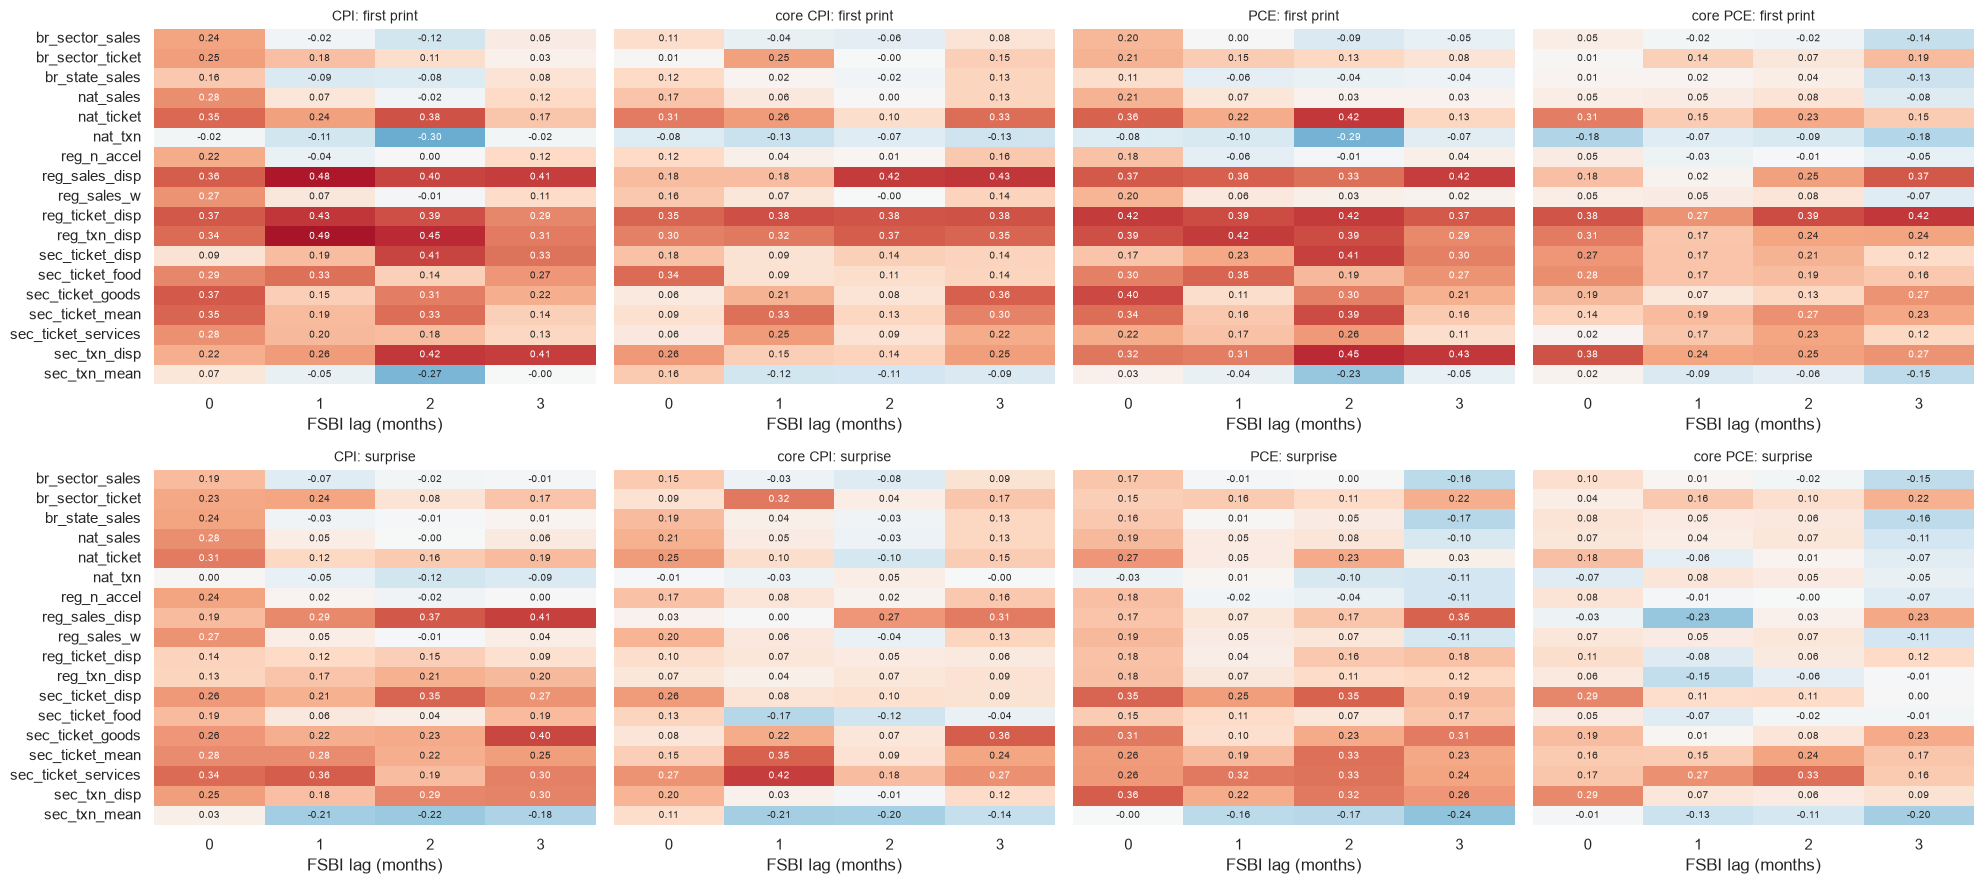

In [ ]:
from scipy import stats
LAG_LIST = (0, 1, 2, 3)
dev = lambda s: s.loc[~in_covid(s.index) & (s.index < HOLDOUT_START)]
def corr_dev(a, b, min_n=24):
    pair = dev(pd.concat([a, b], axis=1).dropna())
    return (pair.corr().iloc[0, 1], len(pair)) if len(pair) >= min_n else (np.nan, len(pair))
def lag_corr(X, y, lags=LAG_LIST, min_n=24):
    out = {}
    for c in X.columns:
        for l in lags:
            pair = pd.concat([X[c].shift(l), y], axis=1).dropna()
            pair = pair.loc[~in_covid(pair.index) & (pair.index < HOLDOUT_START)]
            out[(c, l)] = (pair.corr().iloc[0, 1], len(pair)) if len(pair) >= min_n else (np.nan, len(pair))
    return pd.DataFrame(out, index=["r", "n"]).T

FSBI_X = pd.concat([F["nat"], F["sec"], F["reg"]], axis=1)
corr_all = {}
for k in TARGETS:
    for kind, y in (("first print", Y[k]), ("surprise", Y[k] - NC[k])):
        t = lag_corr(FSBI_X, y); corr_all[(k, kind)] = t
n_tests = sum(t["r"].notna().sum() for t in corr_all.values())
n_med = int(np.median([t["n"].median() for t in corr_all.values()]))
def r_crit(alpha, n):
    tc = stats.t.ppf(1 - alpha / 2, n - 2); return tc / np.sqrt(n - 2 + tc ** 2)
print(f"{n_tests} correlations, about {n_med} months each: |r| > {r_crit(0.05, n_med):.2f} is nominally significant at 5%; "
      f"after the Bonferroni adjustment for {n_tests} tests the bar is |r| > {r_crit(0.05 / n_tests, n_med):.2f}.")

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey=True)
for j, k in enumerate(TARGETS):
    for i, kind in enumerate(("first print", "surprise")):
        M = corr_all[(k, kind)]["r"].unstack()
        sns.heatmap(M, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, cbar=False, ax=axes[i, j], annot_kws={"size": 7})
        axes[i, j].set_title(f"{LABEL[k]}: {kind}", fontsize=10); axes[i, j].set_xlabel("FSBI lag (months)"); axes[i, j].set_ylabel("")
plt.tight_layout();
top = pd.concat({key: t for key, t in corr_all.items()}, names=["target", "definition", "feature", "lag"]).reset_index()
top["p"] = 2 * stats.t.sf(np.abs(top.r * np.sqrt((top.n - 2) / (1 - top.r ** 2))), top.n - 2); top["adjusted p"] = (top.p * n_tests).clip(upper=1)
print("Strongest correlations (adjusted p = Bonferroni over all tests):")
display(top.reindex(top.r.abs().sort_values(ascending=False).index).head(12).round(3))

### 2.3 Sector series and the target

The same question for the 13 sectors and the subsectors of the national FSBI: whether a sector's **transaction** growth (volume) or **ticket** growth (price per purchase) lines up with inflation in the same month and the next. Ticket growth in sectors whose prices enter the index (restaurants, health care, personal services) is the natural candidate for core inflation; volume is the natural candidate for the nowcast surprise (demand the nowcast has not seen).

624 sector correlations; 2 exceed the Bonferroni bar (|r| > 0.51), 68 exceed the unadjusted 5% bar (about 31 expected by chance).


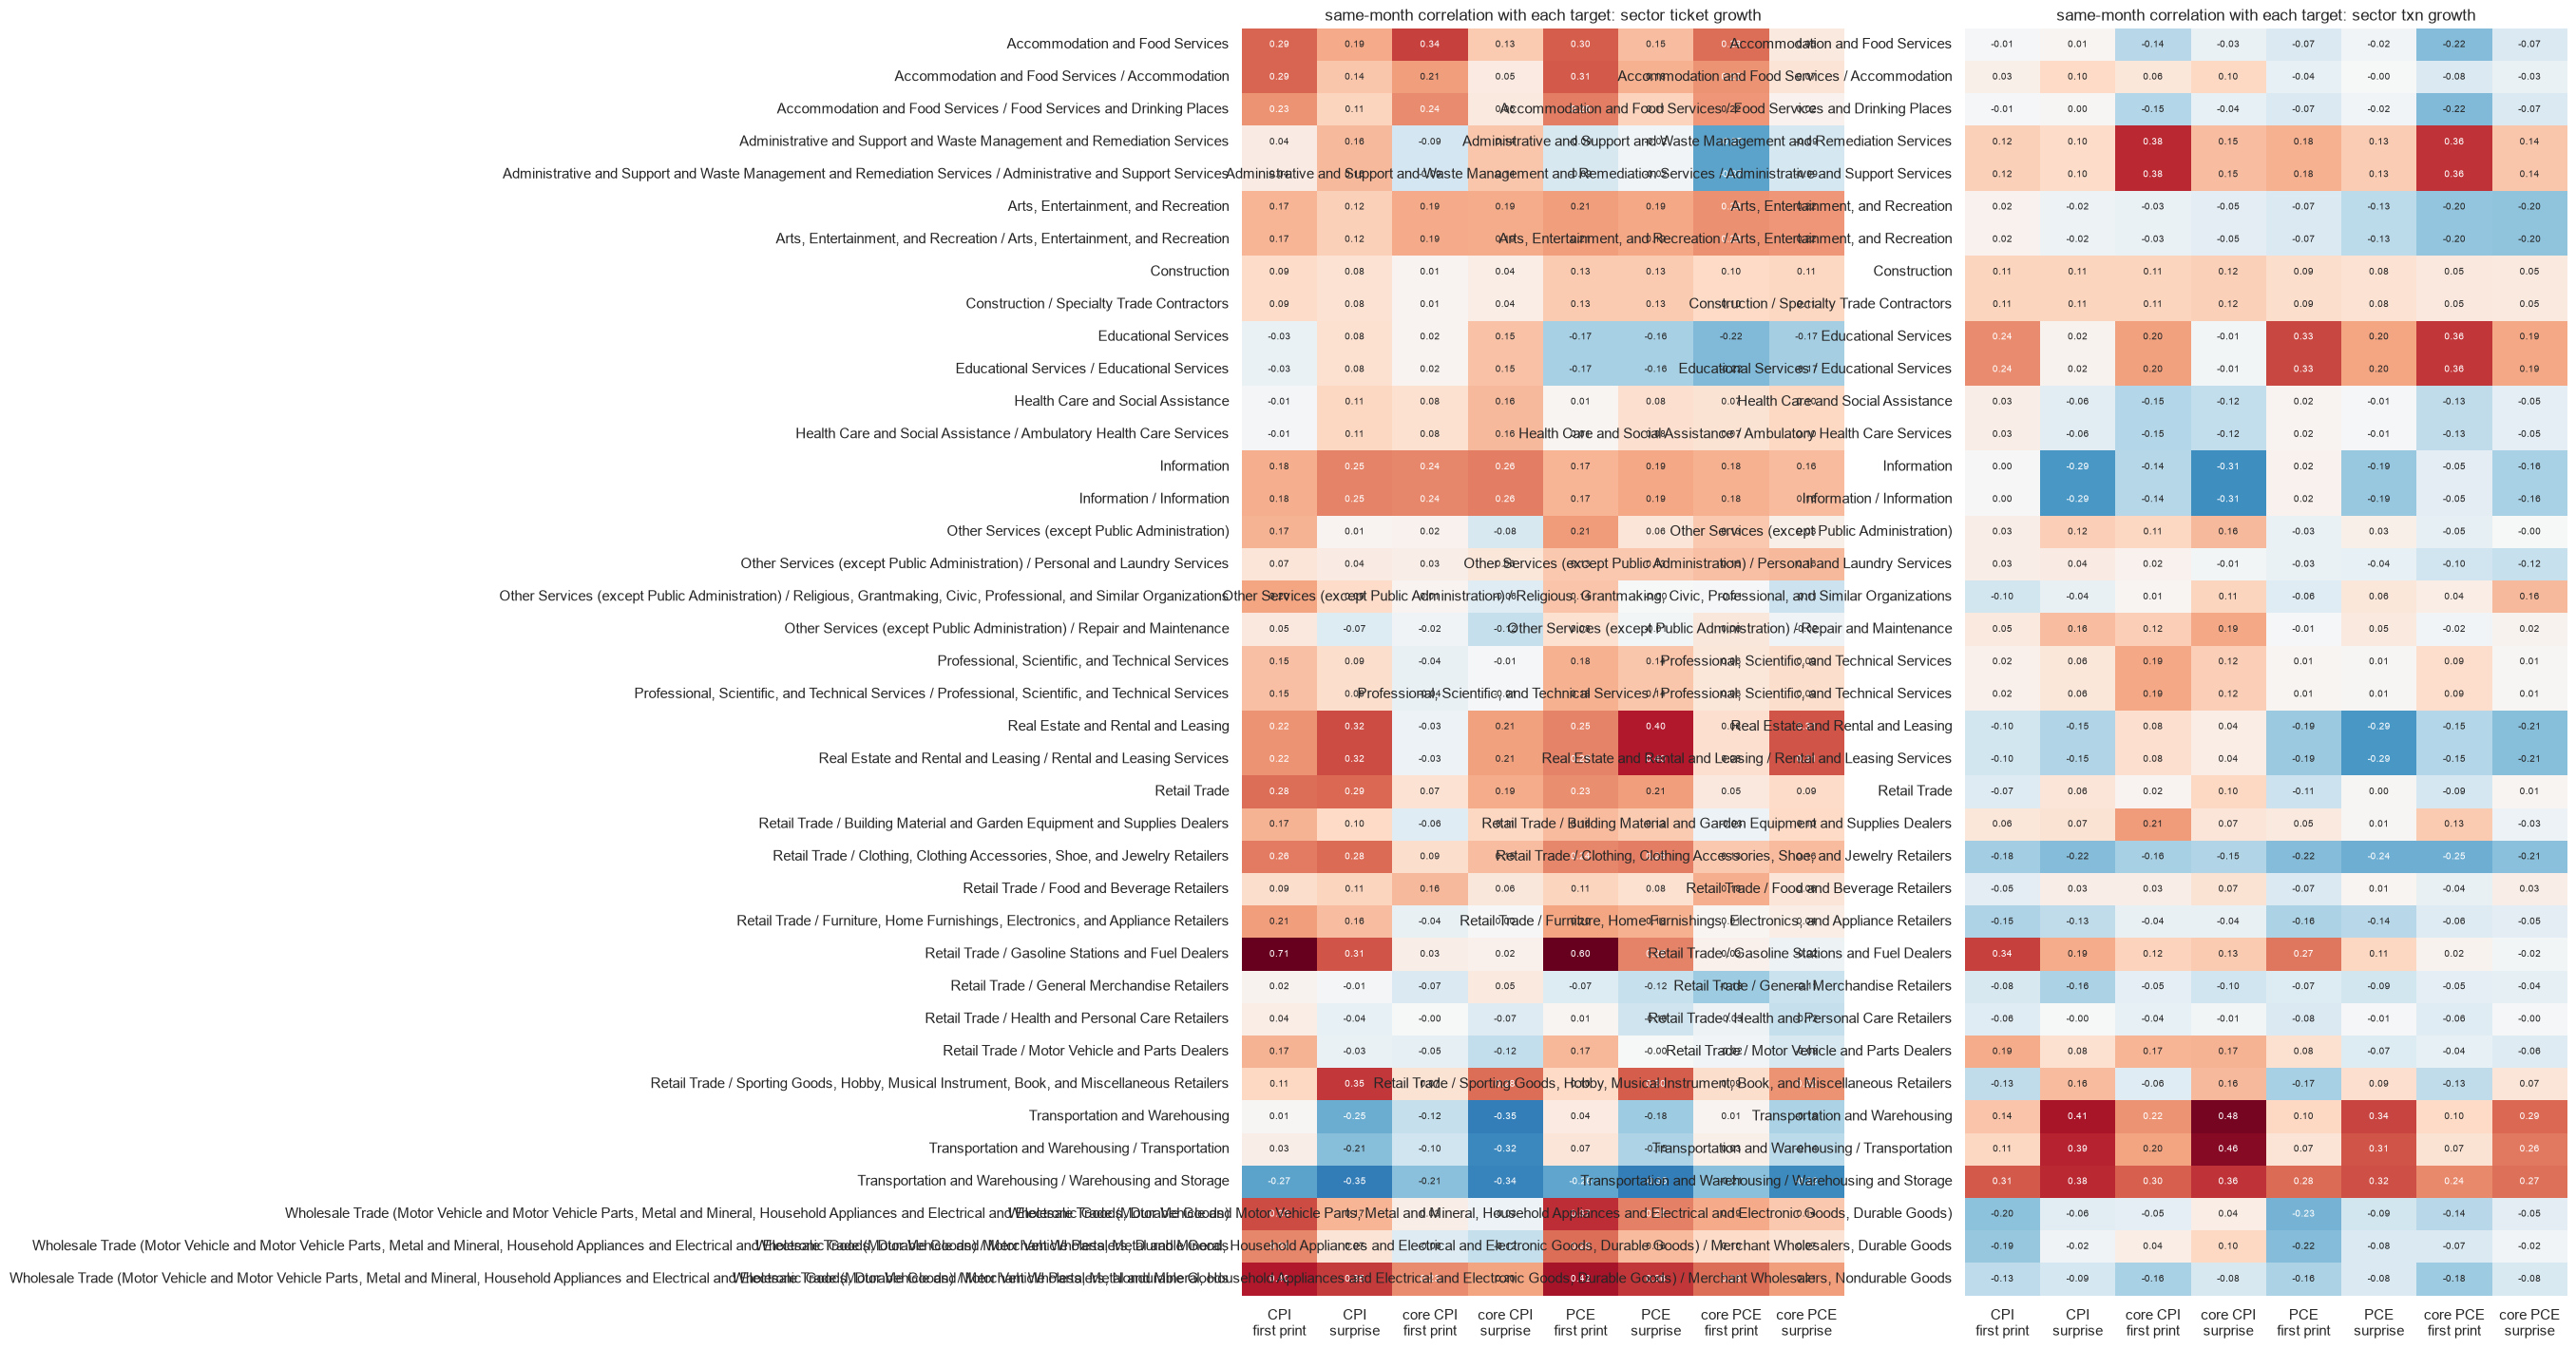

In [ ]:
ent_corr = {}
for k in TARGETS:
    for kind, y in (("first print", Y[k]), ("surprise", Y[k] - NC[k])):
        for metric in ("ticket", "txn"):
            t = lag_corr(G_ENT[metric], y, lags=(0, 1))
            ent_corr[(LABEL[k], kind, metric)] = t["r"].unstack()
fig, axes = plt.subplots(1, 2, figsize=(18, 0.38 * len(G_ENT["ticket"].columns) + 2.5))
for ax, metric in zip(axes, ("ticket", "txn")):
    M = pd.concat({(a, b): v[0] for (a, b, m), v in ent_corr.items() if m == metric}, axis=1)
    M.columns = [f"{a}\n{b}" for a, b in M.columns]
    sns.heatmap(M, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, cbar=False, ax=ax, annot_kws={"size": 7})
    ax.set_title(f"same-month correlation with each target: sector {metric} growth"); ax.set_ylabel("")
plt.tight_layout()
flat = pd.concat({f"{a} | {b} | {m}": v[0] for (a, b, m), v in ent_corr.items()}, axis=1).stack()
print(f"{len(flat)} sector correlations; {int((flat.abs() > r_crit(0.05 / len(flat), n_med)).sum())} exceed the Bonferroni bar (|r| > {r_crit(0.05 / len(flat), n_med):.2f}), "
      f"{int((flat.abs() > r_crit(0.05, n_med)).sum())} exceed the unadjusted 5% bar (about {0.05 * len(flat):.0f} expected by chance).")

### 2.4 The noise the targets themselves impose

Part of every forecast error cannot be reduced by any model. Three pieces are measured here from data; others (FSBI sampling noise, market noise) are in section 6.

- **Rounding.** CPI and PCE are published to one decimal; a published 0.3 can be anything from 0.25 to 0.35. The standard deviation of that rounding error is 0.1/√12 ≈ 0.029pp.
- **Revisions.** The target here is the *first* print, so revisions to it do not matter for the score, but they do for anyone comparing with today's revised series: the table shows how far the first print is from the current vintage.
- **What is left.** Dividing the rounding variance by the baseline's mean squared error shows how much of today's baseline error is irreducible rounding.

In [ ]:
noise = {}
for k in TARGETS:
    v = vintages(FRED_SA[k]); latest = v.sort_values("realtime_start").groupby("date").value.last()
    latest_mom = (latest / latest.shift(1) - 1) * 100
    rev = (latest_mom.reindex(IDX) - Y[k]).dropna(); rev = rev.loc[~in_covid(rev.index) & (rev.index < HOLDOUT_START)]
    mse_nc = np.mean(np.square((Y[k] - NC[k]).reindex(OOS[k])))
    noise[LABEL[k]] = {"rounding sd (pp)": 0.1 / np.sqrt(12), "revision RMS: first print vs today (pp)": float(np.sqrt((rev ** 2).mean())),
                       "baseline RMSE (pp)": float(np.sqrt(mse_nc)), "share of baseline MSE that is rounding": (0.1 ** 2 / 12) / mse_nc}
display(pd.DataFrame(noise).T.round(3))

,rounding sd (pp),revision RMS: first print vs today (pp),baseline RMSE (pp),share of baseline MSE that is rounding
CPI,0.029,0.073,0.148,0.038
core CPI,0.029,0.052,0.123,0.055
PCE,0.029,0.074,0.130,0.049
core PCE,0.029,0.072,0.123,0.055


## 3. National forecasts: CPI, core CPI, PCE, core PCE

**Two formulations.** *Track A* predicts the first print directly. *Track B* predicts the **surprise**, the first print minus the Cleveland nowcast, and the forecast is `nowcast + predicted surprise`: the model only has to explain what the nowcast misses, which is the question that matters ("does FSBI add to what is already public?"). Both are scored as forecasts of the first print.

**Protocol.** Expanding-window walk-forward: for each month after the first `MIN_TRAIN`, fit on earlier months only and predict that month. Inputs that may be missing (the Kalshi level before Dec 2022) are imputed with the training-window median inside each fit; everything else is complete-case on the common rows. Scores: RMSE (pp), the ratio to the nowcast's RMSE, R² against the nowcast, and a Diebold–Mariano p-value for equal squared error with HAC errors (small p with ratio < 1: the model is reliably better). With about 28 out-of-sample months the tests have limited power, so the ratio's size and its consistency across targets matter as much as any single p-value.

### 3.1 The engine

In [ ]:
CORE_COLS = ("y", "base", "actual", "nowcast")
def feature_cols(tbl):
    return [c for c in tbl.columns if c not in CORE_COLS]
_imp = lambda: SimpleImputer(strategy="median", keep_empty_features=True)          # fitted on the training window only
def _clip5(X):
    return np.clip(X, -5, 5)
CLIP = lambda: FunctionTransformer(_clip5)        # winsorise standardised inputs: a column that is constant except for a row or two cannot explode
KAL_COLS, MIN_KAL = ("kal_level", "kal_gap"), 8
def usable(train, cols):
    """Kalshi inputs enter a fit only once the training window holds MIN_KAL real Kalshi observations (before that they are all-zero or imputed)."""
    if "kal_level" in train and train["kal_level"].notna().sum() < MIN_KAL:
        return [c for c in cols if c not in KAL_COLS]
    return cols
def cv_mse(make, X, y, splits=4):
    errs = []
    for tr, te in TimeSeriesSplit(n_splits=splits).split(X):
        errs.append(np.mean((y.iloc[te] - make().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])) ** 2))
    return float(np.mean(errs))
SPARSE_BASE = {"kal_gap", "nat_txn", "nat_ticket", "sec_ticket_mean", "reg_sales_w"}
def sparse_cols(cols):
    """The few inputs used by the low-dimensional models: Kalshi gap and the headline FSBI series, at lag 0 (or their 3-month average)."""
    return [c for c in cols if re.sub(r"_(l\d|ma3)$", "", c) in SPARSE_BASE and not re.search(r"_l\d$", c)]

def reference_forecast(col):
    """Reference forecast read from a column; returns the amount to add to `base` to reach it."""
    return lambda train, test: float(test[col].iloc[0] - test.base.iloc[0])
def pipe_model(cols, est):
    def fp(train, test):
        cs = usable(train, cols)
        if not cs:
            return float(train.y.mean())
        m = make_pipeline(_imp(), StandardScaler(), CLIP(), est()).fit(train[cs], train.y)
        return float(m.predict(test[cs])[0])
    return fp
def ols_model(cols):
    return pipe_model(cols, lambda: LinearRegression()) if cols else (lambda tr, te: float(tr.y.mean()))
def ridge_model(cols):
    return pipe_model(cols, lambda: RidgeCV(alphas=np.logspace(-1, 4, 30)))
def lasso_model(cols_all, max_inputs=5, record=None):
    alphas = np.logspace(-3.5, -0.5, 25)
    def fp(train, test):
        cols = usable(train, cols_all)
        make = lambda a: make_pipeline(_imp(), StandardScaler(), CLIP(), Lasso(alpha=a, max_iter=20000))
        ok = [a for a in alphas if np.count_nonzero(make(a).fit(train[cols], train.y)[-1].coef_) <= max_inputs] or [alphas[-1]]
        a = min(ok, key=lambda a: cv_mse(lambda: make(a), train[cols], train.y))
        m = make(a).fit(train[cols], train.y)
        if record is not None:
            record.extend(c for c, b in zip(cols, m[-1].coef_) if b != 0)
        return float(m.predict(test[cols])[0])
    return fp
def pcr_model(cols, k=3):
    return pipe_model(cols, lambda: make_pipeline(PCA(n_components=min(k, len(cols))), LinearRegression()))
def rf_model(cols):
    return pipe_model(cols, lambda: RandomForestRegressor(n_estimators=60 if FAST else 200, min_samples_leaf=4, max_features=0.4, random_state=SEED, n_jobs=1))
def xgb_model(cols):
    def fp(train, test):
        cs = usable(train, cols)
        m = XGBRegressor(n_estimators=60 if FAST else 120, max_depth=2, learning_rate=0.05, subsample=0.8, min_child_weight=3, random_state=SEED, n_jobs=1)
        return float(m.fit(train[cs], train.y).predict(test[cs])[0])
    return fp
def mlp_model(cols, seeds=5):
    def fp(train, test):
        preds, cs = [], usable(train, cols)
        for s in range(2 if FAST else seeds):
            net = make_pipeline(_imp(), StandardScaler(), CLIP(), MLPRegressor(hidden_layer_sizes=(6,), activation="tanh", alpha=1.0, max_iter=600, random_state=SEED + s))
            preds.append(TransformedTargetRegressor(regressor=net, transformer=StandardScaler()).fit(train[cs], train.y).predict(test[cs])[0])
        return float(np.mean(preds))
    return fp
def arimax_model(cols):
    ex_all = sparse_cols(cols)
    def fp(train, test):
        ex = [c for c in ex_all if c in usable(train, ex_all)]
        idx = pd.date_range(train.index[0], test.index[0], freq="MS")                  # COVID gap and the test month are left missing
        mu, sd = train[ex].mean(), train[ex].std().replace(0, 1)
        X = ((pd.concat([train, test])[ex] - mu) / sd).clip(-5, 5).reindex(idx).fillna(0) if ex else None
        return float(SARIMAX(train.y.reindex(idx), exog=X, order=(1, 0, 1), trend="c").fit(disp=False).fittedvalues.iloc[-1])
    return fp
def ar_model(cols):
    own = [c for c in cols if c in ("y_l1", "y_l2", "sur_l1")]
    return ols_model(own)

def zoo(cols, lasso_record=None, heavy=True):
    m = {"Nowcast": reference_forecast("nowcast"), "Last month": reference_forecast("y_l1"), "AR": ar_model(cols), "OLS sparse": ols_model(sparse_cols(cols) + [c for c in cols if c == "y_l1"]),
         "ARIMAX(1,0,1)": arimax_model(cols), "Ridge": ridge_model(cols), "Lasso (<=5)": lasso_model(cols, record=lasso_record), "PCR (3)": pcr_model(cols)}
    if heavy:
        m.update({"Random forest": rf_model(cols), "XGBoost": xgb_model(cols), "Neural net (6, x5)": mlp_model(cols)})
    return m

def walk_forward(tbl, models, start=MIN_TRAIN):
    if len(tbl) <= start:
        raise ValueError(f"Too few rows for walk-forward evaluation: {len(tbl)} rows, start {start}.")
    rows = []
    for i in range(start, len(tbl)):
        train, test = tbl.iloc[:i], tbl.iloc[[i]]
        row = {"actual": test.actual.iloc[0], "nowcast": test.nowcast.iloc[0]}
        for name, fit_predict in models.items():
            row[name] = test.base.iloc[0] + fit_predict(train, test)
        rows.append(pd.Series(row, name=tbl.index[i]))
    return pd.DataFrame(rows)

def score_frame(f, names=None, reference="Nowcast"):
    names = names or [c for c in f if c not in ("actual", "nowcast")]
    e_ref = f.actual - f[reference]; out = {}
    for m in names:
        e = f.actual - f[m]
        out[m] = {"RMSE": rmse(e), "MAE": e.abs().mean(), "RMSE / nowcast": rmse(e) / rmse(e_ref), "R2 vs nowcast": 1 - (e ** 2).sum() / (e_ref ** 2).sum(),
                  "DM p vs nowcast": np.nan if m == reference else hac_p(e ** 2 - e_ref ** 2), "hits 0.1 bucket": float((f[m].round(1) == f.actual.round(1)).mean())}
    return pd.DataFrame(out).T
print("engine ready:", ", ".join(zoo(["kal_gap"], heavy=True)))

engine ready: Nowcast, Last month, AR, OLS sparse, ARIMAX(1,0,1), Ridge, Lasso (<=5), PCR (3), Random forest, XGBoost, Neural net (6, x5)


### 3.2 Screening: which feature sets and lags carry information?

One fast model (ridge regression with its penalty chosen by leave-one-out inside each training window) on **every** feature set S0–S5 and lag treatment, for all four targets and both formulations, on the identical common rows. A cell is the ridge RMSE divided by the nowcast's RMSE on the same months: **below 1 beats the nowcast**. Ridge is used because it can take a hundred correlated inputs from a few dozen rows without selecting among them; it measures how much information a block adds rather than how well a clever model exploits it.

Reading the grid: look for *patterns* (does adding FSBI blocks lower the ratio? does a lag help consistently across targets?) rather than the single lowest cell, which is partly selection luck among 24 cells per panel.

Best lag treatment for the full feature set (S5) by ridge, per target and track:


lag  n_features   n   RMSE  RMSE / nowcast  DM p vs nowcast
target   track                                                              
core_cpi A       L01          75  28  0.099           0.803            0.153
         B       MA3          57  28  0.121           0.980            0.690
core_pce A        L0          57  28  0.109           0.881            0.145
         B      L012          93  28  0.121           0.984            0.618
cpi      A       L01          75  28  0.177           1.198            0.332
         B       MA3          57  28  0.135           0.914            0.400
pce      A       L01          75  28  0.144           1.104            0.525
         B       MA3          57  28  0.124           0.950            0.321

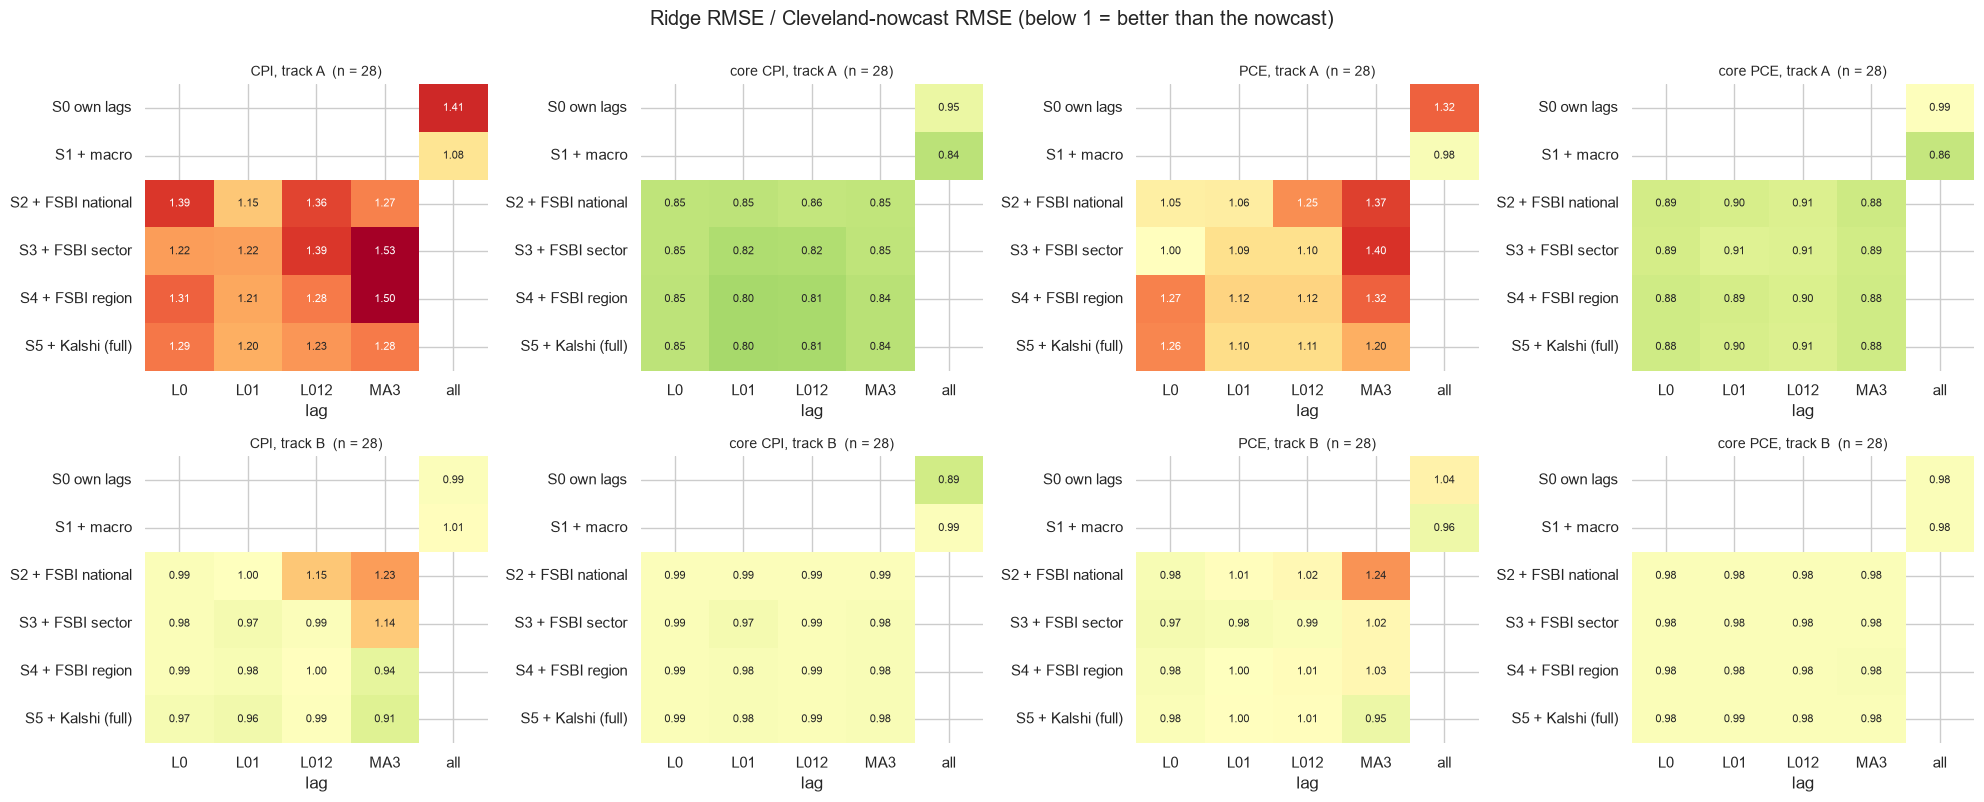

In [ ]:
screen_rows = []
for k in TARGETS:
    for track in ("A", "B"):
        for sname, blocks in SETS.items():
            for lag in (LAGS if any(b in FSBI_BLOCKS for b in blocks) else ["L0"]):
                tbl = model_table(k, blocks, lag, track, rows=ROWS[k]); cols = feature_cols(tbl)
                f = walk_forward(tbl, {"Nowcast": reference_forecast("nowcast"), "Ridge": ridge_model(cols)})
                sc = score_frame(f, ["Ridge"])
                screen_rows.append({"target": k, "track": track, "set": sname, "lag": lag, "n_features": len(cols), "n": len(f), **sc.loc["Ridge"]})
SCREEN = pd.DataFrame(screen_rows)
SCREEN.loc[SCREEN.set.isin(["S0 own lags", "S1 + macro"]), "lag"] = "all"            # no FSBI block: lag treatment does not apply
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, k in enumerate(TARGETS):
    for i, track in enumerate(("A", "B")):
        sub = SCREEN[(SCREEN.target == k) & (SCREEN.track == track)]
        M = sub.pivot_table(index="set", columns="lag", values="RMSE / nowcast").reindex(index=list(SETS))
        sns.heatmap(M, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1.0, vmin=0.6, vmax=1.5, cbar=False, ax=axes[i, j], annot_kws={"size": 8})
        axes[i, j].set_title(f"{LABEL[k]}, track {track}  (n = {int(sub.n.iloc[0])})", fontsize=10); axes[i, j].set_ylabel("")
plt.suptitle("Ridge RMSE / Cleveland-nowcast RMSE (below 1 = better than the nowcast)", y=1.0); plt.tight_layout();
best = SCREEN.loc[SCREEN[SCREEN.set == "S5 + Kalshi (full)"].groupby(["target", "track"])["RMSE / nowcast"].idxmin()]
print("Best lag treatment for the full feature set (S5) by ridge, per target and track:")
display(best[["target", "track", "lag", "n_features", "n", "RMSE", "RMSE / nowcast", "DM p vs nowcast"]].set_index(["target", "track"]).round(3))
LAG_CHOICE = {(r.target, r.track): r.lag for r in best.itertuples()}

### 3.3 The model zoo on the full feature set

Every model uses the full feature set (own lags, macro, FSBI national, sector and region, Kalshi) at the lag treatment chosen above, so each has FSBI, FRED macro and Kalshi as inputs, the minimum Fiserv asked for. The models:

- **Time series**: *AR* (own lags and previous surprise), *ARIMAX(1,0,1)* with the headline FSBI series and the Kalshi gap as exogenous inputs.
- **Linear**: *OLS sparse* (Kalshi gap, national FSBI transactions and ticket, sector ticket, regional sales, last month), *Ridge* on everything, *Lasso* limited to five inputs, *PCR* on three principal components.
- **Machine learning**: *random forest*, *XGBoost* (shallow, fixed settings), and a *neural net* (one hidden layer of 6 tanh units, strong L2 penalty, averaged over five seeds). With a few dozen training rows these have far more capacity than information, which is why tree and network settings are fixed and conservative instead of tuned.

References: the Cleveland nowcast, last month's first print, and Kalshi where it exists for the target. The configuration (lag treatment) was picked from the same out-of-sample months as the scores, so these results are slightly optimistic; the holdout is the clean test.

In [ ]:
OOS_F, PICKS = {}, {}
t0 = time.time()
for k in TARGETS:
    for track in ("A", "B"):
        lag = LAG_CHOICE[(k, track)]
        tbl = model_table(k, ABLATE["full"], lag, track, rows=ROWS[k]); cols = feature_cols(tbl)
        rec = []
        f = walk_forward(tbl, zoo(cols, lasso_record=rec))
        if k in KAL_MAIN:
            f["Kalshi implied"] = KAL_MAIN[k].reindex(f.index)
        OOS_F[(k, track)] = f; PICKS[(k, track)] = pd.Series(rec).value_counts() / len(f)
    print(f"  {LABEL[k]} done ({time.time() - t0:.0f}s)")
for k in TARGETS:
    f = {t: OOS_F[(k, t)] for t in ("A", "B")}
    model_names = [c for c in f["B"] if c not in ("actual", "nowcast", "Nowcast", "Last month", "Kalshi implied")]
    parts = []
    for t in ("A", "B"):
        sc = score_frame(f[t], model_names); sc.index = [f"{m} [{t}]" for m in sc.index]; parts.append(sc)
    tab = pd.concat(parts).sort_values("RMSE")
    refs = score_frame(f["B"], [r for r in ("Nowcast", "Last month", "Kalshi implied") if r in f["B"]])
    print(f"\n{LABEL[k]}: {len(f['B'])} out-of-sample months. Models, then the references (nowcast, last month, Kalshi):")
    display(pd.concat([tab, refs]).round(3))

  CPI done (102s)
  core CPI done (207s)
  PCE done (310s)
  core PCE done (413s)

CPI: 28 out-of-sample months. Models, then the references (nowcast, last month, Kalshi):


,RMSE,MAE,RMSE / nowcast,R2 vs nowcast,DM p vs nowcast,hits 0.1 bucket
Lasso (<=5) [A],0.116,0.099,0.787,0.380,0.231,0.179
AR [B],0.128,0.100,0.863,0.255,0.141,0.250
PCR (3) [B],0.130,0.104,0.881,0.224,0.220,0.214
"Neural net (6, x5) [B]",0.135,0.117,0.912,0.168,0.566,0.179
Ridge [B],0.135,0.107,0.914,0.164,0.400,0.250
Random forest [B],0.137,0.111,0.924,0.146,0.480,0.321
XGBoost [B],0.139,0.114,0.942,0.113,0.682,0.321
OLS sparse [B],0.148,0.116,1.004,-0.007,0.972,0.250
Lasso (<=5) [B],0.150,0.117,1.016,-0.031,0.826,0.286
Random forest [A],0.164,0.135,1.105,-0.222,0.217,0.250



core CPI: 28 out-of-sample months. Models, then the references (nowcast, last month, Kalshi):


,RMSE,MAE,RMSE / nowcast,R2 vs nowcast,DM p vs nowcast,hits 0.1 bucket
PCR (3) [A],0.097,0.080,0.790,0.377,0.137,0.286
Ridge [A],0.099,0.081,0.803,0.355,0.153,0.393
OLS sparse [A],0.099,0.077,0.806,0.351,0.268,0.357
Random forest [A],0.103,0.077,0.838,0.298,0.111,0.429
XGBoost [A],0.108,0.084,0.875,0.235,0.262,0.393
"ARIMAX(1,0,1) [A]",0.111,0.077,0.902,0.186,0.513,0.571
Lasso (<=5) [A],0.112,0.089,0.906,0.178,0.517,0.357
AR [B],0.112,0.080,0.907,0.178,0.229,0.429
PCR (3) [B],0.114,0.084,0.925,0.144,0.181,0.393
AR [A],0.118,0.085,0.956,0.086,0.522,0.429



PCE: 28 out-of-sample months. Models, then the references (nowcast, last month, Kalshi):


,RMSE,MAE,RMSE / nowcast,R2 vs nowcast,DM p vs nowcast,hits 0.1 bucket
Lasso (<=5) [A],0.120,0.094,0.918,0.158,0.471,0.321
"Neural net (6, x5) [B]",0.121,0.103,0.929,0.136,0.506,0.321
Ridge [B],0.124,0.098,0.950,0.098,0.321,0.357
PCR (3) [B],0.124,0.104,0.953,0.092,0.309,0.214
OLS sparse [B],0.128,0.107,0.979,0.041,0.834,0.357
Random forest [B],0.132,0.107,1.014,-0.029,0.731,0.250
Lasso (<=5) [B],0.133,0.111,1.018,-0.037,0.608,0.214
XGBoost [B],0.134,0.107,1.026,-0.053,0.793,0.286
"ARIMAX(1,0,1) [B]",0.134,0.103,1.027,-0.055,0.829,0.321
AR [B],0.139,0.113,1.064,-0.132,0.272,0.357



core PCE: 28 out-of-sample months. Models, then the references (nowcast, last month, Kalshi):


,RMSE,MAE,RMSE / nowcast,R2 vs nowcast,DM p vs nowcast,hits 0.1 bucket
Random forest [A],0.109,0.084,0.881,0.224,0.292,0.429
Ridge [A],0.109,0.085,0.881,0.223,0.145,0.393
PCR (3) [A],0.116,0.090,0.943,0.111,0.619,0.286
XGBoost [B],0.119,0.100,0.968,0.062,0.487,0.250
PCR (3) [B],0.121,0.099,0.980,0.040,0.526,0.286
Ridge [B],0.121,0.101,0.984,0.033,0.618,0.250
Lasso (<=5) [B],0.121,0.101,0.984,0.031,0.630,0.250
XGBoost [A],0.122,0.092,0.989,0.023,0.938,0.321
AR [A],0.122,0.098,0.990,0.021,0.758,0.286
Random forest [B],0.122,0.101,0.990,0.019,0.837,0.286


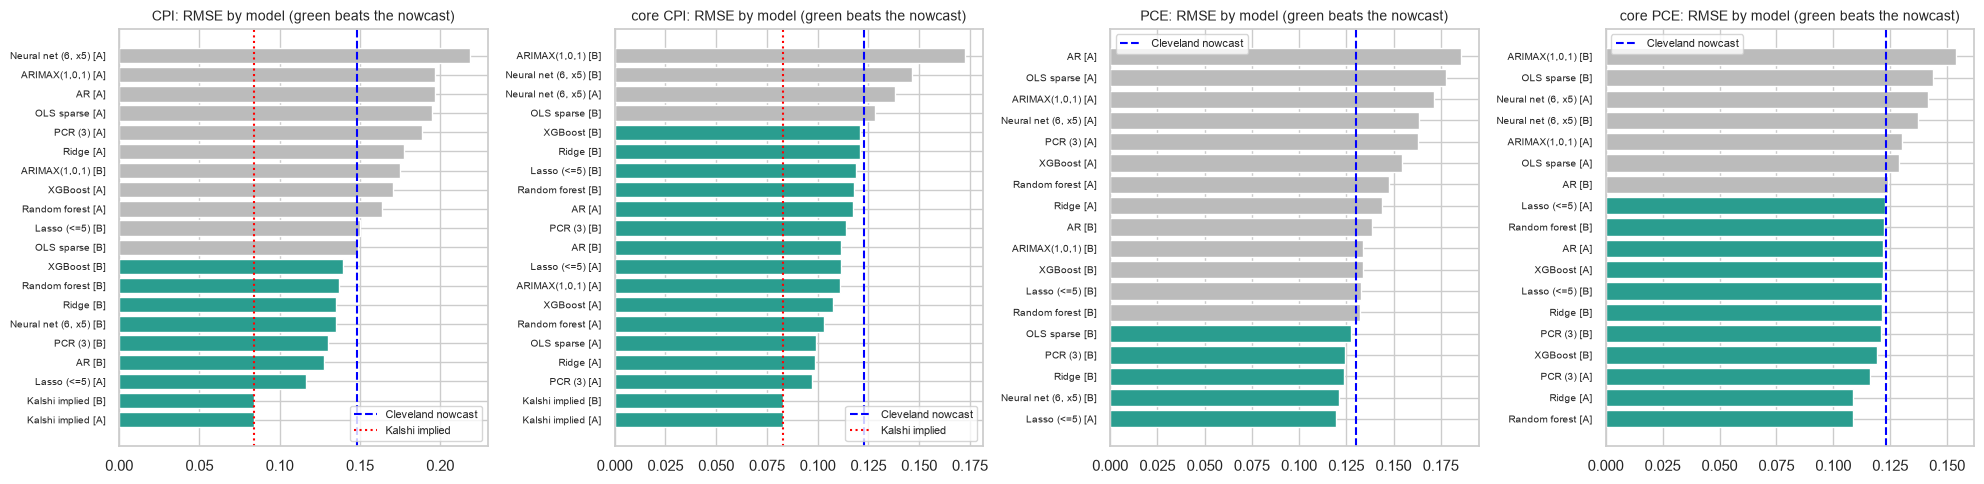

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=False)
for ax, k in zip(axes, TARGETS):
    f = pd.concat({t: OOS_F[(k, t)] for t in ("A", "B")}, axis=1)
    names = [c for c in OOS_F[(k, "B")] if c not in ("actual", "nowcast", "Nowcast", "Last month")]
    r = pd.Series({f"{m} [{t}]": rmse(OOS_F[(k, t)].actual - OOS_F[(k, t)][m]) for t in ("A", "B") for m in names if m in OOS_F[(k, t)]}).sort_values()
    base_r = rmse(OOS_F[(k, "B")].actual - OOS_F[(k, "B")].nowcast)
    colors = ["#2a9d8f" if v < base_r else "#bbbbbb" for v in r.values]
    ax.barh(r.index, r.values, color=colors); ax.axvline(base_r, color="blue", ls="--", lw=1.5, label="Cleveland nowcast")
    if k in KAL_MAIN:
        ax.axvline(rmse(OOS_F[(k, "B")].actual - OOS_F[(k, "B")]["Kalshi implied"]), color="red", ls=":", lw=1.5, label="Kalshi implied")
    ax.set_title(f"{LABEL[k]}: RMSE by model (green beats the nowcast)", fontsize=10); ax.legend(fontsize=8); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout();

### 3.4 Does FSBI help? Does Kalshi help? Block ablations

The central question for Fiserv, answered directly: take the full model and **remove one block at a time** (or keep only one), re-run the walk-forward on the identical rows, and compare with the full model. Three models, because a conclusion that only one model supports is a property of the model: ridge (uses everything), lasso (selects), random forest (nonlinear). Track B throughout, at the lag chosen above.

`Δ RMSE %` is the change in RMSE when the block is removed relative to the full model (**positive = the block was helping**); the p-value is a Diebold–Mariano test of equal squared error between the ablated and the full model. The last panel is the same comparison for the macro block, so FSBI's contribution can be read against a block everyone already uses.

Change in RMSE (%) relative to the full model when the block is removed or kept alone (positive = worse than full):


feature set             no FSBI  no macro  no Kalshi  FSBI only  Kalshi only  macro only
target   model                                                                          
CPI      Lasso (<=5)        1.1      -2.0        0.4        0.7         -2.9         1.6
         Random forest      5.9       2.6        0.8        3.9          5.6         6.1
         Ridge              7.6      -0.2        2.4        2.5          5.7         9.9
PCE      Lasso (<=5)        2.1      -3.9        0.0       -4.3          2.7         2.1
         Random forest     -0.5      -0.7       -0.3        1.0          3.4        -0.2
         Ridge             37.8       2.7        8.3        3.4          9.6         0.9
core CPI Lasso (<=5)        2.9      -0.3       -0.7       -0.1         -6.8         2.3
         Random forest      4.2      -2.8       -0.0       -1.9         -1.8         3.9
         Ridge              0.3      -4.0        0.2       -4.0         -8.3         1.1
core PCE Lasso (<=5)        0.3      -0.3        0.0       -0.5         -0.0         0.3
         Random forest     -2.7      -0.9        0.5       -0.3          2.8        -2.9
         Ridge              0.0       0.0        0.0        0.1          0.1         0.0

Summary: what removing each block does, averaged over the three models (positive = the block was helping):


mean change in RMSE (%) models worse without it  of those, DM p < 0.10
target   block removed                                                                        
CPI      FSBI                              4.84                  3 of 3                      0
         Kalshi                            1.22                  3 of 3                      1
         macro                             0.13                  1 of 3                      0
core CPI FSBI                              2.47                  3 of 3                      0
         Kalshi                           -0.20                  1 of 3                      0
         macro                            -2.39                  0 of 3                      0
PCE      FSBI                             13.15                  2 of 3                      0
         Kalshi                            2.67                  1 of 3                      0
         macro                            -0.64                  1 of 3                      0
core PCE FSBI                             -0.79                  2 of 3                      0
         Kalshi                            0.18                  2 of 3                      0
         macro                            -0.39                  1 of 3                      0

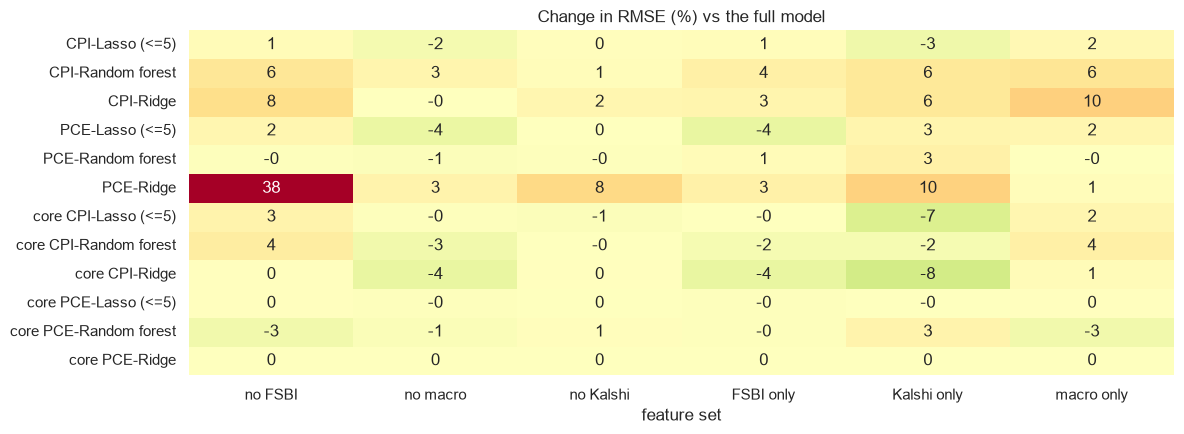

In [ ]:
ABL_MODELS = {"Ridge": ridge_model, "Lasso (<=5)": lasso_model, "Random forest": rf_model}
abl_rows, ABL_F = [], {}
for k in TARGETS:
    lag = LAG_CHOICE[(k, "B")]
    for set_name, blocks in ABLATE.items():
        tbl = model_table(k, blocks, lag, "B", rows=ROWS[k]); cols = feature_cols(tbl)
        f = walk_forward(tbl, {name: fn(cols) for name, fn in ABL_MODELS.items()})
        f["Nowcast"] = f["nowcast"]; ABL_F[(k, set_name)] = f
for k in TARGETS:
    for mname in ABL_MODELS:
        full = ABL_F[(k, "full")]
        for set_name in ABLATE:
            f = ABL_F[(k, set_name)]; e, e0 = f.actual - f[mname], full.actual - full[mname]
            abl_rows.append({"target": LABEL[k], "model": mname, "feature set": set_name, "RMSE": rmse(e), "RMSE / nowcast": rmse(e) / rmse(f.actual - f.nowcast),
                             "d RMSE % vs full": 100 * (rmse(e) / rmse(e0) - 1), "DM p vs full": np.nan if set_name == "full" else hac_p(e ** 2 - e0 ** 2)})
ABL = pd.DataFrame(abl_rows)
piv = ABL.pivot_table(index=["target", "model"], columns="feature set", values="d RMSE % vs full").reindex(columns=list(ABLATE))
print("Change in RMSE (%) relative to the full model when the block is removed or kept alone (positive = worse than full):")
display(piv.drop(columns="full").round(1))
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(piv.drop(columns="full"), annot=True, fmt=".0f", cmap="RdYlGn_r", center=0, cbar=False, ax=ax); ax.set_title("Change in RMSE (%) vs the full model"); ax.set_ylabel("")
plt.tight_layout()
summ = []
for k in TARGETS:
    for blk, label in (("no FSBI", "FSBI"), ("no Kalshi", "Kalshi"), ("no macro", "macro")):
        d = ABL[(ABL.target == LABEL[k]) & (ABL["feature set"] == blk)].set_index("model")["d RMSE % vs full"]
        p = ABL[(ABL.target == LABEL[k]) & (ABL["feature set"] == blk)].set_index("model")["DM p vs full"]
        summ.append({"target": LABEL[k], "block removed": label, "mean change in RMSE (%)": d.mean(), "models worse without it": f"{int((d > 0).sum())} of {len(d)}",
                     "of those, DM p < 0.10": int(((d > 0) & (p < 0.10)).sum())})
print("Summary: what removing each block does, averaged over the three models (positive = the block was helping):")
ABL_SUMMARY = pd.DataFrame(summ).set_index(["target", "block removed"])
display(ABL_SUMMARY.round(2))

### 3.5 Which FSBI inputs matter

How often each input survived the lasso (limited to five inputs) across the out-of-sample months: an input that is picked in most months is a stable signal; one picked now and then is noise the penalty happened to admit. Frequencies near 1 are rare with this much collinearity, so read relative frequency.

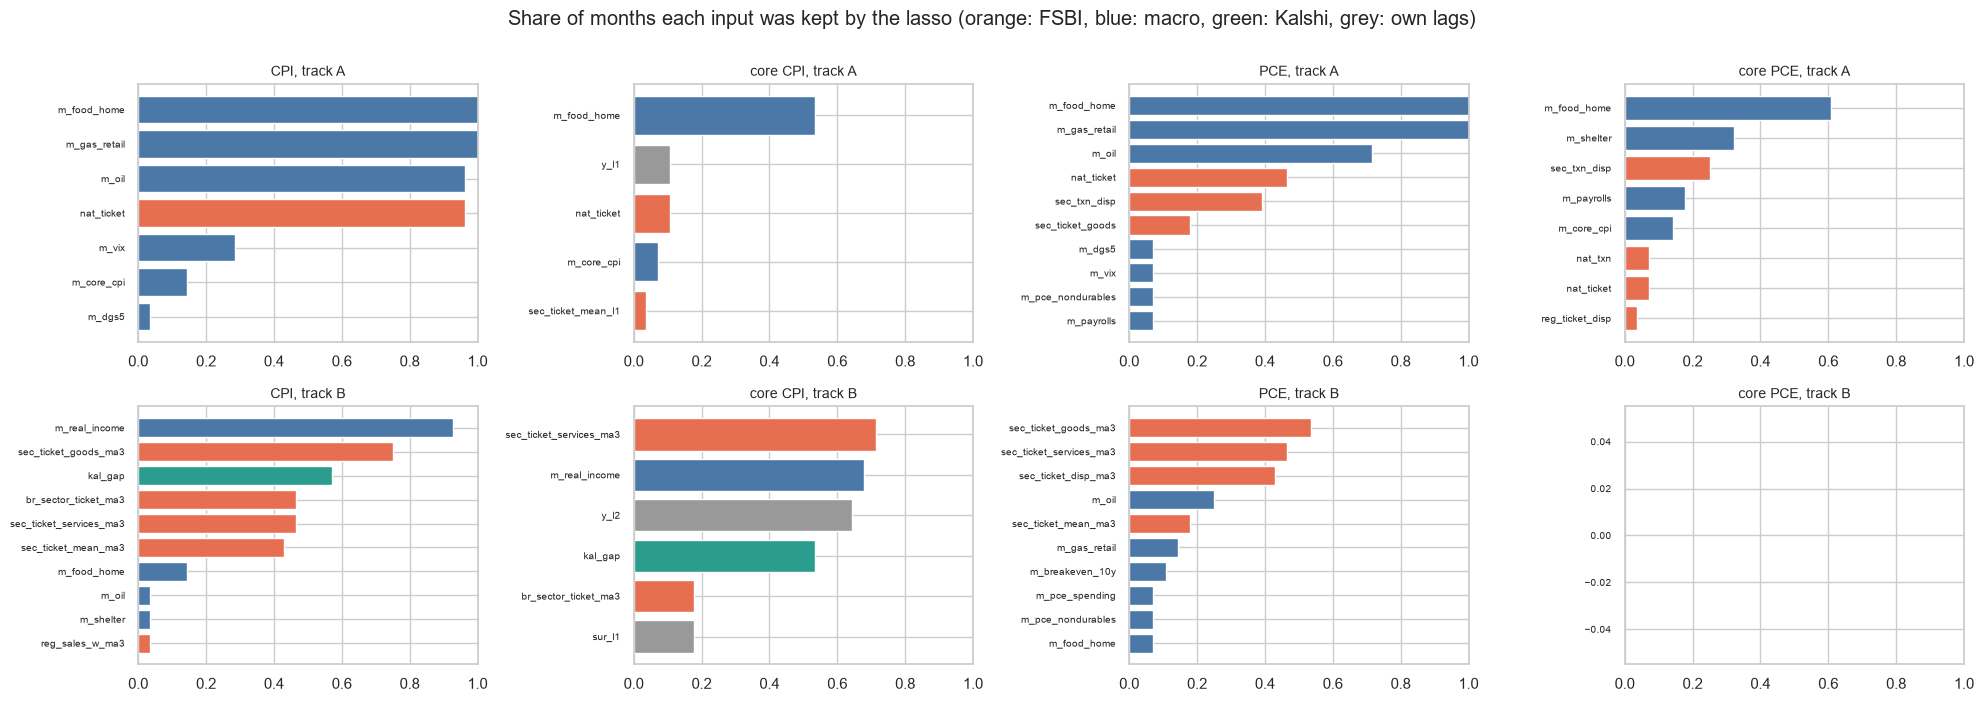

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for j, k in enumerate(TARGETS):
    for i, track in enumerate(("A", "B")):
        p = PICKS[(k, track)].head(10)
        axes[i, j].barh(p.index[::-1], p.values[::-1], color=["#e76f51" if c.startswith(("nat", "sec", "reg", "br_")) else "#4c78a8" if c.startswith("m_") else "#2a9d8f" if c.startswith("kal") else "#999999" for c in p.index[::-1]])
        axes[i, j].set_title(f"{LABEL[k]}, track {track}", fontsize=10); axes[i, j].set_xlim(0, 1); axes[i, j].tick_params(axis="y", labelsize=7)
plt.suptitle("Share of months each input was kept by the lasso (orange: FSBI, blue: macro, green: Kalshi, grey: own lags)", y=1.0); plt.tight_layout();

### 3.6 The same forecasts as year-on-year

Each month-on-month forecast goes through the bridge of section 1.4 and is scored against the *published* YoY (one decimal). The bridge adds the noise measured in 1.4 to every forecast alike, so comparisons between models stay valid; the absolute YoY errors include that floor.

In [ ]:
yoy_rows = {}
for k in TARGETS:
    f = OOS_F[(k, "B")]; pub = Y_YOY[k].reindex(f.index)
    cand_names = ["Nowcast", "Ridge", "Lasso (<=5)", "OLS sparse", "ARIMAX(1,0,1)", "Random forest", "XGBoost", "Neural net (6, x5)"] + (["Kalshi implied"] if k in KAL_MAIN else [])
    r = {m: rmse(bridge_yoy(f[m], k) - pub) for m in cand_names if m in f}
    r["last month's YoY"] = rmse(Y_YOY[k].shift(1).reindex(f.index) - pub)
    yoy_rows[LABEL[k]] = r
YOY_TAB = pd.DataFrame(yoy_rows)
print("YoY RMSE (pp), track B forecasts bridged to year-on-year, against the published YoY. Last row: carrying last month's YoY forward.")
display(YOY_TAB.round(3))

YoY RMSE (pp), track B forecasts bridged to year-on-year, against the published YoY. Last row: carrying last month's YoY forward.


,CPI,core CPI,PCE,core PCE
Nowcast,0.149,0.122,0.160,0.145
Ridge,0.136,0.117,0.154,0.145
Lasso (<=5),0.146,0.115,0.160,0.145
OLS sparse,0.152,0.120,0.156,0.168
"ARIMAX(1,0,1)",0.177,0.158,0.165,0.172
Random forest,0.142,0.119,0.161,0.147
XGBoost,0.151,0.129,0.158,0.145
"Neural net (6, x5)",0.136,0.152,0.145,0.162
Kalshi implied,0.112,0.108,NaN,NaN
last month's YoY,0.421,0.181,0.342,0.195


### 3.7 One forecast per target for the trading section

Trading needs a single forecast of each target each month, and picking the best model *in hindsight* would flatter it. The selection here is **online**: each month, use the candidate with the lowest squared error over the months *before* it (at least `MIN_SEL` of them). The candidates are the fitted models from both tracks that use FSBI, macro and Kalshi (the nowcast, Kalshi itself and plain AR are benchmarks, not candidates). The result is a forecast series that could have been produced in real time.

In [ ]:
MIN_SEL = 6
CANDIDATES = ["OLS sparse", "ARIMAX(1,0,1)", "Ridge", "Lasso (<=5)", "PCR (3)", "Random forest", "XGBoost", "Neural net (6, x5)"]
def online_select(cands, y, min_hist=MIN_SEL):
    """Each month, the candidate with the lowest mean squared error over the earlier months in which it had a forecast."""
    cands = cands.reindex(y.index); e2 = cands.sub(y, axis=0) ** 2
    n_prior = e2.notna().expanding().sum().shift(1)
    mse = (e2.expanding().sum().shift(1) / n_prior.where(n_prior >= min_hist)).where(cands.notna())
    pick = mse.apply(lambda r: r.idxmin() if r.notna().any() else np.nan, axis=1)
    return pd.Series({t: cands.loc[t, c] for t, c in pick.dropna().items()}, dtype=float).reindex(y.index), pick
SEL, SEL_NAME = {}, {}
for k in TARGETS:
    pool = pd.concat({f"{m} [{t}]": OOS_F[(k, t)][m] for t in ("A", "B") for m in CANDIDATES if m in OOS_F[(k, t)]}, axis=1)
    pool.columns = [c[0] if isinstance(c, tuple) else c for c in pool.columns]
    y = OOS_F[(k, "B")].actual
    SEL[k], SEL_NAME[k] = online_select(pool, y)
rows = {}
for k in TARGETS:
    f = OOS_F[(k, "B")]; ok = SEL[k].dropna().index
    e_sel, e_nc = (f.actual - SEL[k]).loc[ok], (f.actual - f.nowcast).loc[ok]
    rows[LABEL[k]] = {"months": len(ok), "online-selected RMSE": rmse(e_sel), "nowcast RMSE": rmse(e_nc), "ratio": rmse(e_sel) / rmse(e_nc), "DM p": hac_p(e_sel ** 2 - e_nc ** 2),
                      **({"Kalshi RMSE": rmse((f.actual - f["Kalshi implied"]).loc[ok])} if k in KAL_MAIN else {}), "most selected": SEL_NAME[k].value_counts().index[0] if SEL_NAME[k].notna().any() else "n/a"}
SEL_TABLE = pd.DataFrame(rows).T
display(SEL_TABLE)

,months,online-selected RMSE,nowcast RMSE,ratio,DM p,Kalshi RMSE,most selected
CPI,22,0.117305,0.111921,1.048103,0.772451,0.079538,Lasso (<=5) [A]
core CPI,22,0.117236,0.113711,1.031005,0.697904,0.085104,OLS sparse [A]
PCE,22,0.1287,0.10989,1.171173,0.115175,NaN,"Neural net (6, x5) [B]"
core PCE,22,0.108645,0.117029,0.928365,0.100526,NaN,Ridge [A]


In [ ]:
type(OOS_F)

dict

## 4. Regional inflation

Three questions. (1) Which region- and sector-specific FSBI movements line up with which regional CPI movements? (2) Does regional FSBI forecast **regional** CPI better than national inputs alone? (3) Does feeding independent regional forecasts into a national model help the national forecast?

### 4.1 Correlations: region × sector FSBI against regional CPI

Regional CPI here is headline MoM (see the source line in section 1.6: SA when FRED serves it, otherwise an approximation). For each region, FSBI growth of each **sector in that region** (population-weighted over the region's states) is correlated with the region's CPI in the same month. The pairing table then restricts to economically matched pairs (restaurants with food away from home, health care with medical care, home and real estate with shelter, and so on) against the **regional CPI component**, which is the cleanest test of a sector-specific FSBI-to-price link. Components are calendar-month demeaned, since only the NSA series exist.

With 4 regions × 13 sectors × 2 metrics = 104 same-month correlations on about 55 months each, several will exceed the unadjusted 5% bar by chance (about five expected); the Bonferroni bar is printed.

96 region x sector correlations: 1 exceed the unadjusted 5% bar (about 5 expected by chance), 0 exceed the Bonferroni bar of |r| > 0.58.


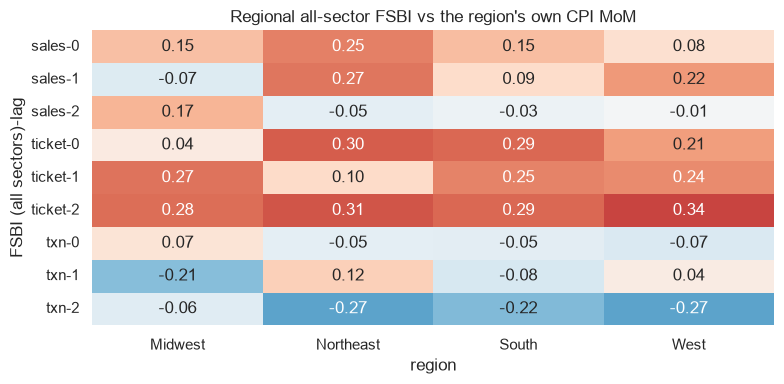

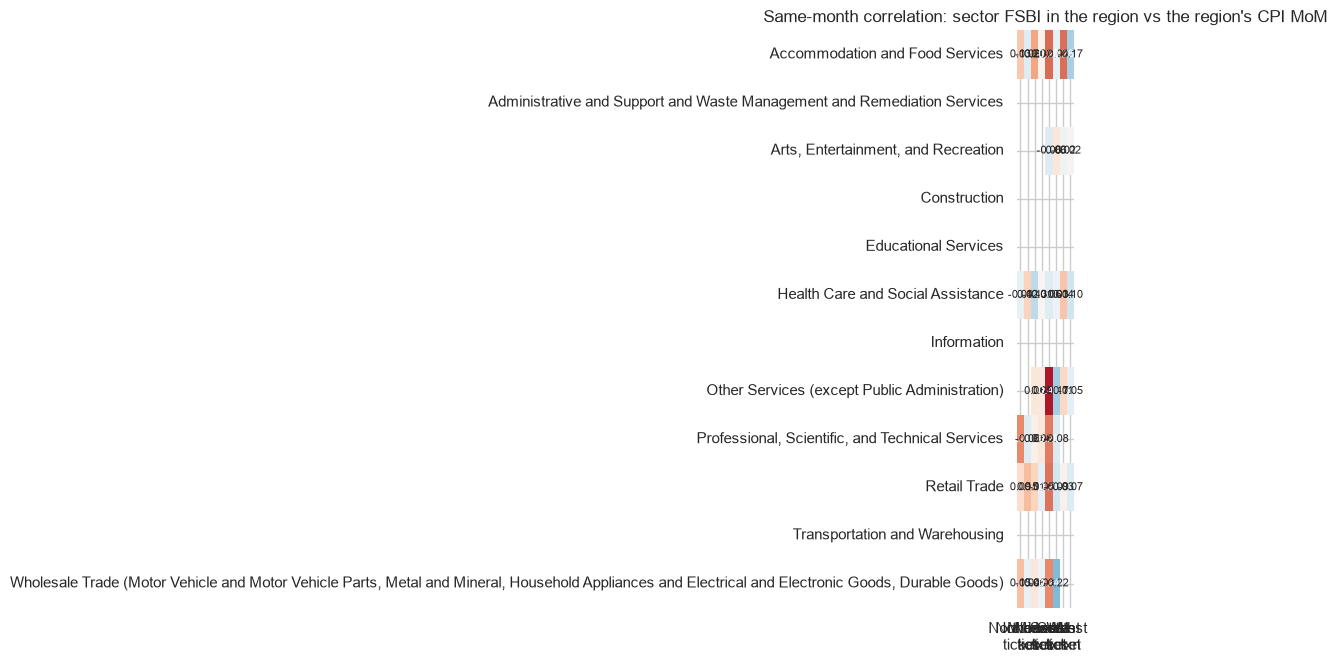

In [ ]:
rows = []
for r in REGIONS:
    for metric in ("sales", "txn", "ticket"):
        for lag in (0, 1, 2):
            rho, n = corr_dev(G_REG[r][metric].shift(lag), REG_CPI[r]); rows.append({"region": r, "FSBI (all sectors)": metric, "lag": lag, "r": rho, "n": n})
RC = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(RC.pivot_table(index=["FSBI (all sectors)", "lag"], columns="region", values="r"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, cbar=False, ax=ax)
ax.set_title("Regional all-sector FSBI vs the region's own CPI MoM"); plt.tight_layout()

M = {}
for r in REGIONS:
    for metric in ("ticket", "txn"):
        M[(r, metric)] = pd.Series({s: corr_dev(G_RS[(r, s)][metric], REG_CPI[r])[0] for s in SECTORS if (r, s) in G_RS})
M = pd.DataFrame(M); M.columns = [f"{r}\n{m}" for r, m in M.columns]
n_med = int(np.median([corr_dev(G_RS[(r, s)]["ticket"], REG_CPI[r])[1] for r in REGIONS for s in SECTORS if (r, s) in G_RS] or [50]))
bonf = r_crit(0.05 / max(M.size, 1), n_med)
fig, ax = plt.subplots(figsize=(11, 0.4 * len(M) + 2))
sns.heatmap(M, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, cbar=False, ax=ax, annot_kws={"size": 8}); ax.set_title("Same-month correlation: sector FSBI in the region vs the region's CPI MoM")
plt.tight_layout()
print(f"{M.size} region x sector correlations: {int((M.abs() > r_crit(0.05, n_med)).sum().sum())} exceed the unadjusted 5% bar (about {0.05 * M.size:.0f} expected by chance), "
      f"{int((M.abs() > bonf).sum().sum())} exceed the Bonferroni bar of |r| > {bonf:.2f}.")

In [ ]:
PAIR_RULES = [(("food service", "restaurant", "drinking"), "food_away"), (("grocery", "food & bev", "food and bev"), "food_at_home"), (("health", "medical"), "medical_care"),
              (("home", "building", "construction", "real estate"), "shelter"), (("entertainment", "arts", "recreation"), "recreation"), (("transport", "warehous"), "transportation"),
              (("education",), "education_communication"), (("retail",), "all_items_less_food_shelter_energy"), (("personal", "other services"), "other_goods_services"), (("auto", "vehicle"), "used_cars")]
pair_rows = []
for r in REGIONS:
    for s in SECTORS:
        comp = next((c for words, c in PAIR_RULES if match(s, words)), None)
        if comp and (r, s) in G_RS and (r, comp) in REG_COMP:
            for metric in ("ticket", "txn"):
                for lag in (0, 1):
                    rho, n = corr_dev(G_RS[(r, s)][metric].shift(lag), REG_COMP[(r, comp)])
                    pair_rows.append({"region": r, "sector": s, "paired CPI component": comp, "FSBI metric": metric, "lag": lag, "r": rho, "n": n})
PAIRS = pd.DataFrame(pair_rows)
if PAIRS.empty:
    print("No sector matched a regional CPI component that FRED serves; the pairing table is skipped (see the availability list in section 1.6).")
else:
    n_p = int(PAIRS.n.median()); m_p = len(PAIRS)
    PAIRS["p"] = 2 * stats.t.sf(np.abs(PAIRS.r * np.sqrt((PAIRS.n - 2) / (1 - PAIRS.r ** 2))), PAIRS.n - 2); PAIRS["adjusted p"] = (PAIRS.p * m_p).clip(upper=1)
    best_pair = PAIRS[PAIRS.lag == 0].pivot_table(index=["sector", "paired CPI component"], columns=["FSBI metric", "region"], values="r")
    print(f"Matched sector-component pairs: {m_p} correlations; the matched ticket correlation should be positive if FSBI's ticket tracks that component's price. Same-month (lag 0):")
    display(best_pair.round(2))
    print(f"Share of matched ticket pairs with a positive same-month correlation: {(PAIRS[(PAIRS.lag == 0) & (PAIRS['FSBI metric'] == 'ticket')].r > 0).mean():.0%} (50% if unrelated); "
          f"{int((PAIRS['adjusted p'] < 0.10).sum())} of {m_p} survive a Bonferroni adjustment at 10%.")

Matched sector-component pairs: 140 correlations; the matched ticket correlation should be positive if FSBI's ticket tracks that component's price. Same-month (lag 0):


FSBI metric                                                                                      ticket                           txn                      
region                                                                                          Midwest Northeast South  West Midwest Northeast South  West
sector                                                       paired CPI component                                                                          
Accommodation and Food Services                              food_away                             0.31      0.13  0.28  0.02   -0.08     -0.28 -0.33 -0.12
Arts, Entertainment, and Recreation                          recreation                             NaN       NaN -0.11  0.17     NaN       NaN -0.23 -0.03
Health Care and Social Assistance                            medical_care                          0.04      0.09  0.12  0.33   -0.07     -0.05 -0.19  0.04
Other Services (except Public Administration)                other_goods_services                  0.10       NaN  0.26  0.07   -0.09       NaN -0.19  0.00
Retail Trade                                                 all_items_less_food_shelter_energy    0.06      0.12  0.24 -0.04   -0.05      0.10 -0.12 -0.10
Wholesale Trade (Motor Vehicle and Motor Vehicle Parts, M... used_cars                             0.17      0.06 -0.07   NaN   -0.14     -0.05  0.01   NaN

Share of matched ticket pairs with a positive same-month correlation: 49% (50% if unrelated); 0 of 140 survive a Bonferroni adjustment at 10%.


### 4.2 Forecasting regional CPI

**Target and baseline.** Each region's CPI MoM, in the same two formulations as the national work, but the baseline is the best public forecast available for *every* region: the **national Cleveland CPI nowcast**. The model predicts the region's deviation from it (track B), so the question is whether regional FSBI explains how a region differs from the nation.

**Three input sets, compared on identical rows.** *National inputs only* (own regional lags, national FSBI, macro, Kalshi): what you could do without regional data. *+ region (all sectors)*: the region's own FSBI. *+ region × sector*: the 26 sector sales/ticket series of that region, from which a screen **inside each training window** keeps the five most correlated (so the choice never uses the month being predicted). Models: AR on the regional deviation, ridge, ridge with the screen, lasso (≤5 inputs), random forest.

A set earns its place only if it beats the one before it on the same months, which the second table tests directly.

Input coverage per region (share of the region's CPI months in which each input exists), and what was dropped:


region,Midwest,Northeast,South,West
block,,,,
kal,0.47,0.47,0.47,0.47
mac,1.00,1.00,1.00,1.00
nat,0.98,0.98,0.98,0.98
own,0.97,0.97,0.97,0.97
reg,0.98,0.98,0.98,0.98
rs,0.00,0.00,0.00,0.00


Northeast: dropped 10 input(s) with too many missing months: rs_arts_entertainment_and_r_ticket, rs_arts_entertainment_and_r_txn, rs_construction_ticket, rs_construction_txn, rs_other_services_except_pu_ticket, rs_other_services_except_pu_txn, rs_transportation_and_wareh_ticket, rs_transportation_and_wareh_txn ...
Midwest: dropped 12 input(s) with too many missing months: rs_arts_entertainment_and_r_ticket, rs_arts_entertainment_and_r_txn, rs_construction_ticket, rs_construction_txn, rs_educational_services_ticket, rs_educational_services_txn, rs_information_ticket, rs_information_txn ...
South: dropped 16 input(s) with too many missing months: rs_administrative_and_suppo_ticket, rs_administrative_and_suppo_txn, rs_arts_entertainment_and_r_ticket, rs_arts_entertainment_and_r_txn, rs_construction_ticket, rs_construction_txn, rs_educational_services_ticket, rs_educational_services_txn ...
West: dropped 16 input(s) with too many missing months: rs_administrative_and_suppo_ticket, rs_admin

inputs,national inputs only,+ region (all sectors),+ region x sector
model,,,
AR (own deviation),1.032,1.032,1.032
Lasso (<=5),1.059,1.059,1.058
Random forest,1.074,1.083,1.079
Ridge,1.109,1.103,1.092
Ridge + top-5 screen,1.050,1.046,1.054


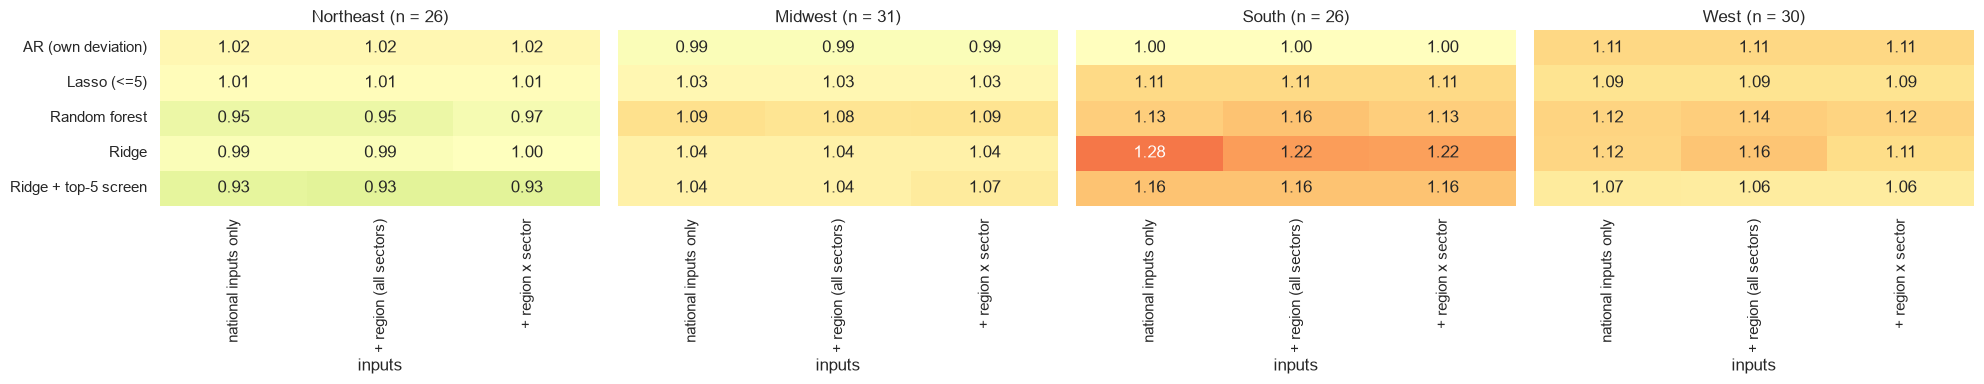

In [ ]:
def sector_slug(s):
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")[:24]
def region_features(r):
    dev_y = REG_CPI[r] - NC["cpi"]
    return {"own": pd.DataFrame({"ry_l1": REG_CPI[r].shift(1), "ry_l2": REG_CPI[r].shift(2), "rdev_l1": dev_y.shift(1)}),
            "reg": G_REG[r][["sales", "txn", "ticket", "breadth"]].add_prefix("r_"),
            "rs": pd.DataFrame({f"rs_{sector_slug(s)}_{m}": G_RS[(r, s)][m] for s in SECTORS if (r, s) in G_RS for m in ("ticket", "txn")}),
            "nat": F["nat"], "mac": F["mac"], "kal": kal_block("cpi")}
REG_SETS = {"national inputs only": ["own", "nat", "mac", "kal"], "+ region (all sectors)": ["own", "nat", "mac", "kal", "reg"], "+ region x sector": ["own", "nat", "mac", "kal", "reg", "rs"]}
MIN_COVER = 0.85          # an input present in fewer than this share of months is dropped rather than allowed to remove the other months
def region_table(r, blocks, rows=None, return_dropped=False):
    parts = region_features(r); X = pd.concat([parts[b] for b in blocks], axis=1)
    tbl = pd.DataFrame({"y": REG_CPI[r] - NC["cpi"], "base": NC["cpi"], "actual": REG_CPI[r], "nowcast": NC["cpi"]}).join(X)
    tbl = tbl.loc[~in_covid(tbl.index) & (tbl.index < END)]
    usable_rows = tbl[list(CORE_COLS)].notna().all(axis=1)
    cover = tbl.loc[usable_rows].drop(columns=list(CORE_COLS)).notna().mean()
    dropped = [c for c in cover.index[cover < MIN_COVER] if c not in OPTIONAL]
    tbl = tbl.drop(columns=dropped)
    tbl = tbl.dropna(subset=[c for c in tbl.columns if c not in OPTIONAL])
    tbl = tbl if rows is None else tbl.loc[tbl.index.intersection(rows)]
    return (tbl, dropped) if return_dropped else tbl
rep_rows = []
for r in REGIONS:
    parts = region_features(r); full_tbl, dropped = region_table(r, REG_SETS["+ region x sector"], return_dropped=True)
    for b, df in parts.items():
        cov = df.reindex(REG_CPI[r].dropna().index).loc[lambda d: ~in_covid(d.index) & (d.index < END)].notna().mean()
        rep_rows.append({"region": r, "block": b, "columns": df.shape[1], "worst column coverage": float(cov.min()), "dropped (coverage < %d%%)" % (100 * MIN_COVER): int(sum(c in dropped for c in df.columns))})
    rep_rows[-1]["rows left"] = len(full_tbl)
COVERAGE = pd.DataFrame(rep_rows)
print("Input coverage per region (share of the region's CPI months in which each input exists), and what was dropped:")
display(COVERAGE.pivot_table(index="block", columns="region", values="worst column coverage").round(2))
for r in REGIONS:
    d = region_table(r, REG_SETS["+ region x sector"], return_dropped=True)[1]
    if d: print(f"{r}: dropped {len(d)} input(s) with too many missing months: {', '.join(d[:8])}{' ...' if len(d) > 8 else ''}")
RROWS = {r: region_table(r, REG_SETS["+ region x sector"]).index for r in REGIONS}
short = {r: len(ix) for r, ix in RROWS.items() if len(ix) <= MIN_TRAIN + 3}
if short:
    worst = COVERAGE[COVERAGE.region.isin(short)].sort_values("worst column coverage").head(3)
    raise ValueError(f"Too few complete months for a regional walk-forward ({short}; need more than {MIN_TRAIN + 3}). Weakest inputs:\n{worst.to_string(index=False)}\n"
                     "Check Data_Nominal.csv for suppressed state x sector cells, the regional CPI source line in section 1.6, and the state coverage in section 1.1.")
def region_models(cols):
    screen = pipe_model(cols, lambda: make_pipeline(SelectKBest(f_regression, k=min(5, len(cols))), RidgeCV(alphas=np.logspace(-1, 4, 30))))
    return {"National nowcast": reference_forecast("nowcast"), "AR (own deviation)": ols_model([c for c in cols if c in ("ry_l1", "rdev_l1")]), "Ridge": ridge_model(cols),
            "Ridge + top-5 screen": screen, "Lasso (<=5)": lasso_model(cols), "Random forest": rf_model(cols)}

REG_OOS, reg_res = {}, []
t0 = time.time()
for r in REGIONS:
    for sname, blocks in REG_SETS.items():
        tbl = region_table(r, blocks, rows=RROWS[r]); cols = feature_cols(tbl)
        f = walk_forward(tbl, region_models(cols)); REG_OOS[(r, sname)] = f
        sc = score_frame(f, [m for m in f if m not in ("actual", "nowcast", "National nowcast")], reference="National nowcast")
        for m, row in sc.iterrows():
            reg_res.append({"region": r, "inputs": sname, "model": m, "n": len(f), **row})
    print(f"  {r} done ({time.time() - t0:.0f}s)", end="")
print()
REG_RES = pd.DataFrame(reg_res)
print("RMSE / national-nowcast RMSE for each region's CPI (below 1 beats the national nowcast), averaged over the four regions:")
display(REG_RES.pivot_table(index="model", columns="inputs", values="RMSE / nowcast", aggfunc="mean").reindex(columns=list(REG_SETS)).round(3))
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, r in zip(axes, REGIONS):
    sub = REG_RES[REG_RES.region == r].pivot_table(index="model", columns="inputs", values="RMSE / nowcast").reindex(columns=list(REG_SETS))
    sns.heatmap(sub, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1.0, vmin=0.6, vmax=1.5, cbar=False, ax=ax); ax.set_title(f"{r} (n = {len(REG_OOS[(r, list(REG_SETS)[0])])})"); ax.set_ylabel("")
plt.tight_layout();

In [ ]:
cmp_rows = []
for r in REGIONS:
    base_f = REG_OOS[(r, "national inputs only")]
    for sname in ("+ region (all sectors)", "+ region x sector"):
        f = REG_OOS[(r, sname)]
        for m in ("Ridge", "Ridge + top-5 screen", "Lasso (<=5)", "Random forest"):
            e, e0 = f.actual - f[m], base_f.actual - base_f[m]
            cmp_rows.append({"region": r, "inputs added": sname, "model": m, "d RMSE % vs national inputs only": 100 * (rmse(e) / rmse(e0) - 1), "DM p": hac_p(e ** 2 - e0 ** 2)})
CMPR = pd.DataFrame(cmp_rows)
print("Does adding regional FSBI beat national inputs alone, same model, same months? (negative = adding the regional FSBI helped)")
display(CMPR.pivot_table(index=["inputs added", "model"], columns="region", values="d RMSE % vs national inputs only").round(1))
g = CMPR.groupby("inputs added")
display(pd.DataFrame({"mean d RMSE %": g["d RMSE % vs national inputs only"].mean(), "cells where regional FSBI helped": g.apply(lambda d: f"{int((d['d RMSE % vs national inputs only'] < 0).sum())} of {len(d)}"),
                      "of those, DM p < 0.10": g.apply(lambda d: int(((d['d RMSE % vs national inputs only'] < 0) & (d['DM p'] < 0.10)).sum()))}).round(2))

Does adding regional FSBI beat national inputs alone, same model, same months? (negative = adding the regional FSBI helped)


region                                       Midwest  Northeast  South  West
inputs added           model                                                
+ region (all sectors) Lasso (<=5)               0.0        0.0    0.0   0.0
                       Random forest            -0.9        0.5    2.2   1.3
                       Ridge                    -0.1        0.1   -4.6   3.2
                       Ridge + top-5 screen      0.0       -0.7    0.0  -0.8
+ region x sector      Lasso (<=5)              -0.0        0.0   -0.1   0.0
                       Random forest            -0.8        2.6    0.3   0.2
                       Ridge                    -0.1        1.1   -4.9  -1.3
                       Ridge + top-5 screen      2.1       -0.7    0.2  -0.3

,mean d RMSE %,cells where regional FSBI helped,"of those, DM p < 0.10"
inputs added,,,
+ region (all sectors),0.01,5 of 16,1
+ region x sector,-0.11,8 of 16,0


### 4.3 From regional forecasts to a national forecast

The alternative route: forecast each region **independently**, combine the four regional forecasts with population shares into a **composite**, and let a second model map regional forecasts to the national first print. The second stage is trained only on earlier months of *out-of-sample* first-stage forecasts (never in-sample fits, which would make the regional forecasts look better than they are), so it needs `S2_MIN` earlier forecasts before it can be fitted; until then only the composite exists.

The first stage is fixed in advance as ridge on **national inputs + region (all sectors)**, not chosen from the table above, to avoid picking the winner of 15 variants on the same months. Second stages: OLS on the composite (a recalibration) and ridge on the four regional forecasts. All are compared on identical months with the national models of section 3 and the nowcast. Regional CPI weights are expenditure-based, not population-based, so the second stage can correct what the plain composite cannot.

In [ ]:
S2_MIN = 12
def stage_two(R, y_nat, w, min_hist=S2_MIN):
    idx = R.index.intersection(y_nat.dropna().index); R, y, w = R.loc[idx], y_nat.loc[idx], w.reindex(idx)
    comp = (R * w[R.columns]).sum(axis=1); out = pd.DataFrame({"composite": comp, "OLS on composite": np.nan, "Ridge on regions": np.nan}, index=idx)
    for i in range(min_hist, len(idx)):
        tr, te = idx[:i], idx[[i]]
        out.loc[te, "OLS on composite"] = LinearRegression().fit(comp.loc[tr].to_frame(), y.loc[tr]).predict(comp.loc[te].to_frame())
        out.loc[te, "Ridge on regions"] = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(R.loc[tr], y.loc[tr]).predict(R.loc[te])
    return out
R_hat = pd.DataFrame({r: REG_OOS[(r, "+ region (all sectors)")]["Ridge"] for r in REGIONS}).dropna()
TWO = stage_two(R_hat, Y["cpi"], REGION_SHARE)
fN = OOS_F[("cpi", "B")]
cmp = pd.concat({"actual": fN.actual, "Cleveland nowcast": fN.nowcast, "direct national: Ridge": fN["Ridge"], "direct national: OLS sparse": fN["OLS sparse"], "direct national: online-selected": SEL["cpi"],
                 "Kalshi implied": fN.get("Kalshi implied", pd.Series(np.nan, index=fN.index)), **{f"regions -> national: {c}": TWO[c] for c in TWO}}, axis=1)
idx2 = cmp.dropna(subset=["regions -> national: OLS on composite", "regions -> national: Ridge on regions", "direct national: online-selected"]).index
print(f"Identical months where every method exists: {len(idx2)} ({idx2.min():%Y-%m} to {idx2.max():%Y-%m}); first-stage forecasts exist for {len(R_hat)} months.")
tab = {}
for c in cmp.columns.drop("actual"):
    e = (cmp.actual - cmp[c]).loc[idx2]; e0 = (cmp.actual - cmp["Cleveland nowcast"]).loc[idx2]
    tab[c] = {"RMSE": rmse(e), "RMSE / nowcast": rmse(e) / rmse(e0), "DM p vs nowcast": np.nan if c == "Cleveland nowcast" else hac_p(e ** 2 - e0 ** 2)}
display(pd.DataFrame(tab).T.sort_values("RMSE").round(3))
e_c = (cmp.actual - cmp["regions -> national: composite"]).dropna(); e_n = (cmp.actual - cmp["Cleveland nowcast"]).reindex(e_c.index)
print(f"The plain composite needs no second stage, so it can be scored on all {len(e_c)} first-stage months: RMSE {rmse(e_c):.3f} vs nowcast {rmse(e_n):.3f} (ratio {rmse(e_c) / rmse(e_n):.2f}, DM p = {hac_p(e_c ** 2 - e_n ** 2):.2f}).")

Identical months where every method exists: 8 (2024-02 to 2025-02); first-stage forecasts exist for 20 months.


,RMSE,RMSE / nowcast,DM p vs nowcast
direct national: online-selected,0.079,0.839,0.345
regions -> national: composite,0.094,0.997,0.913
Cleveland nowcast,0.094,1.000,NaN
Kalshi implied,0.097,1.030,0.798
direct national: Ridge,0.104,1.105,0.012
direct national: OLS sparse,0.134,1.425,0.000
regions -> national: OLS on composite,0.162,1.722,0.000
regions -> national: Ridge on regions,0.164,1.742,0.000


The plain composite needs no second stage, so it can be scored on all 19 first-stage months: RMSE 0.164 vs nowcast 0.169 (ratio 0.97, DM p = 0.57).


## 5. Trading

Every strategy here reads the same ingredients, so results are comparable and no strategy gets special treatment:

- **Signals come from the online-selected forecasts of section 3.7**: each month the model with the lowest *earlier* error, so no hindsight about which model is "best".
- **One event calendar.** *Signal day* (FSBI day), *release day* (the CPI release, 8:30 ET), the trading day before and after it, and the last trading day of the month. A position can enter on or after the signal day and never before; "overnight" trades use the **open** price.
- **Costs.** ETF trades pay 5 bp a side on gross exposure. Kalshi trades fill at the day's last bid/ask with a taker fee of 0.07·p·(1−p) per contract and one contract at a time.
- **Registry.** Each strategy's monthly net return is stored in `STRAT` so section 6 can bootstrap, permute and stress them all the same way.

All of it is pre-holdout and within the months where the selected forecast exists. Sample sizes are small, so every table carries a p-value, and section 6 repeats the inference with Monte Carlo.

### 5.0 Prices and the event calendar

In [ ]:
CORE_TICKERS = ["SPY", "XLP", "XLY", "STIP", "SHY"]                          # required
OPT_TICKERS = ["QQQ", "IWM", "IWB", "RSP", "TLT"]                            # strategies that need them are skipped if missing
def ohlc(ticker, start="2018-01-01"):
    f = CACHE / "yf" / f"{ticker}_ohlc.csv"
    if f.exists():
        return pd.read_csv(f, index_col=0, parse_dates=True)
    d = yf.download(ticker, start=start, auto_adjust=True, progress=False, threads=False)
    if isinstance(d.columns, pd.MultiIndex):
        d.columns = d.columns.get_level_values(0)
    d = d[["Open", "Close"]].dropna(); d.to_csv(f)
    return d
PX = {}
for t in CORE_TICKERS + OPT_TICKERS:
    try:
        PX[t] = ohlc(t)
    except Exception as exc:
        if t in CORE_TICKERS:
            raise
        print(f"{t}: download failed ({str(exc)[:50]}); strategies that need it are skipped.")
CLOSE, OPEN = pd.DataFrame({t: d.Close for t, d in PX.items()}), pd.DataFrame({t: d.Open for t, d in PX.items()})
TD = CLOSE[CORE_TICKERS].dropna().index
CLOSE, OPEN = CLOSE.reindex(TD), OPEN.reindex(TD)
tdpos = pd.Series(np.arange(len(TD)), index=TD)
def on_or_after(d):
    i = TD.searchsorted(pd.Timestamp(d)); return TD[i] if i < len(TD) else pd.NaT

def make_events(index):
    rel = REL["cpi"].reindex(index)
    ev = pd.DataFrame({"signal": [on_or_after(t + pd.DateOffset(months=1, days=FSBI_DAY - 1)) for t in index],
                       "release": [on_or_after(r) if pd.notna(r) else pd.NaT for r in rel]}, index=index).dropna()
    ev = ev[ev.release > ev.signal]
    ev["pre"] = [TD[tdpos[r] - 1] for r in ev.release]
    ev["post"] = [TD[min(tdpos[r] + 1, len(TD) - 1)] for r in ev.release]
    ev["month_end"] = [TD[(TD.year == r.year) & (TD.month == r.month)][-1] for r in ev.release]
    return ev
MONTHS = IDX[(IDX >= pd.Timestamp("2019-02-01")) & (IDX < (HOLDOUT_START if not RUN_HOLDOUT else IDX.max() + pd.Timedelta(days=1))) & ~in_covid(IDX)]
EV_ALL = make_events(MONTHS)
EXP = SEL["cpi"].reindex(IDX)                                                  # online-selected CPI MoM forecast
EV = EV_ALL.loc[EV_ALL.index.intersection(EXP.dropna().index)]                 # months with a forecast
print(f"prices {TD.min():%Y-%m-%d} to {TD.max():%Y-%m-%d} | {len(EV_ALL)} event months in all, {len(EV)} with a model forecast ({EV.index.min():%Y-%m} to {EV.index.max():%Y-%m}) | "
      f"trading days between signal and release: {dict(pd.Series([tdpos[r] - tdpos[s] for s, r in zip(EV.signal, EV.release)]).value_counts().sort_index())}")

# shared helpers and the strategy registry
COST = 0.0005
STRAT = {}
def perf(r):
    r = pd.Series(r).dropna()
    if len(r) < 2:
        return {"months": len(r)}
    return {"months": len(r), "mean (bp/month)": 1e4 * r.mean(), "Sharpe (ann.)": r.mean() / r.std() * np.sqrt(12) if r.std() > 0 else np.nan,
            "months up": float((r > 0).mean()), "cum (%)": 100 * ((1 + r).prod() - 1)}
def block_bootstrap_p(r, block=3, n_boot=None, seed=SEED):
    """One-sided p-value that the mean is not above zero (stationary block bootstrap of the observed returns)."""
    r = pd.Series(r).dropna().values; n = len(r); n_boot = n_boot or (300 if FAST else 2000)
    if n < 2 * block:
        return np.nan
    g = np.random.default_rng(seed); starts = np.arange(n - block + 1)
    m = [np.concatenate([r[s:s + block] for s in g.choice(starts, size=n // block + 1)])[:n].mean() for _ in range(n_boot)]
    return float((np.array(m) <= 0).mean())
def register(name, r):
    STRAT[name] = pd.Series(r).dropna()
    return {**perf(STRAT[name]), "p (mean>0)": block_bootstrap_p(STRAT[name])}

prices 2018-01-02 to 2026-10-30 | 57 event months in all, 22 with a model forecast (2023-05 to 2025-02) | trading days between signal and release: {2: np.int64(1), 3: np.int64(6), 4: np.int64(7), 5: np.int64(4), 6: np.int64(3), 7: np.int64(1)}


### 5.1 Strategies carried over from the earlier drafts

- **TIPS (STIP)**: long when the forecast monthly CPI exceeds the monthly breakeven (10-year, ÷12) by more than 0.1pp. *Long-only* is flat otherwise; *breakeven* shorts SHY against it (duration-weighted) when the forecast is below by 0.1pp.
- **XLP / XLY rotation**: defensive staples when inflation looks high or hotter than a reference, cyclicals otherwise. *A*: |forecast| > 0.2pp; *B (nowcast)*: forecast above the Cleveland nowcast; *B (Kalshi)*: forecast above Kalshi.
- **Kalshi bull spread**: long "CPI > L", short "CPI > U" around the forecast ± its own earlier RMSE, entered on FSBI day at the bid/ask, held to settlement.
- **Kalshi contract**: the single YES/NO contract with the largest edge after shifting the market's own ladder by (forecast − the market's implied median) that day.

Each ETF strategy is shown held to **month-end** and held **through the release only** (exit at the release-day close). Held to settlement is the only Kalshi exit: earlier drafts found early exits give back the spread and a fee.

In [ ]:
BE = fred.get_series("T10YIE", observation_start=START); BE.index = pd.to_datetime(BE.index); BE = BE.resample("MS").mean().reindex(IDX)
W_TIPS = 2.6 / 1.8
f_hat, nc, kal_m = EXP.reindex(EV.index), NC["cpi"].reindex(EV.index), KAL_MAIN["cpi"].reindex(EV.index)
d = f_hat - BE.reindex(EV.index) / 12
sig = {"TIPS long-only": pd.Series(np.where(d > 0.1, 1.0, 0.0), index=EV.index).where(d.notna()),
       "TIPS breakeven": pd.Series(np.select([d > 0.1, d < -0.1], [1.0, -1.0], 0.0), index=EV.index).where(d.notna()),
       "XLP/XLY (A): |forecast| > 0.2": pd.Series(np.where(f_hat.abs() > 0.2, 1.0, -1.0), index=EV.index).where(f_hat.notna()),
       "XLP/XLY (B): forecast > nowcast": pd.Series(np.where(f_hat > nc, 1.0, -1.0), index=EV.index).where(f_hat.notna() & nc.notna()),
       "XLP/XLY (B): forecast > Kalshi": pd.Series(np.where(f_hat > kal_m, 1.0, -1.0), index=EV.index).where(f_hat.notna() & kal_m.notna())}
def leg(tk, row, a, b): return CLOSE.at[row[b], tk] / CLOSE.at[row[a], tk] - 1
LEGS = {"TIPS long-only": lambda r, s, a, b: (s * leg("STIP", r, a, b), abs(s)),
        "TIPS breakeven": lambda r, s, a, b: (s * (leg("STIP", r, a, b) - W_TIPS * leg("SHY", r, a, b)), abs(s) * (1 + W_TIPS))}
for nme in sig:
    if nme.startswith("XLP/XLY"):
        LEGS[nme] = lambda r, s, a, b: (leg("XLP", r, a, b) if s > 0 else leg("XLY", r, a, b), 1.0)
def run_event(name, a, b):
    out = {}
    for t, s in sig[name].dropna().items():
        row = EV.loc[t]
        out[t] = 0.0 if s == 0 else (lambda g, e: g - 2 * COST * e)(*LEGS[name](row, s, a, b))
    return pd.Series(out)
rows = {}
for name in sig:
    for tag, b in (("to month-end", "month_end"), ("through release", "release")):
        rows[f"{name}, {tag}"] = register(f"{name}, {tag}", run_event(name, "signal", b))
BASE = pd.DataFrame(rows).T
display(BASE.round(3))

,months,mean (bp/month),Sharpe (ann.),months up,cum (%),p (mean>0)
"TIPS long-only, to month-end",22.0,21.444,2.024,0.409,4.811,0.000
"TIPS long-only, through release",22.0,2.671,0.441,0.318,0.585,0.221
"TIPS breakeven, to month-end",22.0,-14.162,-2.198,0.182,-3.075,1.000
"TIPS breakeven, through release",22.0,-14.276,-2.746,0.136,-3.097,1.000
"XLP/XLY (A): |forecast| > 0.2, to month-end",22.0,146.468,1.685,0.727,36.423,0.002
"XLP/XLY (A): |forecast| > 0.2, through release",22.0,33.031,0.746,0.636,7.260,0.066
"XLP/XLY (B): forecast > nowcast, to month-end",22.0,86.134,0.878,0.636,19.329,0.153
"XLP/XLY (B): forecast > nowcast, through release",22.0,47.434,0.990,0.682,10.653,0.036
"XLP/XLY (B): forecast > Kalshi, to month-end",22.0,95.888,1.050,0.682,22.089,0.106
"XLP/XLY (B): forecast > Kalshi, through release",22.0,43.151,1.017,0.727,9.688,0.014


In [ ]:
KALSHI_FEE, EDGE_MIN, PRICE_BAND = 0.07, 0.02, (0.15, 0.85)
def kfee(p): return KALSHI_FEE * p * (1 - p)
def entry_day(kind, ref):
    days = sorted(PATHS_BY_DAYS.get((kind, ref), []))
    fsbi_date = ref + pd.DateOffset(months=1, days=FSBI_DAY - 1)
    return next((d for d in days if d >= fsbi_date), None)
PATHS_BY_DAYS = {}
for (kind, ref, day) in PATHS_BY:
    PATHS_BY_DAYS.setdefault((kind, ref), []).append(day)
def band_strikes(center, band):
    x_lo, x_hi = np.ceil(round((center - band) / GRID, 6)) * GRID, np.floor(round((center + band) / GRID, 6)) * GRID
    if x_lo > x_hi:
        x_lo = x_hi = round(center / GRID) * GRID
    return round(x_lo - GRID, 2), round(x_hi, 2)
def spread_settle(kind, ref, center, band):
    d0 = entry_day(kind, ref); g = PATHS_BY.get((kind, ref, d0)) if d0 is not None else None
    if g is None or not np.isfinite(band):
        return np.nan
    L, U = band_strikes(center, band)
    g = g[(g.strike_type == "greater") & g.bid.notna() & g.ask.notna() & g.result.isin(["yes", "no"])].sort_values("floor")
    lo, hi = g[g["floor"] <= L + 1e-9].iloc[-1:], g[g["floor"] >= U - 1e-9].iloc[:1]
    if lo.empty or hi.empty or lo.iloc[0].ask - hi.iloc[0].bid <= 0:
        return np.nan
    lo, hi = lo.iloc[0], hi.iloc[0]
    return float((lo.result == "yes") - (hi.result == "yes")) - (lo.ask - hi.bid) - kfee(lo.ask) - kfee(hi.bid)
def contract_settle(kind, ref, expected):
    d0 = entry_day(kind, ref); g = PATHS_BY.get((kind, ref, d0)) if d0 is not None else None
    if g is None or not np.isfinite(expected):
        return np.nan
    gg = g[g.strike_type == "greater"]; curve = gg[gg.p.notna()].sort_values("floor")
    t = gg[gg.bid.notna() & gg.ask.notna() & gg.p.notna() & gg.result.isin(["yes", "no"])].sort_values("floor")
    implied = ladder_stats(g)["p50"]
    if len(curve) < MIN_STRIKES or t.empty or not np.isfinite(implied):
        return np.nan
    s = curve.p.values.astype(float); s = 0.5 * (np.minimum.accumulate(s) + np.maximum.accumulate(s[::-1])[::-1])
    p_model = np.interp(t["floor"].values - (expected - implied), curve["floor"].values, s)         # the market's own curve, shifted by the disagreement
    cost = np.r_[t.ask.values, 1 - t.bid.values]; fee = KALSHI_FEE * cost * (1 - cost); band = (t.p.values >= PRICE_BAND[0]) & (t.p.values <= PRICE_BAND[1])
    edge = np.where(np.r_[band, band], np.r_[p_model, 1 - p_model] - cost - fee, -np.inf); i = int(np.argmax(edge))
    if edge[i] < EDGE_MIN:
        return 0.0
    n = len(t); j = i % n; won = (t.result.iloc[j] == "yes") if i < n else (t.result.iloc[j] == "no")
    return float(won) - cost[i] - fee[i]
def expanding_band(actual, forecast, min_hist=6):
    return np.sqrt(((actual - forecast) ** 2).expanding(min_periods=min_hist).mean().shift(1))
band = expanding_band(Y["cpi"], EXP)
sp = pd.Series({t: spread_settle("cpi", t, EXP[t], band[t]) for t in EV.index}); ct = pd.Series({t: contract_settle("cpi", t, EXP[t]) for t in EV.index})
krow = {}
for name, series in (("Kalshi bull spread (hold to settlement)", sp), ("Kalshi contract (hold to settlement)", ct)):
    s = series.dropna(); STRAT[name] = s
    krow[name] = {"trades": int((s != 0).sum()), "months": len(s), "mean $ per trade": s[s != 0].mean() if (s != 0).any() else np.nan, "total $": s.sum(), "hit rate": float((s[s != 0] > 0).mean()) if (s != 0).any() else np.nan,
                  "p (mean>0)": block_bootstrap_p(s)}
display(pd.DataFrame(krow).T.round(3))

,trades,months,mean $ per trade,total $,hit rate,p (mean>0)
Kalshi bull spread (hold to settlement),15.0,15.0,-0.143,-2.152,0.600,0.865
Kalshi contract (hold to settlement),14.0,22.0,-0.072,-1.002,0.357,0.771


### 5.2 Industry-specific Kalshi contracts

**Idea.** Kalshi lists contracts on individual prices (eggs, gasoline, and others). If a sector's FSBI **ticket** growth leads the price BLS publishes for that product (grocery receipts for eggs, fuel-station receipts for gasoline), a contract on that price could be traded before the CPI release. This section does the part that can be done honestly with public data:

1. **Is there a lead?** Correlation of the matched FSBI sector series (ticket and transactions) with the monthly change of the product price, at lags 0–2. Only lag 0 is exploitable: FSBI for month *t* is out before BLS publishes month *t*'s price.
2. **Does it forecast the move out of sample?** Walk-forward logistic regressions for "price up this month" (or, for a product whose price almost always rises, "this month's change is above its trailing median", since "up" would be true every time and say nothing): one with FSBI (ticket, transactions, last month's change) and a benchmark with price history only (what a market watching the price alone would know). Compared by Brier score and AUC.
3. **What would it have earned?** One YES or NO contract per month at a price that **assumes the market only knew the price-history benchmark plus noise**, with a 2¢ half-spread and Kalshi's fee. The noise is simulated many times (Monte Carlo). This is an **upper bound** on the edge: a real market also sees the weather, wholesale prices and news.

**What is not done:** a backtest against *real* historical quotes for these markets. The tickers are not verifiable from here, and the markets are young. Set the `kalshi` tickers in `INDUSTRY` and the probe below will tell you what each market looks like before anyone builds on it.

In [ ]:
INDUSTRY = {
    "eggs": {"fred": "APU0000708111", "words": ("grocery", "food & bev", "food and bev", "supermarket", "food store"), "kalshi": []},
    "ground beef": {"fred": "APU0000703112", "words": ("grocery", "food & bev", "food and bev", "supermarket", "food store"), "kalshi": []},
    "coffee": {"fred": "APU0000717311", "words": ("grocery", "food & bev", "food and bev", "supermarket", "food store"), "kalshi": []},
    "gasoline": {"fred": "GASREGW", "words": ("gas station", "fuel", "energy", "petrol"), "kalshi": []},
    "electricity": {"fred": "APU000072610", "words": ("utilit", "energy"), "kalshi": []},
    "restaurant prices": {"fred": "CUSR0000SEFV", "words": ("food service", "restaurant", "drinking", "dining"), "kalshi": []},
}
MC_DRAWS = 40 if FAST else 300
def monthly_price(sid):
    s = fred.get_series(sid, observation_start=START); s.index = pd.to_datetime(s.index)
    return s.resample("MS").mean()
ind_rows, IND = [], {}
for name, cfg in INDUSTRY.items():
    try:
        dp = monthly_price(cfg["fred"]).pipe(lambda s: s.pct_change(fill_method=None) * 100).reindex(IDX)
    except Exception as exc:
        print(f"{name}: FRED series {cfg['fred']} unavailable ({str(exc)[:50]}); skipped."); continue
    ents = [c for c in G_ENT["ticket"].columns if match(c, cfg["words"])]
    if not ents:
        print(f"{name}: no FSBI sector or subsector matches {cfg['words']}; skipped."); continue
    tk, tx = G_ENT["ticket"][ents].mean(axis=1), G_ENT["txn"][ents].mean(axis=1)
    IND[name] = {"dp": dp, "ticket": tk, "txn": tx, "entities": ents}
    for lag in (0, 1, 2):
        for metric, x in (("ticket", tk), ("txn", tx)):
            rho, n = corr_dev(x.shift(lag), dp)
            ind_rows.append({"product": name, "FSBI series": metric, "lag": lag, "r": rho, "n": n, "FSBI entities": ", ".join(e[:28] for e in ents[:2])})
LEAD = pd.DataFrame(ind_rows)
if LEAD.empty:
    print("No industry had both a FRED price series and a matching FSBI sector; the rest of 5.2 is skipped.")
else:
    LEAD["p"] = 2 * stats.t.sf(np.abs(LEAD.r * np.sqrt((LEAD.n - 2) / (1 - LEAD.r ** 2))), LEAD.n - 2)
    print("FSBI vs the product's monthly price change, same month (lag 0) and earlier months:")
    display(LEAD.pivot_table(index="product", columns=["FSBI series", "lag"], values="r").round(2))
    print(f"{int((LEAD.p < 0.05).sum())} of {len(LEAD)} correlations have p < 0.05 (about {0.05 * len(LEAD):.0f} expected by chance).")

electricity: no FSBI sector or subsector matches ('utilit', 'energy'); skipped.
FSBI vs the product's monthly price change, same month (lag 0) and earlier months:


FSBI series       ticket               txn            
lag                    0     1     2     0     1     2
product                                               
coffee              0.12  0.09  0.10 -0.01  0.09 -0.23
eggs               -0.01  0.08 -0.02  0.15  0.11 -0.07
gasoline            0.80  0.14 -0.22  0.26  0.13 -0.03
ground beef        -0.15  0.15  0.09 -0.03  0.16 -0.16
restaurant prices   0.27  0.22  0.29 -0.15 -0.03  0.10

3 of 30 correlations have p < 0.05 (about 2 expected by chance).


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
def kfee_arr(p): return KALSHI_FEE * p * (1 - p)
def logit_walk(X, y, min_obs=24):
    out = pd.Series(np.nan, index=X.index)
    for i in range(min_obs, len(X)):
        tr = slice(0, i)
        if y.iloc[tr].nunique() < 2:
            continue
        m = make_pipeline(StandardScaler(), CLIP(), LogisticRegression(C=0.5)).fit(X.iloc[tr], y.iloc[tr]); out.iloc[i] = m.predict_proba(X.iloc[[i]])[0, 1]
    return out
def contract_pnl(p_model, p_mkt, up, edge=0.03, half_spread=0.02):
    ask_y, ask_n = np.clip(p_mkt + half_spread, 0.01, 0.99), np.clip(1 - p_mkt + half_spread, 0.01, 0.99)
    ey, en = p_model - ask_y - kfee_arr(ask_y), (1 - p_model) - ask_n - kfee_arr(ask_n)
    buy_y, buy_n = (ey > edge) & (ey >= en), (en > edge) & (en > ey)
    return np.where(buy_y, up - ask_y - kfee_arr(ask_y), np.where(buy_n, (1 - up) - ask_n - kfee_arr(ask_n), 0.0)), buy_y | buy_n
rng_ind = np.random.default_rng(SEED); SIG, sig_rows, pnl_rows = {}, {}, {}
EVENT_DEF = {}
for name, d in IND.items():
    dp = d["dp"]; X_f = pd.DataFrame({"ticket": d["ticket"], "txn": d["txn"], "dp_l1": dp.shift(1)}); X_b = pd.DataFrame({"dp_l1": dp.shift(1), "dp_l2": dp.shift(2)})
    ok_feat = X_f.notna().all(axis=1) & X_b.notna().all(axis=1) & dp.notna() & ~in_covid(IDX) & (IDX < END if END is not None else True)
    share_up = float((dp[ok_feat] > 0).mean()) if ok_feat.any() else np.nan
    if 0.10 <= share_up <= 0.90:                                       # 'price up' has real variation
        thr, EVENT_DEF[name] = pd.Series(0.0, index=dp.index), "price up"
    else:                                                              # the price (almost) always rises or always falls: 'up' says nothing, so ask whether the change beats its own recent norm
        thr, EVENT_DEF[name] = dp.shift(1).expanding(12).median(), f"change above its trailing median (price rose in {100 * share_up:.0f}% of months)"
    ok = ok_feat & thr.notna()
    if ok.sum() < 36:
        print(f"{name}: only {int(ok.sum())} usable months; skipped."); continue
    up = (dp[ok] > thr[ok]).astype(int); pf, pb = logit_walk(X_f[ok], up), logit_walk(X_b[ok], up); both = pf.notna() & pb.notna()
    up, pf, pb = up[both], pf[both], pb[both]
    if len(up) < 12 or up.nunique() < 2 or up.value_counts().min() < 5:
        print(f"{name}: too little variation to score a direction forecast ({len(up)} out-of-sample months, outcome counts {up.value_counts().to_dict()}; at least 5 of each are needed); skipped."); continue
    br_f, br_b = (pf - up) ** 2, (pb - up) ** 2
    sig_rows[name] = {"months": len(up), "event": "up" if EVENT_DEF[name] == "price up" else "above trailing median", "share of months event true": up.mean(), "AUC with FSBI": roc_auc_score(up, pf), "AUC price history only": roc_auc_score(up, pb), "Brier with FSBI": br_f.mean(),
                      "Brier price history": br_b.mean(), "d Brier %": 100 * (br_f.mean() / br_b.mean() - 1), "DM p (Brier)": hac_p(br_f - br_b)}
    SIG[name] = (up, pf, pb)
    for sigma in (0.0, 0.05, 0.10):
        draws = [contract_pnl(pf.values, np.clip(pb.values + rng_ind.normal(0, sigma, len(pb)), 0.03, 0.97), up.values) for _ in range(MC_DRAWS)]
        tot = np.array([p.sum() for p, _ in draws]); ntr = np.array([n.sum() for _, n in draws])
        pnl_rows[(name, f"market noise {sigma:.2f}")] = {"trades / draw": ntr.mean(), "mean $ per trade": (tot / np.maximum(ntr, 1)).mean(), "5th pct total $": np.percentile(tot, 5), "95th pct total $": np.percentile(tot, 95), "share of draws > 0": float((tot > 0).mean())}
if sig_rows:
    print("Out-of-sample direction forecasts (logistic walk-forward). A lower Brier score and a higher AUC with FSBI than with price history alone is the evidence that FSBI leads the price:")
    display(pd.DataFrame(sig_rows).T.round(3))
    print("\nOne contract per month against an assumed market (price-history forecast + noise), 2c half-spread, Kalshi fee. Upper bound: a real market knows more than price history.")
    display(pd.DataFrame(pnl_rows).T.round(3))
    for name in SIG:
        up, pf, pb = SIG[name]; STRAT[f"Industry contract: {name} (assumed market, noise 0.05)"] = pd.Series(contract_pnl(pf.values, np.clip(pb.values + rng_ind.normal(0, 0.05, len(pb)), 0.03, 0.97), up.values)[0], index=up.index)
for name, cfg in INDUSTRY.items():
    for series in cfg["kalshi"]:
        try:
            r = kalshi_get("/markets", {"series_ticker": series, "limit": 5}); ms = (r or {}).get("markets", [])
            print(f"Kalshi probe {series}: {len(ms)} market(s) returned" + (f"; example: {ms[0].get('title', '')[:70]} | strike type {ms[0].get('strike_type')} | status {ms[0].get('status')}" if ms else ""))
        except Exception as exc:
            print(f"Kalshi probe {series}: failed ({str(exc)[:60]})")
if not any(cfg["kalshi"] for cfg in INDUSTRY.values()):
    print("\nNo Kalshi tickers configured in INDUSTRY: add e.g. 'kalshi': ['<series ticker from the Kalshi site>'] to probe a real market.")

Out-of-sample direction forecasts (logistic walk-forward). A lower Brier score and a higher AUC with FSBI than with price history alone is the evidence that FSBI leads the price:


,months,event,share of months event true,AUC with FSBI,AUC price history only,Brier with FSBI,Brier price history,d Brier %,DM p (Brier)
eggs,32,up,0.625,0.470833,0.475,0.265987,0.250499,6.182899,0.148568
ground beef,32,up,0.5625,0.424603,0.369048,0.257452,0.272314,-5.45781,0.588831
coffee,22,up,0.590909,0.264957,0.444444,0.272106,0.253448,7.361632,0.346075
gasoline,32,up,0.4375,0.702381,0.345238,0.213659,0.276852,-22.825517,0.092776
restaurant prices,22,above trailing median,0.318182,0.628571,0.666667,0.289555,0.262023,10.507353,0.000017



One contract per month against an assumed market (price-history forecast + noise), 2c half-spread, Kalshi fee. Upper bound: a real market knows more than price history.


trades / draw  mean $ per trade  5th pct total $  95th pct total $  share of draws > 0
eggs              market noise 0.00         13.000            -0.127           -1.645            -1.645               0.000
                  market noise 0.05         14.170            -0.087           -3.128             0.895               0.130
                  market noise 0.10         19.440             0.009           -2.711             3.001               0.517
ground beef       market noise 0.00         19.000             0.032            0.601             0.601               1.000
                  market noise 0.05         19.593             0.060           -0.558             3.082               0.860
                  market noise 0.10         21.913             0.106           -0.230             5.483               0.923
coffee            market noise 0.00         12.000            -0.049           -0.587            -0.587               0.000
                  market noise 0.05         12.867            -0.056           -2.441             1.011               0.273
                  market noise 0.10         14.173             0.010           -2.125             2.776               0.533
gasoline          market noise 0.00         24.000             0.252            6.039             6.039               1.000
                  market noise 0.05         25.007             0.236            4.279             7.410               1.000
                  market noise 0.10         25.280             0.239            3.941             8.093               1.000
restaurant prices market noise 0.00          5.000            -0.449           -2.243            -2.243               0.000
                  market noise 0.05          7.163            -0.283           -3.762            -0.379               0.030
                  market noise 0.10         12.303            -0.056           -3.374             2.206               0.343


No Kalshi tickers configured in INDUSTRY: add e.g. 'kalshi': ['<series ticker from the Kalshi site>'] to probe a real market.


### 5.3 The release-day gap: volatility jump and direction

CPI is published at 8:30 ET, before the US open, so its whole news shock lands in the **overnight gap**: yesterday's close to today's open. Two questions.

1. **Is there a volatility jump?** The typical absolute gap on release mornings against ordinary overnight gaps (all other days), and the same for the *next* morning (release-day close to the following open). Ratios above 1 with a bootstrap interval above 1 are a jump; the variance ratio is the version a variance swap would pay.
2. **Can it be predicted or traded?** *Size*: does the model's predicted surprise magnitude, |forecast − nowcast|, or the model–Kalshi disagreement forecast the size of the gap (walk-forward R² against the constant)? *Direction*: each asset's gap is regressed on the **market surprise** (first print − Kalshi's implied median the evening before, or the nowcast where Kalshi does not exist), with the slope estimated on earlier months only. The trade enters at the previous close and exits at the release-morning open (a market-on-close and a market-on-open order, 5 bp each side): long if (slope × the model's predicted market surprise) > 0, short otherwise. A short volatility straddle would be the cleanest vol trade, but option prices are not available here, so volatility is tested statistically rather than traded.

In [ ]:
GAP_ASSETS = [t for t in ("SPY", "QQQ", "IWM", "TLT") if t in PX]
over_all = (OPEN / CLOSE.shift(1) - 1)[GAP_ASSETS]
smp = (over_all.index >= EV_ALL.signal.min()) & (over_all.index <= EV_ALL.month_end.max()) & ~in_covid(over_all.index)
special = set(EV_ALL.release) | set(EV_ALL.post)
normal = over_all[smp & ~over_all.index.isin(special)]
GAP = {}
for tk in GAP_ASSETS:
    GAP[tk] = pd.DataFrame({"gap": OPEN[tk].reindex(EV_ALL.release).values / CLOSE[tk].reindex(EV_ALL.pre).values - 1,
                            "intraday": CLOSE[tk].reindex(EV_ALL.release).values / OPEN[tk].reindex(EV_ALL.release).values - 1,
                            "gap_next": OPEN[tk].reindex(EV_ALL.post).values / CLOSE[tk].reindex(EV_ALL.release).values - 1}, index=EV_ALL.index)
def ratio_ci(a, b, n=None, seed=SEED):
    n = n or (300 if FAST else 2000); g = np.random.default_rng(seed); a, b = np.abs(a), np.abs(b)
    r = [g.choice(a, len(a)).mean() / g.choice(b, len(b)).mean() for _ in range(n)]
    return a.mean() / b.mean(), np.percentile(r, 5), np.percentile(r, 95)
vj = {}
for tk in GAP_ASSETS:
    for label, col in (("release morning", "gap"), ("morning after", "gap_next")):
        a = GAP[tk][col].dropna().values; b = normal[tk].dropna().values; m, lo, hi = ratio_ci(a, b)
        vj[(tk, label)] = {"events": len(a), "mean |gap| release (bp)": 1e4 * np.abs(a).mean(), "mean |gap| ordinary (bp)": 1e4 * np.abs(b).mean(), "ratio": m, "90% interval": f"{lo:.2f} to {hi:.2f}",
                           "variance ratio": (a ** 2).mean() / (b ** 2).mean()}
print(f"Overnight gap on release mornings vs {len(normal)} ordinary overnight gaps (all assets use the same sample window):")
display(pd.DataFrame(vj).T.round(2))
GAPS_NEXT = {tk: GAP[tk].gap_next.corr(GAP[tk].gap + GAP[tk].intraday) for tk in GAP_ASSETS}
print("Does the release day's total move continue or reverse the next morning? corr(release-day close-to-close, next-morning gap):", {k: round(v, 2) for k, v in GAPS_NEXT.items()})

Overnight gap on release mornings vs 1099 ordinary overnight gaps (all assets use the same sample window):


events mean |gap| release (bp) mean |gap| ordinary (bp)     ratio  90% interval variance ratio
SPY release morning     57               74.541327                41.421162  1.799595  1.39 to 2.24       3.485184
    morning after       57               54.924552                41.421162  1.326002  0.88 to 1.92       3.687801
QQQ release morning     57               96.008024                54.063945  1.775823  1.38 to 2.20       3.272658
    morning after       57               65.016582                54.063945  1.202587  0.84 to 1.66       2.489634
IWM release morning     57              108.931985                54.084427   2.01411  1.61 to 2.46       4.176189
    morning after       57               71.426518                54.084427  1.320649  0.93 to 1.82       3.084008
TLT release morning     57                65.87108                58.029589  1.135129  0.92 to 1.37       1.510248
    morning after       57               64.005728                58.029589  1.102984  0.84 to 1.41       1.775359

Does the release day's total move continue or reverse the next morning? corr(release-day close-to-close, next-morning gap): {'SPY': np.float64(0.44), 'QQQ': np.float64(0.34), 'IWM': np.float64(0.29), 'TLT': np.float64(-0.41)}


In [ ]:
K_PRE = pd.Series({t: implied_on("cpi", t, EV_ALL.at[t, "pre"])["p50"] if t >= KALSHI_START else np.nan for t in EV_ALL.index})        # Kalshi's median the evening before the release
MKT_EXP = K_PRE.fillna(NC["cpi"].reindex(EV_ALL.index))                                                                                       # what the market expected: Kalshi if it exists, else the nowcast
MS = (Y["cpi"].reindex(EV_ALL.index) - MKT_EXP)                                                                                               # realised market surprise
PS = (EXP.reindex(EV_ALL.index) - MKT_EXP)                                                                                                    # the model's predicted market surprise
print(f"market surprise measured against Kalshi in {int(K_PRE.notna().sum())} of {len(EV_ALL)} months, against the nowcast in the rest")
def exp_beta(gap, s, min_obs=12):
    out = pd.Series(np.nan, index=gap.index)
    for i in range(min_obs, len(gap)):
        pair = pd.concat([gap.iloc[:i], s.iloc[:i]], axis=1).dropna()
        if len(pair) >= min_obs and pair.iloc[:, 1].var() > 0:
            out.iloc[i] = np.polyfit(pair.iloc[:, 1], pair.iloc[:, 0], 1)[0]
    return out
size_rows, dir_ret, dir_rows = {}, {}, {}
for tk in GAP_ASSETS:
    g = GAP[tk].gap; beta_ = exp_beta(g, MS)
    full = pd.concat([g, MS], axis=1).dropna(); slope = np.polyfit(full.iloc[:, 1], full.iloc[:, 0], 1)[0]
    sig_ = np.sign(beta_ * PS); pnl = (sig_ * g - 2 * COST).where(sig_.notna() & (sig_ != 0))
    dir_ret[tk] = pnl
    dir_rows[tk] = {"months traded": int(pnl.notna().sum()), "full-sample gap per +0.1pp surprise (bp)": 1e3 * slope, **{k: v for k, v in perf(pnl).items() if k != "months"}, "p (mean>0)": block_bootstrap_p(pnl)}
    # size: walk-forward R2 of |gap| on |predicted surprise| against the constant
    y_, x_ = g.abs(), PS.abs(); e1, e0 = [], []
    for i in range(12, len(y_)):
        tr = pd.concat([y_.iloc[:i], x_.iloc[:i]], axis=1).dropna()
        if len(tr) < 12 or pd.isna(x_.iloc[i]) or pd.isna(y_.iloc[i]): continue
        b = np.polyfit(tr.iloc[:, 1], tr.iloc[:, 0], 1); e1.append(y_.iloc[i] - np.polyval(b, x_.iloc[i])); e0.append(y_.iloc[i] - tr.iloc[:, 0].mean())
    size_rows[tk] = {"months": len(e1), "corr(|gap|, |predicted surprise|)": y_.corr(x_), "walk-forward R2 vs constant": (1 - np.sum(np.square(e1)) / np.sum(np.square(e0))) if e1 else np.nan}
print("Size: does the predicted size of the surprise forecast the size of the release-morning gap?")
display(pd.DataFrame(size_rows).T.round(3))
print("Direction: overnight long/short on the release-morning gap (enter previous close, exit release open), slope estimated on earlier months only:")
display(pd.DataFrame(dir_rows).T.round(3))
EW = pd.concat(dir_ret, axis=1).mean(axis=1, skipna=True).where(pd.concat(dir_ret, axis=1).notna().any(axis=1))
print("Equal-weight across assets:", register("Release gap: overnight directional (equal-weight)", EW))

market surprise measured against Kalshi in 27 of 57 months, against the nowcast in the rest
Size: does the predicted size of the surprise forecast the size of the release-morning gap?


,months,"corr(|gap|, |predicted surprise|)",walk-forward R2 vs constant
SPY,10.0,-0.089,-0.102
QQQ,10.0,-0.060,-0.160
IWM,10.0,-0.113,-0.033
TLT,10.0,-0.146,0.020


Direction: overnight long/short on the release-morning gap (enter previous close, exit release open), slope estimated on earlier months only:


,months traded,full-sample gap per +0.1pp surprise (bp),mean (bp/month),Sharpe (ann.),months up,cum (%),p (mean>0)
SPY,22.0,-50.797,1.095,0.051,0.455,0.183,0.404
QQQ,22.0,-66.046,0.709,0.026,0.455,0.062,0.420
IWM,22.0,-66.161,1.696,0.036,0.455,0.101,0.456
TLT,22.0,-28.176,-11.694,-0.414,0.455,-2.640,0.787


Equal-weight across assets: {'months': 22, 'mean (bp/month)': np.float64(-2.04859816066447), 'Sharpe (ann.)': np.float64(-0.0703945706130806), 'months up': 0.3181818181818182, 'cum (%)': np.float64(-0.55586449894518), 'p (mean>0)': 0.5065}


### 5.4 Large versus small caps under inflation expectations

**Hypotheses.** When inflation expectations rise, *large* firms should hold up better than *small* ones: economies of scale in purchasing and pricing power pass costs on, access to cheaper credit when rates reprice, and scale advantages in logistics. And the **substitution effect**: consumers trade down to large-scale discounters (Walmart, Costco, Amazon) at the expense of independent merchants, which is exactly what FSBI measures (a *small-business* index): ticket up with transactions down is price-led growth on a shrinking customer count.

**Test.** A monthly signal read on FSBI day, each at several horizons (1 day to 63 trading days after the signal-day close). The position is long the **Russell 1000** (IWB) and short the **Russell 2000** (IWM) when the signal is positive and the reverse when negative; the second pair is cap-weight against equal-weight S&P (SPY − RSP). Signals (z-scored on earlier months only): (1) *expected inflation*: the selected model's CPI forecast, (2) *expected surprise*: forecast minus nowcast, (3) *Kalshi's implied CPI*, (4) *FSBI squeeze*: national ticket growth minus transaction growth. Costs are 5 bp a side on both legs. Horizons beyond a month overlap, so t-statistics use HAC errors with lags tied to the horizon, and a **permutation test** shuffles the signal's signs across months. A positive mean means the hypothesis (large beats small when the signal is high) held.

IWB-IWM: unconditional mean of (long - short) by horizon (bp): 1d +13, 5d +44, 10d +63, 21d +90, 42d +179, 63d +269
SPY-RSP: unconditional mean of (long - short) by horizon (bp): 1d +1, 5d +15, 10d +33, 21d +41, 42d +80, 63d +119
12 signal x horizon x pair cells; 3 with permutation p < 0.05 (about 1 expected by chance); 3 of those in the hypothesised direction.


mean (bp)  t-stat  hit rate  permutation p  months
IWB-IWM FSBI squeeze (ticket - transactions) 63     26.606   0.582     0.622          0.007    45.0
                                             5      17.820   0.627     0.533          0.018    45.0
                                             42     43.159   0.748     0.578          0.019    45.0
                                             10     -2.144  -0.060     0.489          0.101    45.0
SPY-RSP FSBI squeeze (ticket - transactions) 42      3.952   0.078     0.556          0.123    45.0
                                             5     -11.090  -0.809     0.422          0.127    45.0
IWB-IWM FSBI squeeze (ticket - transactions) 21     -2.369  -0.051     0.422          0.148    45.0
SPY-RSP FSBI squeeze (ticket - transactions) 10    -12.221  -0.652     0.400          0.154    45.0

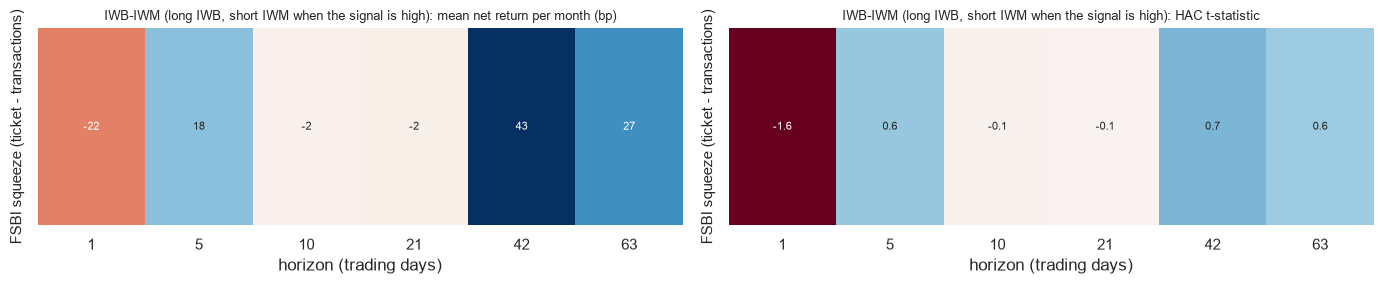

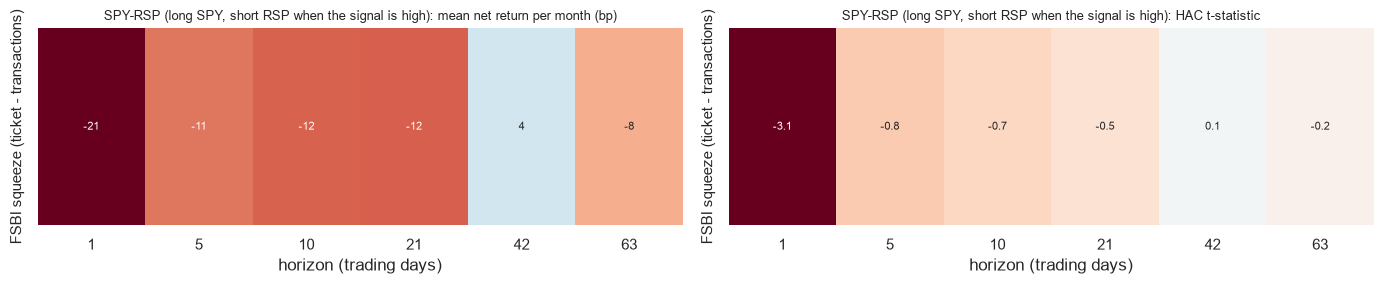

In [ ]:
HORIZONS = [1, 5, 10, 21, 42, 63]
PAIRS_SIZE = [(a, b) for a, b in (("IWB", "IWM"), ("SPY", "RSP")) if a in PX and b in PX]
SIGNALS = {"expected inflation (model forecast)": expanding_z(EXP), "expected surprise (forecast - nowcast)": expanding_z(EXP - NC["cpi"]), "Kalshi implied CPI": expanding_z(KAL_MAIN["cpi"]),
           "FSBI squeeze (ticket - transactions)": expanding_z(F["nat"]["nat_ticket"] - F["nat"]["nat_txn"])}
def pair_return(large, small, s, h):
    i = tdpos.get(s)
    if i is None or i + h >= len(TD): return np.nan
    j = TD[i + h]; return (CLOSE.at[j, large] / CLOSE.at[s, large] - 1) - (CLOSE.at[j, small] / CLOSE.at[s, small] - 1)
rng_sz = np.random.default_rng(SEED); size_tab, size_t, SIZE_RET = {}, {}, {}
n_perm = 200 if FAST else 1000
for large, small in PAIRS_SIZE:
    for h in HORIZONS:
        rr = pd.Series({t: pair_return(large, small, EV_ALL.at[t, "signal"], h) for t in EV_ALL.index})
        size_tab[(f"{large}-{small}", "unconditional", h)] = {"mean (bp)": 1e4 * rr.mean(), "t-stat": rr.mean() / (rr.std() / np.sqrt(rr.notna().sum()))}
        for sname, z in SIGNALS.items():
            zz = z.reindex(rr.index); ok = zz.notna() & rr.notna() & (zz != 0)
            if ok.sum() < 18: continue
            pos = np.sign(zz[ok]); pnl = pos * rr[ok] - 4 * COST
            nw = sm.OLS(pnl.values, np.ones(len(pnl))).fit(cov_type="HAC", cov_kwds={"maxlags": int(np.ceil(h / 21)) + 2})
            perm = [np.mean(rng_sz.permutation(pos.values) * rr[ok].values - 4 * COST) for _ in range(n_perm)]
            size_tab[(f"{large}-{small}", sname, h)] = {"mean (bp)": 1e4 * pnl.mean(), "t-stat": float(nw.tvalues[0]), "hit rate": float((pnl > 0).mean()), "permutation p": (1 + sum(np.array(perm) >= pnl.mean())) / (n_perm + 1), "months": int(ok.sum())}
            SIZE_RET[(f"{large}-{small}", sname, h)] = pnl
ST = pd.DataFrame(size_tab).T
for pair in [f"{a}-{b}" for a, b in PAIRS_SIZE]:
    sub = ST.loc[pair]; sub = sub[sub.index.get_level_values(0) != "unconditional"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 3))
    for ax, col, title, cm in ((axes[0], "mean (bp)", "mean net return per month (bp)", "RdBu"), (axes[1], "t-stat", "HAC t-statistic", "RdBu")):
        sns.heatmap(sub[col].astype(float).unstack(), annot=True, fmt=".1f" if col == "t-stat" else ".0f", cmap=cm, center=0, cbar=False, ax=ax, annot_kws={"size": 8}); ax.set_title(f"{pair} (long {pair.split('-')[0]}, short {pair.split('-')[1]} when the signal is high): {title}", fontsize=9); ax.set_ylabel(""); ax.set_xlabel("horizon (trading days)")
    plt.tight_layout()
    print(f"{pair}: unconditional mean of (long - short) by horizon (bp): " + ", ".join(f"{h}d {ST.loc[(pair, 'unconditional', h), 'mean (bp)']:+.0f}" for h in HORIZONS))
res_sz = ST[ST.index.get_level_values(1) != "unconditional"].dropna(subset=["permutation p"])
print(f"{len(res_sz)} signal x horizon x pair cells; {int((res_sz['permutation p'] < 0.05).sum())} with permutation p < 0.05 (about {0.05 * len(res_sz):.0f} expected by chance); "
      f"{int(((res_sz['permutation p'] < 0.05) & (res_sz['mean (bp)'] > 0)).sum())} of those in the hypothesised direction.")
display(res_sz.sort_values("permutation p").head(8).round(3))
for large, small in PAIRS_SIZE[:1]:
    for sname in SIGNALS:
        if (f"{large}-{small}", sname, 21) in SIZE_RET:
            STRAT[f"Large-small {large}-{small}, {sname}, 21d"] = SIZE_RET[(f"{large}-{small}", sname, 21)]

## 6. Sources of noise, and Monte Carlo

Two things in this section. First, **measuring where the noise is**: what part of the forecast error and of trading P&L no model could remove. Second, **Monte Carlo** used three ways, each judged out of sample or against a null rather than in-sample:

1. *Noise injection*: add measurement error of increasing size to the FSBI inputs and watch the forecast. This shows how much FSBI measurement error the signal tolerates before the model falls back to the nowcast.
2. *Refinement*: reduce estimation variance with **bagging** (average of models fitted to bootstrap resamples of the training months) and with **bootstrap-stabilised shrinkage** toward the nowcast (the weight on the model is estimated on many resamples of earlier errors, so it does not swing with one month). Scored walk-forward against the unrefined forecast.
3. *Trading inference*: block-bootstrap confidence bands for each strategy's Sharpe ratio, a **signal-shuffling null** (does the timing of the signal matter, or would random signals earn the same?), and **cost and slippage stress**.

### 6.1 Where the noise is

In [ ]:
led = {}
NOISE_TARGET = pd.DataFrame(noise).T                                                        # from section 2.4
# FSBI sampling noise: cross-state dispersion is an UPPER bound (real regional differences are not noise)
st_g = np.log(ST_LEVEL[SALES]).diff() * 100
se2 = (st_g.std(axis=1) ** 2 / st_g.notna().sum(axis=1)).loc[lambda s: s.notna() & ~in_covid(s.index)]
nat_s = G_NAT["sales"].loc[se2.index]
led["FSBI national sales growth: sd (pp)"] = float(nat_s.std())
led["  sampling noise sd if state dispersion were all noise (pp, upper bound)"] = float(np.sqrt(se2.mean()))
led["  reliability ratio, lower bound (signal variance / total)"] = float(nat_s.var() / (nat_s.var() + se2.mean()))
# release-day market noise
for tk in GAP_ASSETS:
    pair = pd.concat([GAP[tk].gap, MS], axis=1).dropna()
    r2 = np.corrcoef(pair.iloc[:, 0], pair.iloc[:, 1])[0, 1] ** 2
    led[f"{tk} release-morning gap: share of variance explained by the CPI surprise"] = float(r2)
# Kalshi microstructure
spreads, dvol = [], []
for (kind, ref), days in PATHS_BY_DAYS.items():
    if kind != "cpi": continue
    d0 = entry_day(kind, ref); g = PATHS_BY.get((kind, ref, d0)) if d0 is not None else None
    if g is not None:
        mid = g[(g.p >= 0.15) & (g.p <= 0.85) & g.bid.notna() & g.ask.notna()]; spreads += list(mid.ask - mid.bid)
    seq = [implied_on(kind, ref, d)["p50"] for d in sorted(days)]; dvol += list(np.diff([x for x in seq if np.isfinite(x)]))
led["Kalshi CPI ladder: mean bid-ask spread on contracts priced 15-85% (cents)"] = 100 * float(np.mean(spreads)) if spreads else np.nan
led["Kalshi implied median: sd of day-to-day change before the release (pp)"] = float(np.std(dvol)) if dvol else np.nan
NOISE_LEDGER = pd.Series(led, name="value")
print("Target noise (section 2.4):"); display(NOISE_TARGET.round(3))
print("Other measured noise sources:"); display(NOISE_LEDGER.round(3).to_frame())

Target noise (section 2.4):


,rounding sd (pp),revision RMS: first print vs today (pp),baseline RMSE (pp),share of baseline MSE that is rounding
CPI,0.029,0.073,0.148,0.038
core CPI,0.029,0.052,0.123,0.055
PCE,0.029,0.074,0.130,0.049
core PCE,0.029,0.072,0.123,0.055


Other measured noise sources:


,value
FSBI national sales growth: sd (pp),0.775
"sampling noise sd if state dispersion were all noise (pp, upper bound)",0.213
"reliability ratio, lower bound (signal variance / total)",0.930
SPY release-morning gap: share of variance explained by the CPI surprise,0.410
QQQ release-morning gap: share of variance explained by the CPI surprise,0.433
IWM release-morning gap: share of variance explained by the CPI surprise,0.361
TLT release-morning gap: share of variance explained by the CPI surprise,0.182
Kalshi CPI ladder: mean bid-ask spread on contracts priced 15-85% (cents),3.362
Kalshi implied median: sd of day-to-day change before the release (pp),0.012


### 6.2 Monte Carlo on the forecasts

**(a) How certain is "better than the nowcast"?** The online-selected forecast's RMSE ratio to the nowcast, with a 90% interval from resampling the out-of-sample months in blocks of three, and the share of resamples in which the ratio is below 1. With ~28 months this interval is wide; it is the honest version of the point estimate.

In [ ]:
B_BOOT = 400 if FAST else 2000
def boot_ratio(e_m, e_0, block=3, n=B_BOOT, seed=SEED):
    e_m, e_0 = np.asarray(e_m), np.asarray(e_0); T = len(e_m); g = np.random.default_rng(seed); starts = np.arange(T - block + 1); out = []
    for _ in range(n):
        idx = np.concatenate([np.arange(s, s + block) for s in g.choice(starts, size=T // block + 1)])[:T]
        out.append(np.sqrt((e_m[idx] ** 2).mean() / (e_0[idx] ** 2).mean()))
    out = np.array(out); return out.mean(), np.percentile(out, 5), np.percentile(out, 95), float((out < 1).mean())
rows = {}
for k in TARGETS:
    f = OOS_F[(k, "B")]; ok = SEL[k].dropna().index
    m, lo, hi, p1 = boot_ratio((f.actual - SEL[k]).loc[ok], (f.actual - f.nowcast).loc[ok])
    rows[LABEL[k]] = {"months": len(ok), "RMSE ratio vs nowcast": rmse((f.actual - SEL[k]).loc[ok]) / rmse((f.actual - f.nowcast).loc[ok]), "bootstrap mean": m, "90% interval": f"{lo:.2f} to {hi:.2f}", "share of resamples below 1": p1}
BOOT_TAB = pd.DataFrame(rows).T
display(BOOT_TAB.round(3))

,months,RMSE ratio vs nowcast,bootstrap mean,90% interval,share of resamples below 1
CPI,22,1.048103,1.123412,0.82 to 1.57,0.3305
core CPI,22,1.031005,1.018898,0.89 to 1.23,0.512
PCE,22,1.171173,1.20458,1.00 to 1.40,0.049
core PCE,22,0.928365,0.943956,0.87 to 1.02,0.8845


**(b) Noise injection: how much FSBI measurement error can the signal take?** Gaussian noise with standard deviation equal to 0, 0.5, 1 and 2 times each FSBI input's own standard deviation is added to every FSBI column (training and test alike, redrawn each repetition), and the ridge forecast of the surprise is re-run. A multiple of 1 means the noise is as large as the signal itself (reliability 0.5). If the ratio stays near its noise-free value up to a multiple of 1, the information in FSBI is robust to measurement error; if it climbs to 1.0 (the nowcast) quickly, the gain depends on FSBI being very precise. Ratios are RMSE of ridge divided by RMSE of the nowcast. **Caution:** where the noise-free ratio is already above 1 (ridge is overfitting), added noise acts as extra regularisation and the ratio can *improve*; only read the curve as tolerance to measurement error where the noise-free ratio is below 1.

mean                      std                     
noise multiple    0.0    0.5    1.0    2.0 0.0    0.5    1.0    2.0
target                                                             
CPI             0.914  0.990  0.977  0.970 NaN  0.130  0.045  0.033
PCE             0.950  0.945  0.997  1.003 NaN  0.012  0.056  0.068
core CPI        0.980  0.982  0.986  0.988 NaN  0.005  0.002  0.006
core PCE        0.984  0.984  0.984  1.011 NaN  0.000  0.001  0.041

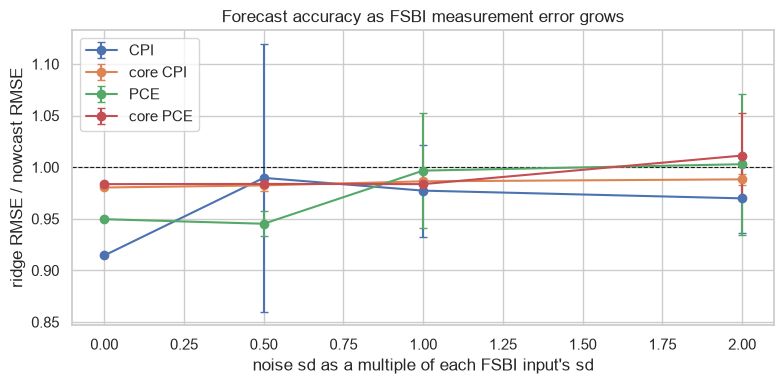

In [ ]:
FSBI_PREFIX = ("nat_", "sec_", "br_", "reg_")
def noisy(tbl, mult, g):
    t = tbl.copy()
    for c in [c for c in feature_cols(tbl) if c.startswith(FSBI_PREFIX)]:
        t[c] = t[c] + mult * t[c].std() * g.normal(size=len(t))
    return t
LEVELS, REPS = [0, 0.5, 1, 2], (2 if FAST else 5)
g_noise = np.random.default_rng(SEED); inj = []
for k in TARGETS:
    base_tbl = model_table(k, ABLATE["full"], LAG_CHOICE[(k, "B")], "B", rows=ROWS[k]); cols = feature_cols(base_tbl)
    for mult in LEVELS:
        for rep in range(1 if mult == 0 else REPS):
            f = walk_forward(noisy(base_tbl, mult, g_noise) if mult else base_tbl, {"Nowcast": reference_forecast("nowcast"), "Ridge": ridge_model(cols)})
            inj.append({"target": LABEL[k], "noise multiple": mult, "ratio": rmse(f.actual - f.Ridge) / rmse(f.actual - f.Nowcast)})
INJ = pd.DataFrame(inj)
tab = INJ.groupby(["target", "noise multiple"]).ratio.agg(["mean", "std"]).unstack("noise multiple")
display(tab.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
for k in TARGETS:
    s = INJ[INJ.target == LABEL[k]].groupby("noise multiple").ratio.agg(["mean", "std"]); ax.errorbar(s.index, s["mean"], yerr=s["std"].fillna(0), marker="o", capsize=3, label=LABEL[k])
ax.axhline(1, color="k", lw=0.8, ls="--"); ax.set_xlabel("noise sd as a multiple of each FSBI input's sd"); ax.set_ylabel("ridge RMSE / nowcast RMSE"); ax.set_title("Forecast accuracy as FSBI measurement error grows"); ax.legend(); plt.tight_layout()

**(c) Refining the forecasts.** Four refinements, each scored walk-forward on the same months against the unrefined version it is meant to improve:

- **Bagged ridge**: the ridge penalty is fixed on the full training window, then the model is refitted to 30 bootstrap resamples of the training months and the predictions averaged. Reduces variance when a few months dominate the fit.
- **MC-stabilised shrinkage of the selected forecast**: `nowcast + λ × (selected − nowcast)`. λ is the least-squares weight on the model's departure from the nowcast over earlier months; it is computed on 200 bootstrap resamples of those months, clipped to [0, 1] and averaged, so it does not swing with one month. λ = 1 trusts the model fully, 0 reverts to the nowcast.
- **Online top-3 mean**: the average of the three candidates with the lowest earlier error each month (a simple ensemble).
- The unrefined **selected** forecast (section 3.7) and **ridge** are the comparisons, and the nowcast the benchmark.

A refinement that does not beat what it refines on these months is not an improvement, however plausible it sounds.

In [ ]:
def bagged_ridge(cols, B=None):
    B = B or (8 if FAST else 30)
    def fp(train, test):
        cs = usable(train, cols); g = np.random.default_rng(SEED)
        alpha = make_pipeline(_imp(), StandardScaler(), CLIP(), RidgeCV(alphas=np.logspace(-1, 4, 30))).fit(train[cs], train.y)[-1].alpha_
        preds = []
        for _ in range(B):
            sub = train.iloc[g.integers(0, len(train), len(train))]
            preds.append(make_pipeline(_imp(), StandardScaler(), CLIP(), __import__("sklearn.linear_model", fromlist=["Ridge"]).Ridge(alpha=alpha)).fit(sub[cs], sub.y).predict(test[cs])[0])
        return float(np.mean(preds))
    return fp
def mc_shrink(sel, nc, y, min_hist=10, B=None):
    B = B or (60 if FAST else 200); g = np.random.default_rng(SEED); idx = sel.dropna().index.intersection(y.dropna().index)
    out, lam = pd.Series(np.nan, index=sel.index), pd.Series(np.nan, index=sel.index)
    for i, t in enumerate(idx):
        hist = idx[:i]
        if len(hist) < min_hist: continue
        d, e0 = (sel.loc[hist] - nc.loc[hist]).values, (y.loc[hist] - nc.loc[hist]).values; ls = []
        for _ in range(B):
            ii = g.integers(0, len(d), len(d)); den = (d[ii] ** 2).sum(); ls.append(np.clip((d[ii] * e0[ii]).sum() / den, 0, 1) if den > 0 else 0.0)
        lam[t] = np.mean(ls); out[t] = nc[t] + lam[t] * (sel[t] - nc[t])
    return out, lam
def top3_mean(pool, y, min_hist=MIN_SEL):
    e2 = pool.reindex(y.index).sub(y, axis=0) ** 2; n_prior = e2.notna().expanding().sum().shift(1)
    mse = (e2.expanding().sum().shift(1) / n_prior.where(n_prior >= min_hist)).where(pool.reindex(y.index).notna())
    return pd.Series({t: pool.loc[t, mse.loc[t].dropna().nsmallest(3).index].mean() for t in mse.index if mse.loc[t].notna().sum() >= 1}, dtype=float).reindex(y.index)
REFINE, LAMBDA, ref_rows = {}, {}, {}
for k in TARGETS:
    base_tbl = model_table(k, ABLATE["full"], LAG_CHOICE[(k, "B")], "B", rows=ROWS[k]); cols = feature_cols(base_tbl)
    f = walk_forward(base_tbl, {"Nowcast": reference_forecast("nowcast"), "Bagged ridge (MC)": bagged_ridge(cols)})
    fN = OOS_F[(k, "B")]; y = fN.actual
    pool = pd.concat({f"{m} [B]": fN[m] for m in CANDIDATES if m in fN}, axis=1)
    shr, LAMBDA[k] = mc_shrink(SEL[k], fN.nowcast, y)
    R = pd.DataFrame({"actual": y, "Nowcast": fN.nowcast, "Ridge": fN["Ridge"] if "Ridge" in fN else np.nan, "Selected (3.7)": SEL[k], "Selected, MC-shrunk": shr, "Online top-3 mean": top3_mean(pool, y), "Bagged ridge (MC)": f["Bagged ridge (MC)"]})
    ok = R.dropna().index; REFINE[k] = R.loc[ok]
    e0, es = R.actual.loc[ok] - R.Nowcast.loc[ok], R.actual.loc[ok] - R["Selected (3.7)"].loc[ok]
    for c in R.columns.drop("actual"):
        e = R.actual.loc[ok] - R[c].loc[ok]
        ref_rows[(LABEL[k], c)] = {"months": len(ok), "RMSE": rmse(e), "RMSE / nowcast": rmse(e) / rmse(e0), "DM p vs nowcast": np.nan if c == "Nowcast" else hac_p(e ** 2 - e0 ** 2),
                                   "DM p vs selected": np.nan if c in ("Nowcast", "Selected (3.7)") else hac_p(e ** 2 - es ** 2)}
REF_TAB = pd.DataFrame(ref_rows).T
display(REF_TAB.round(3))
print("Average shrinkage weight lambda on the selected model (1 = trust the model fully, 0 = revert to the nowcast):", {LABEL[k]: round(float(LAMBDA[k].mean()), 2) for k in TARGETS})

months   RMSE  RMSE / nowcast  DM p vs nowcast  DM p vs selected
CPI      Nowcast                12.0  0.093           1.000              NaN               NaN
         Ridge                  12.0  0.093           1.010            0.887             0.463
         Selected (3.7)         12.0  0.112           1.206            0.345               NaN
         Selected, MC-shrunk    12.0  0.097           1.044            0.735             0.127
         Online top-3 mean      12.0  0.102           1.108            0.442             0.737
         Bagged ridge (MC)      12.0  0.090           0.974            0.703             0.392
core CPI Nowcast                12.0  0.099           1.000              NaN               NaN
         Ridge                  12.0  0.096           0.966            0.773             0.088
         Selected (3.7)         12.0  0.113           1.138            0.196               NaN
         Selected, MC-shrunk    12.0  0.104           1.045            0.445             0.070
         Online top-3 mean      12.0  0.100           1.010            0.943             0.256
         Bagged ridge (MC)      12.0  0.095           0.955            0.718             0.076
PCE      Nowcast                12.0  0.081           1.000              NaN               NaN
         Ridge                  12.0  0.077           0.945            0.419             0.439
         Selected (3.7)         12.0  0.089           1.097            0.525               NaN
         Selected, MC-shrunk    12.0  0.079           0.969            0.357             0.319
         Online top-3 mean      12.0  0.071           0.870            0.140             0.211
         Bagged ridge (MC)      12.0  0.077           0.946            0.389             0.444
core PCE Nowcast                12.0  0.085           1.000              NaN               NaN
         Ridge                  12.0  0.087           1.018            0.805             0.582
         Selected (3.7)         12.0  0.081           0.948            0.348               NaN
         Selected, MC-shrunk    12.0  0.081           0.952            0.304             0.662
         Online top-3 mean      12.0  0.088           1.026            0.734             0.523
         Bagged ridge (MC)      12.0  0.086           1.012            0.866             0.603

Average shrinkage weight lambda on the selected model (1 = trust the model fully, 0 = revert to the nowcast): {'CPI': 0.5, 'core CPI': 0.6, 'PCE': 0.15, 'core PCE': 0.8}


### 6.3 Monte Carlo on the trading results

For every strategy in the registry:

- **Bootstrap bands.** 2,000 stationary block-bootstrap resamples of its monthly returns give a 90% interval for the Sharpe ratio, the probability that the true Sharpe is positive, and the distribution of the worst drawdown. (Kalshi and industry-contract strategies are dollar P&L per contract, so they report total dollars instead of a drawdown.)
- **Holm adjustment** across all the strategies tested, so that having tried many does not make the best one look significant.
- **Signal-shuffling null** for the ETF strategies: the same signal values are randomly reassigned to different months 300 times and the strategy rerun. The share of shuffles that did at least as well is the p-value for "the timing of the signal matters".
- **Cost and slippage stress**: ETF strategies at 1×, 2× and 4× the 5 bp cost; Kalshi trades with 0, 1, 2 and 3 cents of extra slippage per leg.

In [ ]:
B_SIM = 300 if FAST else 2000
def sim_stats(r, B=B_SIM, block=3, seed=SEED):
    r = np.asarray(r); T = len(r); g = np.random.default_rng(seed); starts = np.arange(T - block + 1); sh, dd, cum = [], [], []
    for _ in range(B):
        x = np.concatenate([r[s:s + block] for s in g.choice(starts, size=T // block + 1)])[:T]
        sh.append(x.mean() / x.std() * np.sqrt(12) if x.std() > 0 else 0.0); c = np.cumprod(1 + x); dd.append((c / np.maximum.accumulate(c) - 1).min()); cum.append(c[-1] - 1)
    return np.array(sh), np.array(dd), np.array(cum)
is_dollar = lambda name: name.startswith(("Kalshi", "Industry"))
mc_rows = {}
for name, r in STRAT.items():
    r = r.dropna()
    if len(r) < 12 or r.std() == 0: continue
    sh, dd, cum = sim_stats(r.values)
    row = {"months": len(r), "observed Sharpe": r.mean() / r.std() * np.sqrt(12), "Sharpe 5th pct": np.percentile(sh, 5), "Sharpe 95th pct": np.percentile(sh, 95), "P(Sharpe > 0)": float((sh > 0).mean()), "p (mean>0)": block_bootstrap_p(r)}
    row["median max drawdown (%)"] = np.nan if is_dollar(name) else 100 * np.median(dd)
    mc_rows[name] = row
MC = pd.DataFrame(mc_rows).T
m_ = MC["p (mean>0)"].notna().sum(); order = MC["p (mean>0)"].rank(method="first")
MC["Holm-adjusted p"] = (MC["p (mean>0)"] * (m_ - order + 1)).clip(upper=1.0)
MC["Holm-adjusted p"] = MC.sort_values("p (mean>0)")["Holm-adjusted p"].cummax().reindex(MC.index)
display(MC.sort_values("p (mean>0)").round(3))
print(f"{m_} strategies; {int((MC['p (mean>0)'] < 0.10).sum())} with raw p < 0.10 (about {0.10 * m_:.1f} expected by chance), {int((MC['Holm-adjusted p'] < 0.10).sum())} survive the Holm adjustment.")

,months,observed Sharpe,Sharpe 5th pct,Sharpe 95th pct,P(Sharpe > 0),p (mean>0),median max drawdown (%),Holm-adjusted p
"TIPS long-only, to month-end",22.0,2.024,1.098,2.780,1.000,0.000,-0.272,0.000
"XLP/XLY (A): |forecast| > 0.2, to month-end",22.0,1.685,0.610,2.825,0.998,0.002,-6.443,0.036
"Industry contract: gasoline (assumed market, noise 0.05)",32.0,1.907,0.690,4.046,0.995,0.005,NaN,0.085
"XLP/XLY (B): forecast > Kalshi, through release",22.0,1.017,0.330,3.264,0.986,0.014,-2.097,0.232
"XLP/XLY (B): forecast > nowcast, through release",22.0,0.990,0.133,2.526,0.964,0.036,-2.344,0.548
"XLP/XLY (A): |forecast| > 0.2, through release",22.0,0.746,-0.102,2.579,0.934,0.066,-2.580,0.917
"XLP/XLY (B): forecast > Kalshi, to month-end",22.0,1.050,-0.318,2.353,0.894,0.106,-8.358,1.000
"XLP/XLY (B): forecast > nowcast, to month-end",22.0,0.878,-0.410,1.893,0.847,0.153,-9.436,1.000
"TIPS long-only, through release",22.0,0.441,-0.519,1.341,0.779,0.221,-0.543,1.000
"Industry contract: ground beef (assumed market, noise 0.05)",32.0,0.386,-0.671,1.763,0.760,0.240,NaN,1.000


19 strategies; 6 with raw p < 0.10 (about 1.9 expected by chance), 3 survive the Holm adjustment.


In [ ]:
def run_event_cost(name, a, b, cost):
    out = {}
    for t, s in sig[name].dropna().items():
        row = EV.loc[t]; out[t] = 0.0 if s == 0 else (lambda g_, e_: g_ - 2 * cost * e_)(*LEGS[name](row, s, a, b))
    return pd.Series(out)
n_perm = 60 if FAST else 300; g_perm = np.random.default_rng(SEED); robust = {}
for name in sig:
    actual = run_event(name, "signal", "month_end"); s = sig[name].dropna(); vals = s.values; null = []
    for _ in range(n_perm):
        sp = pd.Series(g_perm.permutation(vals), index=s.index); r = []
        for t in s.index:
            row = EV.loc[t]; r.append(0.0 if sp[t] == 0 else (lambda g_, e_: g_ - 2 * COST * e_)(*LEGS[name](row, sp[t], "signal", "month_end")))
        null.append(np.mean(r))
    robust[name] = {"mean (bp/month)": 1e4 * actual.mean(), "shuffled-signal mean (bp)": 1e4 * np.mean(null), "shuffle p": (1 + sum(np.array(null) >= actual.mean())) / (n_perm + 1),
                    **{f"mean at {m}x cost (bp)": 1e4 * run_event_cost(name, "signal", "month_end", m * COST).mean() for m in (1, 2, 4)}}
slip = {}
for name, s in ((n, STRAT[n]) for n in STRAT if n.startswith("Kalshi")):
    legs_ = 2 if "spread" in name else 1; trades = s != 0
    slip[name] = {"trades": int(trades.sum()), **{f"total $ at +{c}c per leg": float((s - trades * legs_ * c / 100).sum()) for c in (0, 1, 2, 3)}}
print("ETF strategies (held to month-end): does the signal's timing matter, and how much cost can the edge carry?"); display(pd.DataFrame(robust).T.round(3))
if slip:
    print("Kalshi strategies: total dollars (one contract per trade) as extra slippage per leg grows:"); display(pd.DataFrame(slip).T.round(2))

ETF strategies (held to month-end): does the signal's timing matter, and how much cost can the edge carry?


,mean (bp/month),shuffled-signal mean (bp),shuffle p,mean at 1x cost (bp),mean at 2x cost (bp),mean at 4x cost (bp)
TIPS long-only,21.444,17.968,0.229,21.444,15.990,5.081
TIPS breakeven,-14.162,-17.523,0.246,-14.162,-31.940,-67.496
XLP/XLY (A): |forecast| > 0.2,146.468,102.847,0.150,146.468,136.468,116.468
XLP/XLY (B): forecast > nowcast,86.134,97.856,0.575,86.134,76.134,56.134
XLP/XLY (B): forecast > Kalshi,95.888,99.360,0.525,95.888,85.888,65.888


Kalshi strategies: total dollars (one contract per trade) as extra slippage per leg grows:


,trades,total $ at +0c per leg,total $ at +1c per leg,total $ at +2c per leg,total $ at +3c per leg
Kalshi bull spread (hold to settlement),15.0,-2.15,-2.45,-2.75,-3.05
Kalshi contract (hold to settlement),14.0,-1.00,-1.14,-1.28,-1.42


## 7. Summary

The tables below are regenerated from the sections above; nothing is typed in by hand. Read them in this order: (1) does the forecast beat the nowcast, and how sure can we be; (2) which block earns it; (3) regions; (4) which trades survive the multiple-testing and stress checks; (5) what the noise leaves.

In [ ]:
print("1. NATIONAL: online-selected forecast of each target vs the Cleveland nowcast (identical months)"); display(SEL_TABLE.round(3))
print("\n   Monte Carlo interval on that ratio:"); display(BOOT_TAB.round(3))
print("\n2. WHAT EARNS IT: change in RMSE when a block is removed (positive = the block was helping), averaged over ridge, lasso and random forest"); display(ABL_SUMMARY.round(2))
fsbi_help = ABL_SUMMARY.xs("FSBI", level="block removed"); kal_help = ABL_SUMMARY.xs("Kalshi", level="block removed")
print(f"\n   Removing FSBI raised RMSE on average in {int((fsbi_help['mean change in RMSE (%)'] > 0).sum())} of {len(fsbi_help)} targets "
      f"(mean {fsbi_help['mean change in RMSE (%)'].mean():+.1f}%); removing Kalshi in {int((kal_help['mean change in RMSE (%)'] > 0).sum())} of {len(kal_help)} (mean {kal_help['mean change in RMSE (%)'].mean():+.1f}%).")
if "CMPR" in globals():
    print("\n3. REGIONAL: does regional FSBI beat national inputs alone?"); g = CMPR.groupby("inputs added")
    display(pd.DataFrame({"mean d RMSE %": g["d RMSE % vs national inputs only"].mean(), "cells helped": g.apply(lambda d: f"{int((d['d RMSE % vs national inputs only'] < 0).sum())} of {len(d)}")}).round(2))

1. NATIONAL: online-selected forecast of each target vs the Cleveland nowcast (identical months)


,months,online-selected RMSE,nowcast RMSE,ratio,DM p,Kalshi RMSE,most selected
CPI,22,0.117305,0.111921,1.048103,0.772451,0.079538,Lasso (<=5) [A]
core CPI,22,0.117236,0.113711,1.031005,0.697904,0.085104,OLS sparse [A]
PCE,22,0.1287,0.10989,1.171173,0.115175,NaN,"Neural net (6, x5) [B]"
core PCE,22,0.108645,0.117029,0.928365,0.100526,NaN,Ridge [A]



   Monte Carlo interval on that ratio:


,months,RMSE ratio vs nowcast,bootstrap mean,90% interval,share of resamples below 1
CPI,22,1.048103,1.123412,0.82 to 1.57,0.3305
core CPI,22,1.031005,1.018898,0.89 to 1.23,0.512
PCE,22,1.171173,1.20458,1.00 to 1.40,0.049
core PCE,22,0.928365,0.943956,0.87 to 1.02,0.8845



2. WHAT EARNS IT: change in RMSE when a block is removed (positive = the block was helping), averaged over ridge, lasso and random forest


mean change in RMSE (%) models worse without it  of those, DM p < 0.10
target   block removed                                                                        
CPI      FSBI                              4.84                  3 of 3                      0
         Kalshi                            1.22                  3 of 3                      1
         macro                             0.13                  1 of 3                      0
core CPI FSBI                              2.47                  3 of 3                      0
         Kalshi                           -0.20                  1 of 3                      0
         macro                            -2.39                  0 of 3                      0
PCE      FSBI                             13.15                  2 of 3                      0
         Kalshi                            2.67                  1 of 3                      0
         macro                            -0.64                  1 of 3                      0
core PCE FSBI                             -0.79                  2 of 3                      0
         Kalshi                            0.18                  2 of 3                      0
         macro                            -0.39                  1 of 3                      0


   Removing FSBI raised RMSE on average in 3 of 4 targets (mean +4.9%); removing Kalshi in 3 of 4 (mean +1.0%).

3. REGIONAL: does regional FSBI beat national inputs alone?


,mean d RMSE %,cells helped
inputs added,,
+ region (all sectors),0.01,5 of 16
+ region x sector,-0.11,8 of 16


In [ ]:
print("4. TRADING: every strategy tested, with bootstrap and Holm-adjusted p-values"); display(MC.sort_values("p (mean>0)")[["months", "observed Sharpe", "Sharpe 5th pct", "Sharpe 95th pct", "P(Sharpe > 0)", "p (mean>0)", "Holm-adjusted p"]].round(3))
survivors = MC[MC["Holm-adjusted p"] < 0.10]
print(f"\n   {len(survivors)} of {len(MC)} strategies survive a Holm adjustment at 10%" + (": " + ", ".join(survivors.index) if len(survivors) else ". None is distinguishable from the best of this many tries."))
print("\n5. NOISE LEDGER"); display(NOISE_LEDGER.round(3).to_frame())
(PROC / "strategy_returns.csv").write_text(pd.concat(STRAT, axis=1).to_csv())
with open(PROC / "oos_forecasts.pkl", "wb") as fh: pickle.dump({"OOS_F": OOS_F, "SEL": SEL, "REFINE": REFINE}, fh)
print("\nsaved: strategy_returns.csv and oos_forecasts.pkl in", PROC)

4. TRADING: every strategy tested, with bootstrap and Holm-adjusted p-values


,months,observed Sharpe,Sharpe 5th pct,Sharpe 95th pct,P(Sharpe > 0),p (mean>0),Holm-adjusted p
"TIPS long-only, to month-end",22.0,2.024,1.098,2.780,1.000,0.000,0.000
"XLP/XLY (A): |forecast| > 0.2, to month-end",22.0,1.685,0.610,2.825,0.998,0.002,0.036
"Industry contract: gasoline (assumed market, noise 0.05)",32.0,1.907,0.690,4.046,0.995,0.005,0.085
"XLP/XLY (B): forecast > Kalshi, through release",22.0,1.017,0.330,3.264,0.986,0.014,0.232
"XLP/XLY (B): forecast > nowcast, through release",22.0,0.990,0.133,2.526,0.964,0.036,0.548
"XLP/XLY (A): |forecast| > 0.2, through release",22.0,0.746,-0.102,2.579,0.934,0.066,0.917
"XLP/XLY (B): forecast > Kalshi, to month-end",22.0,1.050,-0.318,2.353,0.894,0.106,1.000
"XLP/XLY (B): forecast > nowcast, to month-end",22.0,0.878,-0.410,1.893,0.847,0.153,1.000
"TIPS long-only, through release",22.0,0.441,-0.519,1.341,0.779,0.221,1.000
"Industry contract: ground beef (assumed market, noise 0.05)",32.0,0.386,-0.671,1.763,0.760,0.240,1.000



   3 of 19 strategies survive a Holm adjustment at 10%: TIPS long-only, to month-end, XLP/XLY (A): |forecast| > 0.2, to month-end, Industry contract: gasoline (assumed market, noise 0.05)

5. NOISE LEDGER


,value
FSBI national sales growth: sd (pp),0.775
"sampling noise sd if state dispersion were all noise (pp, upper bound)",0.213
"reliability ratio, lower bound (signal variance / total)",0.930
SPY release-morning gap: share of variance explained by the CPI surprise,0.410
QQQ release-morning gap: share of variance explained by the CPI surprise,0.433
IWM release-morning gap: share of variance explained by the CPI surprise,0.361
TLT release-morning gap: share of variance explained by the CPI surprise,0.182
Kalshi CPI ladder: mean bid-ask spread on contracts priced 15-85% (cents),3.362
Kalshi implied median: sd of day-to-day change before the release (pp),0.012



saved: strategy_returns.csv and oos_forecasts.pkl in data\processed


### What this does and does not show

- **Out of sample is short.** Roughly 28 forecast months per target. A ratio of 0.9 to the nowcast with a bootstrap interval of 0.7–1.1 is *consistent with* an improvement and with none. The intervals above are the honest statement.
- **Configuration was chosen on the same months** it is scored on (the lag treatment in 3.2). That flatters the zoo slightly; the holdout is the clean test.
- **Block ablations are the central evidence** for FSBI's role, because they hold the model and the months fixed. Prefer a result that the three models agree on.
- **The trades are one more layer of noise** on top of the forecasts. A strategy whose Holm-adjusted p is high, whose edge disappears at twice the cost, or that a shuffled signal matches, has not shown skill, whatever its raw Sharpe.
- **Industry contracts** were tested against an *assumed* market; no historical quotes for those markets were used. Treat as a screen for which products deserve a real backtest.
- **Regional CPI** is seasonally adjusted by approximation unless FRED serves the SA series (section 1.6 says which). Regional components are descriptive only.

**To use the holdout:** lock the configuration, set `RUN_HOLDOUT = True`, and run once. Every walk-forward then extends through the months after `HOLDOUT_START`; do not iterate on it.

**Next steps if the results warrant it:** replace the assumed-market contract test with real quotes once tickers are confirmed; extend the regional models to regional core CPI; add the post-CPI PCE nowcast (PCE is released after CPI, so the CPI print is information); and revisit the FSBI-to-sector-ETF mapping with the actual sector names.